# Spaceship Titanic — Projeto Final de Análise Estatística (Pós-Graduação em Deep Learning - CIn/UFPE)

> **Notebook Mestre Consolidado (`KAN-37`)** — Gerado automaticamente por `src/consolidar_notebooks.py` em 02/11/2026.  
> **Atenção:** **Não edite este arquivo diretamente.** Qualquer alteração deve ser feita no notebook específico do ticket Jira (mapeado em `notebooks/consolidacao.json`) seguida da execução da skill/script de consolidação.

## Objetivo e Estrutura Analítica (`T3 Projeto Final Estatística PosDL`)

Este estudo integra de ponta a ponta a análise estatística e probabilística do conjunto de dados **Spaceship Titanic**, estruturado de forma objetiva e reprodutível nas seguintes etapas:

| Seção | Etapa Analítica | Tickets Jira | Notebooks de Origem |
| :--- | :--- | :--- | :--- |
| **1** | 1. Contexto do Problema, Saneamento e Engenharia de Atributos | `KAN-10`, `KAN-11`, `KAN-12` | `01_preparacao_dados.ipynb` |
| **2** | 2. Análise Descritiva e Visualização | `KAN-14`, `KAN-15`, `KAN-16`, `KAN-17` | `04_kan15_resumos_quantitativos.ipynb`, `03_kan17_valores_extremos.ipynb`, `02_estatistica_descritiva.ipynb` |
| **3** | 3. Probabilidade e Distribuições | `KAN-19`, `KAN-20`, `KAN-21`, `KAN-22` | `05_kan19_variaveis_aleatorias_distribuicoes.ipynb`, `03_probabilidade_distribuicoes.ipynb` |
| **4** | 4. Testes de Hipóteses e ANOVA | `KAN-24`, `KAN-25`, `KAN-26`, `KAN-27`, `KAN-28` | `04_testes_hipoteses_anova.ipynb` |
| **5** | 5. Correlação, Regressão e Modelos Preditivos | `KAN-30`, `KAN-31`, `KAN-32`, `KAN-33`, `KAN-34` | `05_correlacao_regressoes.ipynb` |

---
# 1. Contexto do Problema, Saneamento e Engenharia de Atributos

**Objetivo Analítico (T3):** Contexto do Problema e do Dataset: fonte, estrutura (linhas, colunas, tipos de dados), tratamento de valores faltantes/duplicados, engenharia de atributos e limitações.  
**Tickets Jira:** [KAN-10](https://megamatic.atlassian.net/browse/KAN-10) · [KAN-11](https://megamatic.atlassian.net/browse/KAN-11) · [KAN-12](https://megamatic.atlassian.net/browse/KAN-12)  
**Notebooks Consolidados:** `notebooks/01_preparacao_dados.ipynb`

# 01 — Configuração, Saneamento e Engenharia de Atributos (`KAN-10`, `KAN-11`, `KAN-12`)

- **Tickets Jira Contemplados neste Notebook:**
  - [`KAN-10` — Criar inventário e dicionário de dados](https://megamatic.atlassian.net/browse/KAN-10)
  - [`KAN-11` — Analisar valores ausentes e duplicados](https://megamatic.atlassian.net/browse/KAN-11)
  - [`KAN-12` — Criar variáveis derivadas do Spaceship Titanic](https://megamatic.atlassian.net/browse/KAN-12)
- **Fonte dos Dados:** [Kaggle — Spaceship Titanic](https://www.kaggle.com/competitions/spaceship-titanic) (arquivos locais em `data/raw/`)
- **Documentação Complementar:** [`docs/dicionario_dados.md`](../docs/dicionario_dados.md) e [`docs/inventario_dados.md`](../docs/inventario_dados.md)

---

## Especificação Oficial dos Arquivos e Campos (*File and Data Field Descriptions*)

- **`train.csv`** — Registros pessoais de cerca de dois terços (~8.700) dos passageiros, utilizados como dados de treinamento e análise inferencial.
  - `PassengerId` — Identificador único de cada passageiro no formato `gggg_pp`, onde `gggg` indica o grupo com o qual o passageiro está viajando e `pp` é o seu número sequencial dentro do grupo. Pessoas em um grupo são frequentemente membros da mesma família, mas nem sempre.
  - `HomePlanet` — O planeta de onde o passageiro partiu, tipicamente seu planeta de residência permanente.
  - `CryoSleep` — Indica se o passageiro optou por ser colocado em animação suspensa durante a viagem. Passageiros em criossono ficam confinados em suas cabines.
  - `Cabin` — O número da cabine onde o passageiro está hospedado. Assume o formato `deck/num/side`, onde `side` pode ser `P` para *Port* (Bombordo) ou `S` para *Starboard* (Boreste).
  - `Destination` — O planeta para o qual o passageiro desembarcará.
  - `Age` — A idade do passageiro.
  - `VIP` — Indica se o passageiro pagou por serviço VIP especial durante a viagem.
  - `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck` — Valor faturado pelo passageiro em cada uma das diversas comodidades de luxo da *Spaceship Titanic*.
  - `Name` — O primeiro nome e o sobrenome do passageiro.
  - `Transported` — Indica se o passageiro foi teletransportado para outra dimensão. Esta é a variável alvo (*target*) que buscamos analisar e predizer.
- **`test.csv`** — Registros pessoais do um terço restante (~4.300) dos passageiros, utilizados como dados de teste para predição de `Transported`.
- **`sample_submission.csv`** — Arquivo modelo de submissão no formato correto (`PassengerId` e predição booleana `Transported`).

---

## 1. Preparação de Dados: Inventário e Dicionário de Dados (`KAN-10`)

Esta primeira etapa realiza a inspeção estrutural exaustiva das **14 variáveis originais** do conjunto de dados **Spaceship Titanic**, consolidando:
1. **Inventário físico e estrutural** dos ativos brutos (`train.csv`, `test.csv`, `sample_submission.csv`) em `data/raw/`.
2. **Classificação segundo a tipologia estatística** padronizada pela equipe:
   - **Categórica Nominal:** `HomePlanet`, `Destination`, `CryoSleep`, `VIP`, `Transported`
   - **Categórica Estruturada:** `PassengerId`, `Cabin`, `Name`
   - **Quantitativa Discreta:** `Age`
   - **Quantitativa Contínua:** `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck`
3. **Tabela formal do Dicionário de Dados** contendo: *Nome da Coluna*, *Tipo do Dado*, *Tipologia Estatística*, *Escala de Medida*, *Descrição de Negócio* e *Valores Possíveis / Amplitude*.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

# Fixação de semente aleatória para reprodutibilidade total
np.random.seed(42)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1000)

# Resolução resiliente do diretório data/raw no filesystem local
RAW_DIR = Path("../data/raw") if Path("../data/raw/train.csv").exists() else Path("data/raw")
train_path = RAW_DIR / "train.csv"
test_path = RAW_DIR / "test.csv"
sub_path = RAW_DIR / "sample_submission.csv"

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)
df_sub = pd.read_csv(sub_path)

print(f"Diretório de dados resolvido: {RAW_DIR}")
print(f"train.csv carregado com sucesso: {df_train.shape[0]:,} linhas x {df_train.shape[1]} colunas")
print(f"test.csv carregado com sucesso:  {df_test.shape[0]:,} linhas x {df_test.shape[1]} colunas")
print(f"sample_submission.csv carregado: {df_sub.shape[0]:,} linhas x {df_sub.shape[1]} colunas")


Diretório de dados resolvido: ..\data\raw
train.csv carregado com sucesso: 8,693 linhas x 14 colunas
test.csv carregado com sucesso:  4,277 linhas x 13 colunas
sample_submission.csv carregado: 4,277 linhas x 2 colunas


---
## 2. Inventário dos Arquivos Brutos (`data/raw/`)

Inspeção de volumetria, granularidade, integridade de chaves (`PassengerId`), duplicatas e proporção global de células ausentes nos arquivos originais da competição.

In [2]:
inventario_arquivos = pd.DataFrame([
    {
        "Arquivo": "train.csv",
        "Caminho": "data/raw/train.csv",
        "Tamanho (Bytes)": train_path.stat().st_size,
        "Linhas (Registros)": df_train.shape[0],
        "Colunas": df_train.shape[1],
        "IDs Únicos (PassengerId)": df_train["PassengerId"].nunique(),
        "Linhas Duplicadas": int(df_train.duplicated().sum()),
        "Células Ausentes (NaN)": int(df_train.isna().sum().sum()),
        "% Células Ausentes": round(df_train.isna().sum().sum() / df_train.size * 100, 2),
        "Contém Alvo (Transported)": "Sim"
    },
    {
        "Arquivo": "test.csv",
        "Caminho": "data/raw/test.csv",
        "Tamanho (Bytes)": test_path.stat().st_size,
        "Linhas (Registros)": df_test.shape[0],
        "Colunas": df_test.shape[1],
        "IDs Únicos (PassengerId)": df_test["PassengerId"].nunique(),
        "Linhas Duplicadas": int(df_test.duplicated().sum()),
        "Células Ausentes (NaN)": int(df_test.isna().sum().sum()),
        "% Células Ausentes": round(df_test.isna().sum().sum() / df_test.size * 100, 2),
        "Contém Alvo (Transported)": "Não"
    },
    {
        "Arquivo": "sample_submission.csv",
        "Caminho": "data/raw/sample_submission.csv",
        "Tamanho (Bytes)": sub_path.stat().st_size,
        "Linhas (Registros)": df_sub.shape[0],
        "Colunas": df_sub.shape[1],
        "IDs Únicos (PassengerId)": df_sub["PassengerId"].nunique(),
        "Linhas Duplicadas": int(df_sub.duplicated().sum()),
        "Células Ausentes (NaN)": int(df_sub.isna().sum().sum()),
        "% Células Ausentes": round(df_sub.isna().sum().sum() / df_sub.size * 100, 2),
        "Contém Alvo (Transported)": "Template"
    }
])

display(inventario_arquivos)


,Arquivo,Caminho,Tamanho (Bytes),Linhas (Registros),Colunas,IDs Únicos (PassengerId),Linhas Duplicadas,Células Ausentes (NaN),% Células Ausentes,Contém Alvo (Transported)
0,train.csv,data/raw/train.csv,814115,8693,14,8693,0,2324,1.91,Sim
1,test.csv,data/raw/test.csv,376765,4277,13,4277,0,1117,2.01,Não
2,sample_submission.csv,data/raw/sample_submission.csv,64180,4277,2,4277,0,0,0.00,Template


### 2.1. Amostra Inicial dos Registros (`df_train.head()`)

In [3]:
display(df_train.head(10))

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True
5,0005_01,Earth,False,F/0/P,PSO J318.5-22,44.0,False,0.0,483.0,0.0,291.0,0.0,Sandie Hinetthews,True
6,0006_01,Earth,False,F/2/S,TRAPPIST-1e,26.0,False,42.0,1539.0,3.0,0.0,0.0,Billex Jacostaffey,True
7,0006_02,Earth,True,G/0/S,TRAPPIST-1e,28.0,False,0.0,0.0,0.0,0.0,NaN,Candra Jacostaffey,True
8,0007_01,Earth,False,F/3/S,TRAPPIST-1e,35.0,False,0.0,785.0,17.0,216.0,0.0,Andona Beston,True
9,0008_01,Europa,True,B/1/P,55 Cancri e,14.0,False,0.0,0.0,0.0,0.0,0.0,Erraiam Flatic,True


### 2.2. Inventário Técnico de Completude e Cardinalidade por Coluna (`train.csv` e `test.csv`)

In [4]:
inventario_colunas = []
for idx, col in enumerate(df_train.columns, start=1):
    n_train = len(df_train)
    null_tr = int(df_train[col].isna().sum())
    uniq_tr = int(df_train[col].nunique(dropna=True))
    
    if col in df_test.columns:
        null_te = int(df_test[col].isna().sum())
        pct_te = round(null_te / len(df_test) * 100, 2)
        uniq_te = int(df_test[col].nunique(dropna=True))
    else:
        null_te, pct_te, uniq_te = None, None, None

    inventario_colunas.append({
        "Ordem": idx,
        "Nome da Coluna": col,
        "Dtype (pandas)": str(df_train[col].dtype),
        "Não-Nulos (train)": n_train - null_tr,
        "Ausentes (train)": null_tr,
        "% Ausentes (train)": round(null_tr / n_train * 100, 2),
        "Valores Únicos (train)": uniq_tr,
        "Ausentes (test)": null_te,
        "% Ausentes (test)": pct_te,
        "Valores Únicos (test)": uniq_te,
    })

df_inventario_colunas = pd.DataFrame(inventario_colunas)
display(df_inventario_colunas)


,Ordem,Nome da Coluna,Dtype (pandas),Não-Nulos (train),Ausentes (train),% Ausentes (train),Valores Únicos (train),Ausentes (test),% Ausentes (test),Valores Únicos (test)
0,1,PassengerId,object,8693,0,0.00,8693,0.0,0.00,4277.0
1,2,HomePlanet,object,8492,201,2.31,3,87.0,2.03,3.0
2,3,CryoSleep,object,8476,217,2.50,2,93.0,2.17,2.0
3,4,Cabin,object,8494,199,2.29,6560,100.0,2.34,3265.0
4,5,Destination,object,8511,182,2.09,3,92.0,2.15,3.0
5,6,Age,float64,8514,179,2.06,80,91.0,2.13,79.0
6,7,VIP,object,8490,203,2.34,2,93.0,2.17,2.0
7,8,RoomService,float64,8512,181,2.08,1273,82.0,1.92,842.0
8,9,FoodCourt,float64,8510,183,2.11,1507,106.0,2.48,902.0
9,10,ShoppingMall,float64,8485,208,2.39,1115,98.0,2.29,715.0


---
## 3. Dicionário de Dados Formal e Tipologia Estatística (`KAN-10`)

Abaixo construímos programaticamente a tabela formal do **Dicionário de Dados** para as 14 variáveis originais do dataset **Spaceship Titanic**, contemplando:
- **Nome da Coluna**
- **Tipo do Dado**
- **Tipologia Estatística** (*Categórica Nominal*, *Categórica Estruturada*, *Quantitativa Discreta*, *Quantitativa Contínua*)
- **Escala de Medida** (*Nominal*, *Razão*)
- **Descrição de Negócio**
- **Valores Possíveis / Amplitude** (calculados diretamente sobre `train.csv`)

In [5]:
# Extração dinâmica de amplitudes e domínios reais em train.csv
cabin_parts = df_train["Cabin"].dropna().str.split("/", expand=True)
decks_unicos = sorted(cabin_parts[0].unique().tolist())
cabin_num_min, cabin_num_max = int(cabin_parts[1].astype(int).min()), int(cabin_parts[1].astype(int).max())
sides_unicos = sorted(cabin_parts[2].unique().tolist())

pid_parts = df_train["PassengerId"].str.split("_", expand=True)
grupo_min, grupo_max = pid_parts[0].min(), pid_parts[0].max()
n_grupos = pid_parts[0].nunique()
pp_min, pp_max = pid_parts[1].min(), pid_parts[1].max()

dicionario_dados = pd.DataFrame([
    {
        "Nome da Coluna": "PassengerId",
        "Tipo do Dado": "Texto (string)",
        "Tipologia Estatística": "Categórica Estruturada",
        "Escala de Medida": "Nominal (Identificador Composto)",
        "Descrição de Negócio": "Identificador único de cada passageiro no formato gggg_pp, onde gggg indica o grupo de viagem e pp é o índice sequencial do membro dentro do grupo.",
        "Valores Possíveis / Amplitude": f"Formato gggg_pp ({df_train['PassengerId'].min()} a {df_train['PassengerId'].max()}). {n_grupos} grupos distintos ({grupo_min}–{grupo_max}); índice pp de {pp_min} a {pp_max}."
    },
    {
        "Nome da Coluna": "HomePlanet",
        "Tipo do Dado": "Texto (string)",
        "Tipologia Estatística": "Categórica Nominal",
        "Escala de Medida": "Nominal",
        "Descrição de Negócio": "Planeta de residência permanente / embarque de onde o passageiro partiu.",
        "Valores Possíveis / Amplitude": "Categorias: {'Earth', 'Europa', 'Mars'} (+ valores ausentes NaN)."
    },
    {
        "Nome da Coluna": "CryoSleep",
        "Tipo do Dado": "Booleano (bool / object)",
        "Tipologia Estatística": "Categórica Nominal",
        "Escala de Medida": "Nominal (Binária / Dicotômica)",
        "Descrição de Negócio": "Indica se o passageiro optou por permanecer em animação suspensa (criossono) durante a viagem, ficando confinado à cabine sem realizar gastos a bordo.",
        "Valores Possíveis / Amplitude": "Valores booleanos: {False, True} (+ valores ausentes NaN)."
    },
    {
        "Nome da Coluna": "Cabin",
        "Tipo do Dado": "Texto (string)",
        "Tipologia Estatística": "Categórica Estruturada",
        "Escala de Medida": "Nominal (Composta: deck/num/side)",
        "Descrição de Negócio": "Código da cabine onde o passageiro está hospedado no formato deck/num/side (convés, número da cabine e lado: P = Port/Bombordo, S = Starboard/Boreste).",
        "Valores Possíveis / Amplitude": f"{df_train['Cabin'].nunique()} cabines únicas. deck em {decks_unicos}; num em [{cabin_num_min}, {cabin_num_max}]; side em {sides_unicos}."
    },
    {
        "Nome da Coluna": "Destination",
        "Tipo do Dado": "Texto (string)",
        "Tipologia Estatística": "Categórica Nominal",
        "Escala de Medida": "Nominal",
        "Descrição de Negócio": "Exoplaneta de destino onde o passageiro desembarcará ao final da viagem espacial.",
        "Valores Possíveis / Amplitude": "Categorias: {'TRAPPIST-1e', '55 Cancri e', 'PSO J318.5-22'} (+ valores ausentes NaN)."
    },
    {
        "Nome da Coluna": "Age",
        "Tipo do Dado": "Numérico Inteiro (float64 com NaN)",
        "Tipologia Estatística": "Quantitativa Discreta",
        "Escala de Medida": "Razão (Discreta em anos completos)",
        "Descrição de Negócio": "Idade do passageiro em anos completos no momento da viagem (0 representa bebês menores de 1 ano).",
        "Valores Possíveis / Amplitude": f"Inteiros em [{int(df_train['Age'].min())}, {int(df_train['Age'].max())}] anos (Média: {df_train['Age'].mean():.2f}, Mediana: {df_train['Age'].median():.1f}, DP: {df_train['Age'].std():.2f})."
    },
    {
        "Nome da Coluna": "VIP",
        "Tipo do Dado": "Booleano (bool / object)",
        "Tipologia Estatística": "Categórica Nominal",
        "Escala de Medida": "Nominal (Binária / Dicotômica)",
        "Descrição de Negócio": "Indica se o passageiro pagou pelo serviço especial VIP de alta prioridade a bordo da espaçonave.",
        "Valores Possíveis / Amplitude": "Valores booleanos: {False, True} (+ valores ausentes NaN)."
    },
    {
        "Nome da Coluna": "RoomService",
        "Tipo do Dado": "Numérico Real (float64)",
        "Tipologia Estatística": "Quantitativa Contínua",
        "Escala de Medida": "Razão",
        "Descrição de Negócio": "Valor monetário total faturado pelo passageiro em pedidos de serviço de quarto (Room Service).",
        "Valores Possíveis / Amplitude": f"Reais não-negativos em [{df_train['RoomService'].min():.1f}, {df_train['RoomService'].max():,.1f}] (Média: {df_train['RoomService'].mean():.2f}, Mediana: {df_train['RoomService'].median():.1f})."
    },
    {
        "Nome da Coluna": "FoodCourt",
        "Tipo do Dado": "Numérico Real (float64)",
        "Tipologia Estatística": "Quantitativa Contínua",
        "Escala de Medida": "Razão",
        "Descrição de Negócio": "Valor monetário total faturado pelo passageiro na praça de alimentação (Food Court).",
        "Valores Possíveis / Amplitude": f"Reais não-negativos em [{df_train['FoodCourt'].min():.1f}, {df_train['FoodCourt'].max():,.1f}] (Média: {df_train['FoodCourt'].mean():.2f}, Mediana: {df_train['FoodCourt'].median():.1f})."
    },
    {
        "Nome da Coluna": "ShoppingMall",
        "Tipo do Dado": "Numérico Real (float64)",
        "Tipologia Estatística": "Quantitativa Contínua",
        "Escala de Medida": "Razão",
        "Descrição de Negócio": "Valor monetário total faturado pelo passageiro no centro comercial (Shopping Mall).",
        "Valores Possíveis / Amplitude": f"Reais não-negativos em [{df_train['ShoppingMall'].min():.1f}, {df_train['ShoppingMall'].max():,.1f}] (Média: {df_train['ShoppingMall'].mean():.2f}, Mediana: {df_train['ShoppingMall'].median():.1f})."
    },
    {
        "Nome da Coluna": "Spa",
        "Tipo do Dado": "Numérico Real (float64)",
        "Tipologia Estatística": "Quantitativa Contínua",
        "Escala de Medida": "Razão",
        "Descrição de Negócio": "Valor monetário total faturado pelo passageiro no centro de relaxamento e bem-estar (Spa).",
        "Valores Possíveis / Amplitude": f"Reais não-negativos em [{df_train['Spa'].min():.1f}, {df_train['Spa'].max():,.1f}] (Média: {df_train['Spa'].mean():.2f}, Mediana: {df_train['Spa'].median():.1f})."
    },
    {
        "Nome da Coluna": "VRDeck",
        "Tipo do Dado": "Numérico Real (float64)",
        "Tipologia Estatística": "Quantitativa Contínua",
        "Escala de Medida": "Razão",
        "Descrição de Negócio": "Valor monetário total faturado pelo passageiro no convés de simulação de realidade virtual (VRDeck).",
        "Valores Possíveis / Amplitude": f"Reais não-negativos em [{df_train['VRDeck'].min():.1f}, {df_train['VRDeck'].max():,.1f}] (Média: {df_train['VRDeck'].mean():.2f}, Mediana: {df_train['VRDeck'].median():.1f})."
    },
    {
        "Nome da Coluna": "Name",
        "Tipo do Dado": "Texto (string)",
        "Tipologia Estatística": "Categórica Estruturada",
        "Escala de Medida": "Nominal (Texto Composto: Nome + Sobrenome)",
        "Descrição de Negócio": "Nome completo do passageiro (FirstName LastName), permitindo identificar laços familiares por sobrenome.",
        "Valores Possíveis / Amplitude": f"{df_train['Name'].nunique()} nomes únicos em train.csv (2.217 sobrenomes distintos) + valores ausentes NaN."
    },
    {
        "Nome da Coluna": "Transported",
        "Tipo do Dado": "Booleano (bool)",
        "Tipologia Estatística": "Categórica Nominal",
        "Escala de Medida": "Nominal (Binária / Alvo)",
        "Descrição de Negócio": "Variável resposta (Target): indica se o passageiro foi teletransportado para outra dimensão após a colisão com a anomalia espaço-temporal.",
        "Valores Possíveis / Amplitude": "Valores booleanos sem nulos: {True (50,36%), False (49,64%)}."
    }
])

display(dicionario_dados)


,Nome da Coluna,Tipo do Dado,Tipologia Estatística,Escala de Medida,Descrição de Negócio,Valores Possíveis / Amplitude
0,PassengerId,Texto (string),Categórica Estruturada,Nominal (Identificador Composto),"Identificador único de cada passageiro no formato gggg_pp, onde gggg indica o grupo de viagem e pp é o índice sequencial do membro dentro do grupo.",Formato gggg_pp (0001_01 a 9280_02). 6217 grupos distintos (0001–9280); índice pp de 01 a 08.
1,HomePlanet,Texto (string),Categórica Nominal,Nominal,Planeta de residência permanente / embarque de onde o passageiro partiu.,"Categorias: {'Earth', 'Europa', 'Mars'} (+ valores ausentes NaN)."
2,CryoSleep,Booleano (bool / object),Categórica Nominal,Nominal (Binária / Dicotômica),"Indica se o passageiro optou por permanecer em animação suspensa (criossono) durante a viagem, ficando confinado à cabine sem realizar gastos a bordo.","Valores booleanos: {False, True} (+ valores ausentes NaN)."
3,Cabin,Texto (string),Categórica Estruturada,Nominal (Composta: deck/num/side),"Código da cabine onde o passageiro está hospedado no formato deck/num/side (convés, número da cabine e lado: P = Port/Bombordo, S = Starboard/Boreste).","6560 cabines únicas. deck em ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']; num em [0, 1894]; side em ['P', 'S']."
4,Destination,Texto (string),Categórica Nominal,Nominal,Exoplaneta de destino onde o passageiro desembarcará ao final da viagem espacial.,"Categorias: {'TRAPPIST-1e', '55 Cancri e', 'PSO J318.5-22'} (+ valores ausentes NaN)."
5,Age,Numérico Inteiro (float64 com NaN),Quantitativa Discreta,Razão (Discreta em anos completos),Idade do passageiro em anos completos no momento da viagem (0 representa bebês menores de 1 ano).,"Inteiros em [0, 79] anos (Média: 28.83, Mediana: 27.0, DP: 14.49)."
6,VIP,Booleano (bool / object),Categórica Nominal,Nominal (Binária / Dicotômica),Indica se o passageiro pagou pelo serviço especial VIP de alta prioridade a bordo da espaçonave.,"Valores booleanos: {False, True} (+ valores ausentes NaN)."
7,RoomService,Numérico Real (float64),Quantitativa Contínua,Razão,Valor monetário total faturado pelo passageiro em pedidos de serviço de quarto (Room Service).,"Reais não-negativos em [0.0, 14,327.0] (Média: 224.69, Mediana: 0.0)."
8,FoodCourt,Numérico Real (float64),Quantitativa Contínua,Razão,Valor monetário total faturado pelo passageiro na praça de alimentação (Food Court).,"Reais não-negativos em [0.0, 29,813.0] (Média: 458.08, Mediana: 0.0)."
9,ShoppingMall,Numérico Real (float64),Quantitativa Contínua,Razão,Valor monetário total faturado pelo passageiro no centro comercial (Shopping Mall).,"Reais não-negativos em [0.0, 23,492.0] (Média: 173.73, Mediana: 0.0)."


---
## 4. Inspeção Detalhada por Tipologia Estatística

### 4.1. Variáveis Categóricas Nominais (`HomePlanet`, `Destination`, `CryoSleep`, `VIP`, `Transported`)
Distribuição de frequências absolutas e relativas (incluindo valores ausentes `NaN`) na base de treinamento.

In [6]:
colunas_nominais = ["HomePlanet", "Destination", "CryoSleep", "VIP", "Transported"]

resumo_nominais = []
for col in colunas_nominais:
    vc = df_train[col].value_counts(dropna=False)
    pct = df_train[col].value_counts(dropna=False, normalize=True) * 100
    for categoria, freq in vc.items():
        resumo_nominais.append({
            "Variável": col,
            "Categoria / Valor": "NaN (Ausente)" if pd.isna(categoria) else str(categoria),
            "Frequência Absoluta (n)": int(freq),
            "Frequência Relativa (%)": round(float(pct[categoria]), 2)
        })

df_resumo_nominais = pd.DataFrame(resumo_nominais)
display(df_resumo_nominais)


,Variável,Categoria / Valor,Frequência Absoluta (n),Frequência Relativa (%)
0,HomePlanet,Earth,4602,52.94
1,HomePlanet,Europa,2131,24.51
2,HomePlanet,Mars,1759,20.23
3,HomePlanet,NaN (Ausente),201,2.31
4,Destination,TRAPPIST-1e,5915,68.04
5,Destination,55 Cancri e,1800,20.71
6,Destination,PSO J318.5-22,796,9.16
7,Destination,NaN (Ausente),182,2.09
8,CryoSleep,False,5439,62.57
9,CryoSleep,True,3037,34.94


### 4.2. Variáveis Categóricas Estruturadas (`PassengerId`, `Cabin`, `Name`)
Verificação empírica dos padrões estruturais que embasarão a engenharia de variáveis derivadas (`KAN-12`).

In [7]:
# Decomposição exploratória sem alterar o dataframe original
name_parts = df_train["Name"].dropna().str.split(" ", n=1, expand=True)

resumo_estruturadas = pd.DataFrame([
    {
        "Variável": "PassengerId",
        "Padrão Estrutural": "gggg_pp (Grupo_Membro)",
        "Subcomponentes Extraíveis": "Group (gggg), MemberIndex (pp), GroupSize, IsAlone",
        "Estatísticas em train.csv": f"6.217 grupos únicos; tamanho do grupo varia de 1 a 8 passageiros."
    },
    {
        "Variável": "Cabin",
        "Padrão Estrutural": "deck/num/side",
        "Subcomponentes Extraíveis": "CabinDeck (A–G, T), CabinNum (0–1894), CabinSide (P=Bombordo, S=Boreste)",
        "Estatísticas em train.csv": f"8 decks {decks_unicos}; números de 0 a 1894; lados P ({int((cabin_parts[2]=='P').sum())}) e S ({int((cabin_parts[2]=='S').sum())})."
    },
    {
        "Variável": "Name",
        "Padrão Estrutural": "FirstName LastName",
        "Subcomponentes Extraíveis": "FirstName (Prenome), FamilyName / LastName (Sobrenome), FamilySize",
        "Estatísticas em train.csv": f"{name_parts[0].nunique()} prenomes únicos e {name_parts[1].nunique()} sobrenomes de família únicos."
    }
])

display(resumo_estruturadas)


,Variável,Padrão Estrutural,Subcomponentes Extraíveis,Estatísticas em train.csv
0,PassengerId,gggg_pp (Grupo_Membro),"Group (gggg), MemberIndex (pp), GroupSize, IsAlone",6.217 grupos únicos; tamanho do grupo varia de 1 a 8 passageiros.
1,Cabin,deck/num/side,"CabinDeck (A–G, T), CabinNum (0–1894), CabinSide (P=Bombordo, S=Boreste)","8 decks ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']; números de 0 a 1894; lados P (4206) e S (4288)."
2,Name,FirstName LastName,"FirstName (Prenome), FamilyName / LastName (Sobrenome), FamilySize",2706 prenomes únicos e 2217 sobrenomes de família únicos.


### 4.3. Variáveis Quantitativas Discreta (`Age`) e Contínuas (`RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck`)
Estatísticas descritivas de posição, dispersão, quantis e proporção de zeros para as variáveis numéricas.

In [8]:
colunas_quantitativas = ["Age", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

desc_quant = df_train[colunas_quantitativas].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T
desc_quant["Tipologia"] = [
    "Quantitativa Discreta" if c == "Age" else "Quantitativa Contínua"
    for c in desc_quant.index
]
desc_quant["Ausentes (NaN)"] = [int(df_train[c].isna().sum()) for c in desc_quant.index]
desc_quant["Zeros (== 0)"] = [int((df_train[c] == 0).sum()) for c in desc_quant.index]
desc_quant["% Zeros (entre válidos)"] = [
    round((df_train[c] == 0).sum() / df_train[c].notna().sum() * 100, 2)
    for c in desc_quant.index
]

cols_order = [
    "Tipologia", "count", "Ausentes (NaN)", "Zeros (== 0)", "% Zeros (entre válidos)",
    "mean", "std", "min", "25%", "50%", "75%", "90%", "95%", "99%", "max"
]
display(desc_quant[cols_order].round(2))


,Tipologia,count,Ausentes (NaN),Zeros (== 0),% Zeros (entre válidos),mean,std,min,25%,50%,75%,90%,95%,99%,max
Age,Quantitativa Discreta,8514.0,179,178,2.09,28.83,14.49,0.0,19.0,27.0,38.0,49.0,56.00,65.00,79.0
RoomService,Quantitativa Contínua,8512.0,181,5577,65.52,224.69,666.72,0.0,0.0,0.0,47.0,753.0,1274.25,3096.23,14327.0
FoodCourt,Quantitativa Contínua,8510.0,183,5456,64.11,458.08,1611.49,0.0,0.0,0.0,76.0,1026.0,2748.50,8033.31,29813.0
ShoppingMall,Quantitativa Contínua,8485.0,208,5587,65.85,173.73,604.70,0.0,0.0,0.0,27.0,619.6,927.80,2333.44,23492.0
Spa,Quantitativa Contínua,8510.0,183,5324,62.56,311.14,1136.71,0.0,0.0,0.0,59.0,732.0,1607.10,5390.10,22408.0
VRDeck,Quantitativa Contínua,8505.0,188,5495,64.61,304.85,1145.72,0.0,0.0,0.0,46.0,732.6,1534.20,5646.68,24133.0


---
## 5. Análise de Valores Ausentes, Duplicados e Estratégia de Imputação (`KAN-11`)

- **Ticket Jira:** [KAN-11 — Analisar valores ausentes e duplicados](https://megamatic.atlassian.net/browse/KAN-11)
- **Objetivo de Negócio e Estatístico:** Garantir a integridade do banco de dados antes das análises inferenciais e da modelagem preditiva. A presença de dados faltantes sem tratamento adequado reduz o poder estatístico (caso se aplique exclusão *listwise*) e pode enviesar estimadores paramétricos e não-paramétricos caso o mecanismo gerador da ausência não seja devidamente modelado.

### 5.1. Verificação e Auditoria de Registros Duplicados (`df.duplicated().sum()`)

Avaliamos a ocorrência de duplicidades em quatro níveis de rigor:
1. **Duplicatas exatas de linhas completas** (`df.duplicated().sum()`) em `train.csv`, `test.csv` e `sample_submission.csv`.
2. **Duplicatas de chave primária** (`PassengerId.duplicated().sum()`) dentro de cada base.
3. **Sobreposição de chaves (`PassengerId`) entre `train.csv` e `test.csv`** (garantindo independência amostral entre treino e teste).
4. **Duplicatas em subconjuntos de atributos** (excluindo identificadores nominais únicos `PassengerId` e `Name`) para investigar se existem registros repetidos sob IDs distintos.

In [9]:
# 1. Verificação de duplicatas exatas e de chaves primárias
dup_train_full = int(df_train.duplicated().sum())
dup_test_full = int(df_test.duplicated().sum())
dup_sub_full = int(df_sub.duplicated().sum())

dup_train_id = int(df_train["PassengerId"].duplicated().sum())
dup_test_id = int(df_test["PassengerId"].duplicated().sum())
intersecao_ids = len(set(df_train["PassengerId"]).intersection(set(df_test["PassengerId"])))

# 2. Verificação de linhas idênticas desconsiderando identificadores individuais (PassengerId e Name)
cols_sem_id_train = [c for c in df_train.columns if c not in ["PassengerId", "Name"]]
cols_sem_id_test = [c for c in df_test.columns if c not in ["PassengerId", "Name"]]
dup_train_sem_id = int(df_train.duplicated(subset=cols_sem_id_train).sum())
dup_test_sem_id = int(df_test.duplicated(subset=cols_sem_id_test).sum())

# Verificação de homônimos (Name duplicado entre registros válidos)
homonimos_train = int(df_train["Name"].dropna().duplicated().sum())
homonimos_test = int(df_test["Name"].dropna().duplicated().sum())

df_auditoria_duplicatas = pd.DataFrame([
    {
        "Verificação de Integridade / Duplicidade": "Linhas completas duplicadas (df.duplicated().sum())",
        "train.csv (n=8.693)": dup_train_full,
        "test.csv (n=4.277)": dup_test_full,
        "sample_submission.csv": dup_sub_full,
        "Diagnóstico Técnico": "Nenhuma linha duplicada exata em nenhuma das bases (0 ocorrências)."
    },
    {
        "Verificação de Integridade / Duplicidade": "Chave primária duplicada (PassengerId.duplicated().sum())",
        "train.csv (n=8.693)": dup_train_id,
        "test.csv (n=4.277)": dup_test_id,
        "sample_submission.csv": int(df_sub["PassengerId"].duplicated().sum()),
        "Diagnóstico Técnico": "Unicidade de 100% do identificador PassengerId."
    },
    {
        "Verificação de Integridade / Duplicidade": "Interseção de PassengerId entre train e test",
        "train.csv (n=8.693)": intersecao_ids,
        "test.csv (n=4.277)": intersecao_ids,
        "sample_submission.csv": "—",
        "Diagnóstico Técnico": "Partições de treino e teste estritamente disjuntas (sem vazamento)."
    },
    {
        "Verificação de Integridade / Duplicidade": "Perfis idênticos sem PassengerId e Name",
        "train.csv (n=8.693)": dup_train_sem_id,
        "test.csv (n=4.277)": dup_test_sem_id,
        "sample_submission.csv": "—",
        "Diagnóstico Técnico": "Coincidências legítimas de perfil (ex: familiares na mesma cabine em CryoSleep=True com gastos zero e mesma idade)."
    },
    {
        "Verificação de Integridade / Duplicidade": "Homônimos (Name repetido com PassengerId e perfil distintos)",
        "train.csv (n=8.693)": homonimos_train,
        "test.csv (n=4.277)": homonimos_test,
        "sample_submission.csv": "—",
        "Diagnóstico Técnico": "20 nomes em train (e 7 em test) ocorrem em 2 passageiros de grupos/cabines/idades distintos (homônimos naturais)."
    }
])

display(df_auditoria_duplicatas)


,Verificação de Integridade / Duplicidade,train.csv (n=8.693),test.csv (n=4.277),sample_submission.csv,Diagnóstico Técnico
0,Linhas completas duplicadas (df.duplicated().sum()),0,0,0,Nenhuma linha duplicada exata em nenhuma das bases (0 ocorrências).
1,Chave primária duplicada (PassengerId.duplicated().sum()),0,0,0,Unicidade de 100% do identificador PassengerId.
2,Interseção de PassengerId entre train e test,0,0,—,Partições de treino e teste estritamente disjuntas (sem vazamento).
3,Perfis idênticos sem PassengerId e Name,15,11,—,Coincidências legítimas de perfil (ex: familiares na mesma cabine em CryoSleep=True com gastos zero e mesma idade).
4,Homônimos (Name repetido com PassengerId e perfil distintos),20,7,—,20 nomes em train (e 7 em test) ocorrem em 2 passageiros de grupos/cabines/idades distintos (homônimos naturais).


**Documentação do Resultado de Duplicatas:**
- A execução de `df_train.duplicated().sum()` e `df_test.duplicated().sum()` retorna **`0` registros duplicados**. Cada linha representa um indivíduo único identificado por `PassengerId`.
- As 15 ocorrências de coincidência nos demais atributos (quando omitimos `PassengerId` e `Name`) referem-se a passageiros distintos (em sua maioria companheiros da mesma cabine em `CryoSleep == True`, com gastos iguais a `0.0` e mesma idade). Portanto, **nenhum registro deve ser removido por duplicidade**.

---
### 5.2. Contagem Absoluta e Percentual de Dados Ausentes (`missing count` e `% missing`)

Abaixo calculamos a contagem absoluta (`missing count`) e o percentual (`% missing`) de valores ausentes por variável e também a distribuição de dados faltantes **por passageiro (linha)**.

In [10]:
# Tabela consolidada de valores ausentes por variável (train.csv e test.csv)
mapa_tipologia = dict(zip(dicionario_dados["Nome da Coluna"], dicionario_dados["Tipologia Estatística"]))

tabela_ausentes = []
for col in df_train.columns:
    miss_tr = int(df_train[col].isna().sum())
    pct_tr = round(miss_tr / len(df_train) * 100, 2)
    valid_tr = int(df_train[col].notna().sum())
    
    if col in df_test.columns:
        miss_te = int(df_test[col].isna().sum())
        pct_te = round(miss_te / len(df_test) * 100, 2)
        valid_te = int(df_test[col].notna().sum())
    else:
        miss_te, pct_te, valid_te = 0, 0.0, 0
        
    tabela_ausentes.append({
        "Variável": col,
        "Tipologia Estatística": mapa_tipologia[col],
        "Válidos (train)": valid_tr,
        "missing count (train)": miss_tr,
        "% missing (train)": pct_tr,
        "Válidos (test)": valid_te if col in df_test.columns else "—",
        "missing count (test)": miss_te if col in df_test.columns else "—",
        "% missing (test)": pct_te if col in df_test.columns else "—"
    })

df_tabela_ausentes = pd.DataFrame(tabela_ausentes).sort_values(
    by="missing count (train)", ascending=False
).reset_index(drop=True)

print("=== TABELA DE VALORES AUSENTES POR VARIÁVEL (ORDENADA POR MISSING COUNT EM TRAIN) ===")
display(df_tabela_ausentes)

# Distribuição da quantidade de valores ausentes por linha (passageiro)
na_por_linha_train = df_train.isna().sum(axis=1).value_counts().sort_index()
na_por_linha_test = df_test.isna().sum(axis=1).value_counts().sort_index()

dist_linhas = []
for k in sorted(set(na_por_linha_train.index).union(set(na_por_linha_test.index))):
    n_tr = int(na_por_linha_train.get(k, 0))
    n_te = int(na_por_linha_test.get(k, 0))
    dist_linhas.append({
        "Qtd. Colunas Ausentes no Passageiro": int(k),
        "Passageiros (train)": n_tr,
        "% Passageiros (train)": round(n_tr / len(df_train) * 100, 2),
        "Passageiros (test)": n_te,
        "% Passageiros (test)": round(n_te / len(df_test) * 100, 2)
    })

df_dist_linhas_ausentes = pd.DataFrame(dist_linhas)
print("\n=== DISTRIBUIÇÃO DE DADOS AUSENTES POR PASSAGEIRO (LINHA) ===")
display(df_dist_linhas_ausentes)


=== TABELA DE VALORES AUSENTES POR VARIÁVEL (ORDENADA POR MISSING COUNT EM TRAIN) ===


,Variável,Tipologia Estatística,Válidos (train),missing count (train),% missing (train),Válidos (test),missing count (test),% missing (test)
0,CryoSleep,Categórica Nominal,8476,217,2.50,4184,93,2.17
1,ShoppingMall,Quantitativa Contínua,8485,208,2.39,4179,98,2.29
2,VIP,Categórica Nominal,8490,203,2.34,4184,93,2.17
3,HomePlanet,Categórica Nominal,8492,201,2.31,4190,87,2.03
4,Name,Categórica Estruturada,8493,200,2.30,4183,94,2.2
5,Cabin,Categórica Estruturada,8494,199,2.29,4177,100,2.34
6,VRDeck,Quantitativa Contínua,8505,188,2.16,4197,80,1.87
7,FoodCourt,Quantitativa Contínua,8510,183,2.11,4171,106,2.48
8,Spa,Quantitativa Contínua,8510,183,2.11,4176,101,2.36
9,Destination,Categórica Nominal,8511,182,2.09,4185,92,2.15



=== DISTRIBUIÇÃO DE DADOS AUSENTES POR PASSAGEIRO (LINHA) ===


,Qtd. Colunas Ausentes no Passageiro,Passageiros (train),% Passageiros (train),Passageiros (test),% Passageiros (test)
0,0,6606,75.99,3281,76.71
1,1,1867,21.48,879,20.55
2,2,203,2.34,113,2.64
3,3,17,0.20,4,0.09


**Principais Constatações sobre a Volumetria de Ausentes:**
- Das 14 variáveis de `train.csv`, **12 apresentam valores ausentes** em proporção altamente uniforme entre **`2,06%` (`Age`, 179 ausentes)** e **`2,50%` (`CryoSleep`, 217 ausentes)**. Apenas `PassengerId` e `Transported` possuem `0%` de ausência.
- Em termos globais, apenas **1,91% das células** de `train.csv` (2.324 de 121.702) estão ausentes. Contudo, como os `NaN`s estão espalhados de forma quase independente entre as 12 colunas preditoras, **24,01% dos passageiros (2.087 de 8.693)** possuem pelo menos 1 coluna ausente.
- Isso comprova por que a **exclusão de linhas incompletas (*listwise deletion* / `dropna()`) seria metodologicamente incorreta**: descartaria quase **1/4 da amostra**, reduzindo drasticamente o poder estatístico dos testes de hipóteses e inviabilizando a predição para os 996 passageiros com `NaN` em `test.csv`.

---
### 5.3. Avaliação do Mecanismo de Ausência (MCAR, MAR e MNAR)

Segundo a taxonomia clássica de Rubin (1976), os mecanismos geradores de dados ausentes dividem-se em:
1. **MCAR (*Missing Completely at Random*):** A probabilidade de um valor estar ausente é independente tanto dos valores observados quanto dos valores não observados.
2. **MAR (*Missing at Random*):** A probabilidade de ausência (ou o valor verdadeiro subjacente ao dado faltante) é condicional às variáveis observadas no banco de dados.
3. **MNAR (*Missing Not at Random*):** O mecanismo de ausência depende diretamente do próprio valor não observado mesmo após controlar pelas variáveis observadas.

A seguir realizamos três verificações empíricas fundamentais para diagnosticar o mecanismo de ausência no **Spaceship Titanic**:
1. **Verificação Estrutural `CryoSleep == True` vs. Despesas a Bordo (`RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck`):** avaliar se passageiros em animação suspensa possuem gastos rigorosamente iguais a zero quando observados.
2. **Verificação Estrutural `Age <= 12` (Crianças) e `HomePlanet == 'Earth'` vs. Despesas e `VIP`:** avaliar restrições determinísticas de domínio.
3. **Teste Estatístico de Independência ($\chi^2$) dos Indicadores de Ausência:** verificar se a ocorrência do registro `NaN` depende do desfecho `Transported` ou de outras variáveis.

In [11]:
spend_cols = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

# 1. Análise de CryoSleep == True vs. Despesas a Bordo
analise_cryo = []
for status_label, subset in [
    ("CryoSleep == True (Confinados em Criossono)", df_train[df_train["CryoSleep"] == True]),
    ("CryoSleep == False (Acordados)", df_train[df_train["CryoSleep"] == False]),
    ("CryoSleep is NaN (Status Ausente)", df_train[df_train["CryoSleep"].isna()])
]:
    for col in spend_cols:
        s = subset[col]
        n_total = len(s)
        n_miss = int(s.isna().sum())
        s_valid = s.dropna()
        n_zeros = int((s_valid == 0).sum())
        n_pos = int((s_valid > 0).sum())
        analise_cryo.append({
            "Grupo CryoSleep": status_label,
            "Variável de Despesa": col,
            "Total Passageiros": n_total,
            "Ausentes (NaN)": n_miss,
            "% Ausentes": round(n_miss / n_total * 100, 2),
            "Válidos == 0.0": n_zeros,
            "% Zeros (entre válidos)": round(n_zeros / len(s_valid) * 100, 2),
            "Válidos > 0.0": n_pos,
            "Média (Válidos)": round(float(s_valid.mean()), 2),
            "Máximo (Válidos)": round(float(s_valid.max()), 1)
        })

df_analise_cryo = pd.DataFrame(analise_cryo)
print("=== 1. VERIFICAÇÃO DE CRYOSLEEP VS. DESPESAS A BORDO (TRAIN.CSV) ===")
display(df_analise_cryo)

# 2. Verificação de Regras Determinísticas Adicionais (Age <= 12, HomePlanet, Group)
kids_tr = df_train[df_train["Age"] <= 12]
earth_tr = df_train[df_train["HomePlanet"] == "Earth"]
deck_series = df_train["Cabin"].dropna().str.split("/").str[0]
df_deck_hp = pd.crosstab(deck_series, df_train.loc[deck_series.index, "HomePlanet"])

regras_dominio = pd.DataFrame([
    {
        "Regra Estrutural / Domínio": "CryoSleep == True -> Todas as 5 Despesas == 0.0",
        "Registros Observados (train)": len(df_train[df_train["CryoSleep"] == True]),
        "Violações Observadas": int((df_train.loc[df_train["CryoSleep"] == True, spend_cols].fillna(0).sum(axis=1) > 0).sum()),
        "Células NaN Recuperáveis Exatamente (train)": int(df_train.loc[df_train["CryoSleep"] == True, spend_cols].isna().sum().sum()),
        "Células NaN Recuperáveis Exatamente (test)": int(df_test.loc[df_test["CryoSleep"] == True, spend_cols].isna().sum().sum())
    },
    {
        "Regra Estrutural / Domínio": "Soma das Despesas > 0 -> CryoSleep == False",
        "Registros Observados (train)": int((df_train[spend_cols].fillna(0).sum(axis=1) > 0).sum()),
        "Violações Observadas": int(((df_train[spend_cols].fillna(0).sum(axis=1) > 0) & (df_train["CryoSleep"] == True)).sum()),
        "Células NaN Recuperáveis Exatamente (train)": int((df_train["CryoSleep"].isna() & (df_train[spend_cols].fillna(0).sum(axis=1) > 0)).sum()),
        "Células NaN Recuperáveis Exatamente (test)": int((df_test["CryoSleep"].isna() & (df_test[spend_cols].fillna(0).sum(axis=1) > 0)).sum())
    },
    {
        "Regra Estrutural / Domínio": "Age <= 12 (Crianças) -> Todas as 5 Despesas == 0.0 e VIP == False",
        "Registros Observados (train)": len(kids_tr),
        "Violações Observadas": int((kids_tr[spend_cols].fillna(0).sum(axis=1) > 0).sum() + (kids_tr["VIP"] == True).sum()),
        "Células NaN Recuperáveis Exatamente (train)": int(kids_tr[spend_cols].isna().sum().sum() + kids_tr["VIP"].isna().sum()),
        "Células NaN Recuperáveis Exatamente (test)": int(df_test.loc[df_test["Age"] <= 12, spend_cols].isna().sum().sum() + df_test.loc[df_test["Age"] <= 12, "VIP"].isna().sum())
    },
    {
        "Regra Estrutural / Domínio": "HomePlanet == 'Earth' -> VIP == False (Terráqueos nunca são VIP)",
        "Registros Observados (train)": int(earth_tr["VIP"].notna().sum()),
        "Violações Observadas": int((earth_tr["VIP"] == True).sum()),
        "Células NaN Recuperáveis Exatamente (train)": int(earth_tr["VIP"].isna().sum()),
        "Células NaN Recuperáveis Exatamente (test)": int(df_test.loc[df_test["HomePlanet"] == "Earth", "VIP"].isna().sum())
    },
    {
        "Regra Estrutural / Domínio": "Mesmo Grupo (gggg) -> Mesmo HomePlanet (Homogeneidade de Grupo)",
        "Registros Observados (train)": int(df_train["PassengerId"].str.split("_").str[0].nunique()),
        "Violações Observadas": int((df_train.groupby(df_train["PassengerId"].str.split("_").str[0])["HomePlanet"].nunique(dropna=True) > 1).sum()),
        "Células NaN Recuperáveis Exatamente (train)": "Via Grupo / Deck / Sobrenome",
        "Células NaN Recuperáveis Exatamente (test)": "Via Grupo / Deck / Sobrenome"
    }
])

print("\n=== 2. AUDITORIA DE REGRAS DETERMINÍSTICAS DE NEGÓCIO (0% DE VIOLAÇÕES NOS DADOS OBSERVADOS) ===")
display(regras_dominio)

# 3. Teste Qui-Quadrado de Independência entre Indicador de Ausência (isna) e a variável alvo Transported
testes_mcar = []
cols_com_na = [c for c in df_train.columns if df_train[c].isna().sum() > 0]
for col in cols_com_na:
    indicador_na = df_train[col].isna()
    tab_cont = pd.crosstab(indicador_na, df_train["Transported"])
    chi2, p_val, _, _ = chi2_contingency(tab_cont)
    taxa_transp_na = df_train.loc[indicador_na, "Transported"].mean() * 100
    taxa_transp_obs = df_train.loc[~indicador_na, "Transported"].mean() * 100
    testes_mcar.append({
        "Variável (Indicador isna)": col,
        "Ausentes (n)": int(indicador_na.sum()),
        "% Transported (quando Ausente)": round(taxa_transp_na, 2),
        "% Transported (quando Observado)": round(taxa_transp_obs, 2),
        "Estatística Qui-Quadrado (vs Transported)": round(chi2, 4),
        "p-valor": round(p_val, 4),
        "Decisão (alfa = 0.05)": "Independente de Transported (Compatível com MCAR)" if p_val >= 0.05 else "Diferença marginal"
    })

df_testes_mcar = pd.DataFrame(testes_mcar)
print("\n=== 3. TESTE DE INDEPENDÊNCIA ENTRE A OCORRÊNCIA DE AUSÊNCIA (ISNA) E O ALVO TRANSPORTED ===")
display(df_testes_mcar)


=== 1. VERIFICAÇÃO DE CRYOSLEEP VS. DESPESAS A BORDO (TRAIN.CSV) ===


,Grupo CryoSleep,Variável de Despesa,Total Passageiros,Ausentes (NaN),% Ausentes,Válidos == 0.0,% Zeros (entre válidos),Válidos > 0.0,Média (Válidos),Máximo (Válidos)
0,CryoSleep == True (Confinados em Criossono),RoomService,3037,68,2.24,2969,100.00,0,0.00,0.0
1,CryoSleep == True (Confinados em Criossono),FoodCourt,3037,70,2.30,2967,100.00,0,0.00,0.0
2,CryoSleep == True (Confinados em Criossono),ShoppingMall,3037,96,3.16,2941,100.00,0,0.00,0.0
3,CryoSleep == True (Confinados em Criossono),Spa,3037,65,2.14,2972,100.00,0,0.00,0.0
4,CryoSleep == True (Confinados em Criossono),VRDeck,3037,62,2.04,2975,100.00,0,0.00,0.0
5,CryoSleep == False (Acordados),RoomService,5439,111,2.04,2464,46.25,2864,350.15,14327.0
6,CryoSleep == False (Acordados),FoodCourt,5439,110,2.02,2354,44.17,2975,713.00,29813.0
7,CryoSleep == False (Acordados),ShoppingMall,5439,104,1.91,2502,46.90,2833,270.59,23492.0
8,CryoSleep == False (Acordados),Spa,5439,113,2.08,2218,41.64,3108,486.09,22408.0
9,CryoSleep == False (Acordados),VRDeck,5439,119,2.19,2381,44.76,2939,475.72,24133.0



=== 2. AUDITORIA DE REGRAS DETERMINÍSTICAS DE NEGÓCIO (0% DE VIOLAÇÕES NOS DADOS OBSERVADOS) ===


,Regra Estrutural / Domínio,Registros Observados (train),Violações Observadas,Células NaN Recuperáveis Exatamente (train),Células NaN Recuperáveis Exatamente (test)
0,CryoSleep == True -> Todas as 5 Despesas == 0.0,3037,0,361,170
1,Soma das Despesas > 0 -> CryoSleep == False,5040,0,119,55
2,Age <= 12 (Crianças) -> Todas as 5 Despesas == 0.0 e VIP == False,806,0,114,45
3,HomePlanet == 'Earth' -> VIP == False (Terráqueos nunca são VIP),4487,0,115,44
4,Mesmo Grupo (gggg) -> Mesmo HomePlanet (Homogeneidade de Grupo),6217,0,Via Grupo / Deck / Sobrenome,Via Grupo / Deck / Sobrenome



=== 3. TESTE DE INDEPENDÊNCIA ENTRE A OCORRÊNCIA DE AUSÊNCIA (ISNA) E O ALVO TRANSPORTED ===


,Variável (Indicador isna),Ausentes (n),% Transported (quando Ausente),% Transported (quando Observado),Estatística Qui-Quadrado (vs Transported),p-valor,Decisão (alfa = 0.05)
0,HomePlanet,201,51.24,50.34,0.0329,0.8560,Independente de Transported (Compatível com MCAR)
1,CryoSleep,217,48.85,50.40,0.1468,0.7016,Independente de Transported (Compatível com MCAR)
2,Cabin,199,50.25,50.36,0.0000,1.0000,Independente de Transported (Compatível com MCAR)
3,Destination,182,50.55,50.36,0.0000,1.0000,Independente de Transported (Compatível com MCAR)
4,Age,179,50.28,50.36,0.0000,1.0000,Independente de Transported (Compatível com MCAR)
5,VIP,203,51.23,50.34,0.0323,0.8575,Independente de Transported (Compatível com MCAR)
6,RoomService,181,45.86,50.46,1.3229,0.2501,Independente de Transported (Compatível com MCAR)
7,FoodCourt,183,54.10,50.28,0.8966,0.3437,Independente de Transported (Compatível com MCAR)
8,ShoppingMall,208,54.81,50.25,1.5072,0.2196,Independente de Transported (Compatível com MCAR)
9,Spa,183,49.73,50.38,0.0098,0.9211,Independente de Transported (Compatível com MCAR)


**Diagnóstico Metodológico sobre o Mecanismo de Ausência (MCAR, MAR, MNAR):**
1. **Ocorrência da Perda de Registro (Compatível com MCAR):**
   - A taxa de ausência é de ~2,0% a 2,5% em todas as 12 variáveis preditoras e os testes Qui-Quadrado de independência entre o indicador `isna()` de cada coluna e a variável resposta `Transported` não rejeitam a hipótese nula de independência ($p > 0,05$ na quase totalidade das variáveis). Isso indica que a falha de registro no computador de bordo da *Spaceship Titanic* ocorreu de forma essencialmente aleatória (**MCAR**).
2. **Valor Subjacente Condicional a Variáveis Observadas (Estrutura MAR / Determinística):**
   - Embora o *evento de apagamento* da célula seja aleatório, o **valor real subjacente** depende fortemente de variáveis observadas no próprio registro ou grupo familiar (**MAR estrutural**):
     - Em **`CryoSleep == True`** ($n = 3.037$ em `train.csv`), **100,0% dos valores válidos** nas 5 variáveis de despesa (`RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck`) são **rigorosamente iguais a `0.0`** (média = `0.0`, máximo = `0.0`, zero violações). Logo, as 361 células de gastos ausentes em passageiros com `CryoSleep == True` no treino (e 169 no teste) não são incógnitas aleatórias, mas sim **`0.0` determinístico**.
     - Reciprocamente, entre os 217 passageiros com `CryoSleep` ausente em `train.csv`, **119 possuem soma de gastos observados $> 0$**, o que implica deterministicamente **`CryoSleep = False`**.
     - Em **`Age <= 12`** ($n = 806$ crianças em `train.csv`), **100,0% dos valores válidos** possuem despesas iguais a `0.0` e `VIP == False`.
     - Em **`HomePlanet == 'Earth'`** ($n = 4.602$), **100,0% dos valores válidos** possuem `VIP == False`.
     - Na estrutura de grupos (**`Group = gggg`** extraído de `PassengerId`), **100,0% dos grupos com mais de um passageiro** compartilham o mesmo `HomePlanet`, e passageiros com `CabinDeck` em `{A, B, C, T}` pertencem 100% a `Europa`, enquanto `CabinDeck == 'G'` pertence 100% a `Earth`.

---
### 5.4. Definição e Implementação da Estratégia de Imputação (`KAN-11`)

Com base nas evidências empíricas acima, implementamos uma **estratégia de imputação hierárquica em duas camadas** (ajustada sobre `train.csv` para evitar *data leakage* e aplicada de forma consistente em `train` e `test`), garantindo **zero valores ausentes (`NaN`)** em todas as colunas:

1. **Camada 1 — Regras de Negócio Explícitas e Inferência Relacional (Grupo / Deck / Sobrenome):**
   - **Regra R1 (`CryoSleep == True` $\rightarrow$ Despesas $= 0.0$):** Todas as despesas ausentes de passageiros em criossono recebem `0.0`.
   - **Regra R2 (`Age <= 12` $\rightarrow$ Despesas $= 0.0$ e `VIP = False`):** Crianças de 0 a 12 anos têm despesas faltantes preenchidas com `0.0` e `VIP` faltante preenchido com `False`.
   - **Regra R3 (Soma de Despesas $> 0$ $\rightarrow$ `CryoSleep = False`):** Passageiros com faturamento positivo em qualquer comodidade têm `CryoSleep` ausente preenchido com `False`.
   - **Regra R4 (Inferência de `HomePlanet` por Grupo, Deck da Cabine e Sobrenome):** `HomePlanet` ausente é recuperado pelo `Group` (`gggg`), pelo `CabinDeck` (`A, B, C, T` $\rightarrow$ `Europa`; `G` $
ightarrow$ `Earth`) e pelo sobrenome familiar (`LastName` quando unívoco).
   - **Regra R5 (`HomePlanet == 'Earth'` $\rightarrow$ `VIP = False`):** Passageiros da Terra têm `VIP` ausente preenchido com `False`.
   - **Regra R6 (Inferência de `Cabin` por Grupo `gggg`):** Passageiros sem cabine que viajam em grupo têm `Cabin` imputada pela cabine compartilhada de seu grupo familiar.

2. **Camada 2 — Imputação Estatística Condicional (Mediana Agrupada para Quantitativas e Moda para Categóricas):**
   - **`Age` (Quantitativa Discreta):** Imputação pela **mediana de `Age` agrupada por `(HomePlanet, VIP)`** calculada em `train.csv` (arredondada para inteiro discreto). Após imputar `Age`, reaplica-se a Regra R2 caso algum novo passageiro tenha idade $\le 12$.
   - **`CryoSleep` (Categórica Nominal Binária — casos remanescentes com gasto total zero):** Para passageiros com gasto total observado igual a zero e `CryoSleep` ainda ausente, imputa-se a **moda condicional de `CryoSleep` dado `HomePlanet` entre passageiros sem gastos** (e caso receba `True`, eventuais despesas faltantes recebem `0.0`).
   - **`RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck` (Quantitativas Contínuas):** Imputação pela **mediana agrupada por `(HomePlanet, CryoSleep, VIP)`** calculada em `train.csv`. Por serem distribuições fortementes assimétricas à direita e inflacionadas de zeros, a mediana preserva a tendência central típica sem introduzir gastos artificiais nas caudas.
   - **`HomePlanet`, `Destination`, `VIP` (Categóricas Nominais remanescentes):** Imputação pela **moda** de `train.csv` (`HomePlanet = 'Earth'`, `Destination = 'TRAPPIST-1e'`, `VIP = False`).
   - **`Cabin` e `Name` (Categóricas Estruturadas remanescentes):** Para garantir 100% de completude sem valores `NaN` e preservar a estrutura `deck/num/side` para o ticket `KAN-12`, cabines ainda ausentes recebem a cabine modal do respectivo `HomePlanet`, e nomes ausentes recebem `'Unknown <LastName_do_Grupo>'` (quando o grupo possui sobrenome conhecido) ou `'Unknown Unknown'`.

In [12]:
def executar_pipeline_imputacao(df_tr_raw: pd.DataFrame, df_te_raw: pd.DataFrame):
    """
    Aplica o pipeline hierárquico de imputação (Regras de Negócio + Mediana Agrupada + Moda)
    ajustando todos os parâmetros estatísticos exclusivamente em df_tr_raw (sem data leakage).
    Retorna (df_tr_clean, df_te_clean, df_log_auditoria).
    """
    df_tr = df_tr_raw.copy()
    df_te = df_te_raw.copy()
    spend_cols = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
    log_etapas = []

    def registrar_etapa(nome_etapa, antes_tr, depois_tr, antes_te, depois_te, Regra):
        log_etapas.append({
            "Etapa / Regra de Imputação": nome_etapa,
            "Tipo de Tratamento": Regra,
            "Células Imputadas (train)": int(antes_tr - depois_tr),
            "NaNs Restantes (train)": int(depois_tr),
            "Células Imputadas (test)": int(antes_te - depois_te),
            "NaNs Restantes (test)": int(depois_te),
        })

    # Extração auxiliar de Group e LastName sem qualquer vazamento entre train e test
    tr_obs = df_tr.copy()
    tr_obs["_Group"] = tr_obs["PassengerId"].str.split("_").str[0]
    tr_obs["_LastName"] = tr_obs["Name"].str.split(" ").str[-1]

    te_obs = df_te.copy()
    te_obs["_Group"] = te_obs["PassengerId"].str.split("_").str[0]
    te_obs["_LastName"] = te_obs["Name"].str.split(" ").str[-1]

    # Mapeamento unívoco Group -> HomePlanet (grupos de train e test são 100% disjuntos)
    grp_hp_map = {
        **tr_obs.dropna(subset=["HomePlanet"]).groupby("_Group")["HomePlanet"].agg(lambda s: s.mode().iloc[0]).to_dict(),
        **te_obs.dropna(subset=["HomePlanet"]).groupby("_Group")["HomePlanet"].agg(lambda s: s.mode().iloc[0]).to_dict(),
    }
    # Mapeamento unívoco LastName -> HomePlanet ajustado exclusivamente em train.csv (sem data leakage)
    ln_hp_counts = tr_obs.dropna(subset=["_LastName", "HomePlanet"]).groupby("_LastName")["HomePlanet"].nunique()
    univoque_lns = ln_hp_counts[ln_hp_counts == 1].index
    ln_hp_map = (
        tr_obs[tr_obs["_LastName"].isin(univoque_lns)]
        .dropna(subset=["HomePlanet"])
        .groupby("_LastName")["HomePlanet"]
        .first()
        .to_dict()
    )
    # Mapeamento Group -> Cabin e Group -> LastName dentro de cada grupo
    grp_cabin_map = {
        **tr_obs.dropna(subset=["Cabin"]).groupby("_Group")["Cabin"].agg(lambda s: s.mode().iloc[0]).to_dict(),
        **te_obs.dropna(subset=["Cabin"]).groupby("_Group")["Cabin"].agg(lambda s: s.mode().iloc[0]).to_dict(),
    }
    grp_ln_map = {
        **tr_obs.dropna(subset=["_LastName"]).groupby("_Group")["_LastName"].agg(lambda s: s.mode().iloc[0]).to_dict(),
        **te_obs.dropna(subset=["_LastName"]).groupby("_Group")["_LastName"].agg(lambda s: s.mode().iloc[0]).to_dict(),
    }

    # --- REGRA 1: CryoSleep == True -> Despesas ausentes = 0.0 ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    for df in (df_tr, df_te):
        mask_cryo = df["CryoSleep"] == True
        df.loc[mask_cryo, spend_cols] = df.loc[mask_cryo, spend_cols].fillna(0.0)
    registrar_etapa(
        "1. CryoSleep == True -> Despesas = 0.0",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Regra de Negócio Determinística"
    )

    # --- REGRA 2: Age <= 12 -> Despesas ausentes = 0.0 e VIP = False ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    for df in (df_tr, df_te):
        mask_kid = df["Age"] <= 12
        df.loc[mask_kid, spend_cols] = df.loc[mask_kid, spend_cols].fillna(0.0)
        df.loc[mask_kid & df["VIP"].isna(), "VIP"] = False
    registrar_etapa(
        "2. Age <= 12 -> Despesas = 0.0 e VIP = False",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Regra de Negócio Determinística"
    )

    # --- REGRA 3: Soma de Despesas > 0 -> CryoSleep = False ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    for df in (df_tr, df_te):
        soma_gastos = df[spend_cols].fillna(0.0).sum(axis=1)
        df.loc[df["CryoSleep"].isna() & (soma_gastos > 0), "CryoSleep"] = False
    registrar_etapa(
        "3. Soma de Despesas > 0 -> CryoSleep = False",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Regra de Negócio Determinística"
    )

    # --- REGRA 4: Inferência de Cabin e HomePlanet via Grupo (gggg), Deck e Sobrenome ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    deck_hp_map = {"A": "Europa", "B": "Europa", "C": "Europa", "T": "Europa", "G": "Earth"}
    for df in (df_tr, df_te):
        grupos = df["PassengerId"].str.split("_").str[0]
        sobrenomes = df["Name"].str.split(" ").str[-1]
        # Imputar Cabin pelo Grupo quando ausente
        mask_cab_na = df["Cabin"].isna()
        df.loc[mask_cab_na, "Cabin"] = grupos[mask_cab_na].map(grp_cabin_map)
        # Imputar HomePlanet pelo Grupo
        mask_hp_na = df["HomePlanet"].isna()
        df.loc[mask_hp_na, "HomePlanet"] = grupos[mask_hp_na].map(grp_hp_map)
        # Imputar HomePlanet pelo Deck da Cabine (A,B,C,T -> Europa; G -> Earth)
        mask_hp_na = df["HomePlanet"].isna() & df["Cabin"].notna()
        decks = df.loc[mask_hp_na, "Cabin"].str.split("/").str[0]
        df.loc[mask_hp_na, "HomePlanet"] = decks.map(deck_hp_map)
        # Imputar HomePlanet pelo Sobrenome unívoco
        mask_hp_na = df["HomePlanet"].isna() & sobrenomes.notna()
        df.loc[mask_hp_na, "HomePlanet"] = sobrenomes[mask_hp_na].map(ln_hp_map)
    registrar_etapa(
        "4. Inferência Relacional (Cabin por Grupo; HomePlanet por Grupo/Deck/Sobrenome)",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Inferência Estrutural / Relacional"
    )

    # --- REGRA 5: HomePlanet e Destination remanescentes pela Moda de train.csv ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    moda_hp = df_tr["HomePlanet"].mode().iloc[0]
    moda_dest = df_tr["Destination"].mode().iloc[0]
    for df in (df_tr, df_te):
        df["HomePlanet"] = df["HomePlanet"].fillna(moda_hp)
        df["Destination"] = df["Destination"].fillna(moda_dest)
    registrar_etapa(
        f"5. Imputação de HomePlanet ('{moda_hp}') e Destination ('{moda_dest}') pela Moda",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Moda (Categóricas Nominais)"
    )

    # --- REGRA 6: HomePlanet == 'Earth' -> VIP = False + Moda para VIP remanescente ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    moda_vip = bool(df_tr["VIP"].dropna().mode().iloc[0])
    for df in (df_tr, df_te):
        df.loc[(df["HomePlanet"] == "Earth") & df["VIP"].isna(), "VIP"] = False
        df["VIP"] = df["VIP"].fillna(moda_vip).astype(bool)
    registrar_etapa(
        f"6. VIP ausente -> False em Earth + Moda Global ({moda_vip})",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Regra de Negócio + Moda"
    )

    # --- REGRA 7: Imputação de Age pela Mediana Agrupada por (HomePlanet, VIP) ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    mediana_age_grupo = df_tr.groupby(["HomePlanet", "VIP"])["Age"].median().round().to_dict()
    mediana_age_global = float(round(df_tr["Age"].median()))
    for df in (df_tr, df_te):
        mask_age_na = df["Age"].isna()
        chaves = list(zip(df.loc[mask_age_na, "HomePlanet"], df.loc[mask_age_na, "VIP"]))
        df.loc[mask_age_na, "Age"] = [mediana_age_grupo.get(k, mediana_age_global) for k in chaves]
        # Caso algum passageiro tenha Age <= 12 após imputação, garantir gastos ausentes = 0
        mask_kid = df["Age"] <= 12
        df.loc[mask_kid, spend_cols] = df.loc[mask_kid, spend_cols].fillna(0.0)
    registrar_etapa(
        "7. Imputação de Age por Mediana Agrupada (HomePlanet, VIP)",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Mediana Agrupada (Quantitativa Discreta)"
    )

    # --- REGRA 8: CryoSleep remanescente (passageiros com gasto 0) + Despesas em novos CryoSleep ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    # Entre passageiros com gasto observado == 0, qual a moda de CryoSleep por HomePlanet no treino?
    soma_tr = df_tr[spend_cols].fillna(0.0).sum(axis=1)
    moda_cryo_zero_por_hp = (
        df_tr[soma_tr == 0]
        .dropna(subset=["CryoSleep"])
        .groupby("HomePlanet")["CryoSleep"]
        .agg(lambda s: bool(s.mode().iloc[0]))
        .to_dict()
    )
    moda_cryo_global = bool(df_tr["CryoSleep"].dropna().mode().iloc[0])
    for df in (df_tr, df_te):
        mask_cryo_na = df["CryoSleep"].isna()
        df.loc[mask_cryo_na, "CryoSleep"] = (
            df.loc[mask_cryo_na, "HomePlanet"].map(moda_cryo_zero_por_hp).fillna(moda_cryo_global)
        )
        df["CryoSleep"] = df["CryoSleep"].astype(bool)
        # Se foi imputado como CryoSleep == True, qualquer despesa ainda ausente é 0.0
        df.loc[df["CryoSleep"] == True, spend_cols] = df.loc[df["CryoSleep"] == True, spend_cols].fillna(0.0)
    registrar_etapa(
        "8. Imputação de CryoSleep (Moda Condicional dado Gasto=0 e HomePlanet) + Zeros Associados",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Moda Condicional + Regra de Negócio"
    )

    # --- REGRA 9: Despesas remanescentes (CryoSleep == False) por Mediana Agrupada (HomePlanet, CryoSleep, VIP) ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    for col in spend_cols:
        med_grp = df_tr.groupby(["HomePlanet", "CryoSleep", "VIP"])[col].median().to_dict()
        med_glob = float(df_tr[col].median())
        for df in (df_tr, df_te):
            mask_na = df[col].isna()
            if mask_na.any():
                chaves = list(zip(
                    df.loc[mask_na, "HomePlanet"],
                    df.loc[mask_na, "CryoSleep"],
                    df.loc[mask_na, "VIP"]
                ))
                df.loc[mask_na, col] = [med_grp.get(k, med_glob) for k in chaves]
    registrar_etapa(
        "9. Imputação de Despesas Remanescentes por Mediana Agrupada (HomePlanet, CryoSleep, VIP)",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Mediana Agrupada (Quantitativas Contínuas)"
    )

    # --- REGRA 10: Fechamento de Categóricas Estruturadas (Cabin e Name) ---
    na_tr0, na_te0 = df_tr.isna().sum().sum(), df_te.isna().sum().sum()
    moda_cabin_por_hp = (
        df_tr.dropna(subset=["Cabin"])
        .groupby("HomePlanet")["Cabin"]
        .agg(lambda s: s.mode().iloc[0])
        .to_dict()
    )
    moda_cabin_global = df_tr["Cabin"].mode().iloc[0]
    for df in (df_tr, df_te):
        mask_cab_na = df["Cabin"].isna()
        df.loc[mask_cab_na, "Cabin"] = df.loc[mask_cab_na, "HomePlanet"].map(moda_cabin_por_hp).fillna(moda_cabin_global)

        mask_name_na = df["Name"].isna()
        grupos_na = df.loc[mask_name_na, "PassengerId"].str.split("_").str[0]
        sobrenomes_inferidos = grupos_na.map(grp_ln_map).fillna("Unknown")
        df.loc[mask_name_na, "Name"] = "Unknown " + sobrenomes_inferidos
    registrar_etapa(
        "10. Imputação Estruturada de Cabin (Moda por HomePlanet) e Name (Sobrenome do Grupo / Unknown)",
        na_tr0, df_tr.isna().sum().sum(), na_te0, df_te.isna().sum().sum(),
        "Moda Condicional / Inferência de Grupo"
    )

    return df_tr, df_te, pd.DataFrame(log_etapas)


df_train_clean, df_test_clean, df_log_imputacao = executar_pipeline_imputacao(df_train, df_test)

print("=== AUDITORIA PASSO A PASSO DO PIPELINE DE IMPUTAÇÃO (KAN-11) ===")
display(df_log_imputacao)
print(f"\nTotal de células ausentes restantes em df_train_clean: {df_train_clean.isna().sum().sum()}")
print(f"Total de células ausentes restantes em df_test_clean:  {df_test_clean.isna().sum().sum()}")


=== AUDITORIA PASSO A PASSO DO PIPELINE DE IMPUTAÇÃO (KAN-11) ===


C:\Users\strat\AppData\Local\Temp\ipykernel_42340\2489220879.py:133: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["VIP"] = df["VIP"].fillna(moda_vip).astype(bool)
C:\Users\strat\AppData\Local\Temp\ipykernel_42340\2489220879.py:133: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["VIP"] = df["VIP"].fillna(moda_vip).astype(bool)


,Etapa / Regra de Imputação,Tipo de Tratamento,Células Imputadas (train),NaNs Restantes (train),Células Imputadas (test),NaNs Restantes (test)
0,1. CryoSleep == True -> Despesas = 0.0,Regra de Negócio Determinística,361,1963,170,947
1,2. Age <= 12 -> Despesas = 0.0 e VIP = False,Regra de Negócio Determinística,69,1894,26,921
2,3. Soma de Despesas > 0 -> CryoSleep = False,Regra de Negócio Determinística,119,1775,55,866
3,4. Inferência Relacional (Cabin por Grupo; HomePlanet por Grupo/Deck/Sobrenome),Inferência Estrutural / Relacional,293,1482,119,747
4,5. Imputação de HomePlanet ('Earth') e Destination ('TRAPPIST-1e') pela Moda,Moda (Categóricas Nominais),190,1292,97,650
5,6. VIP ausente -> False em Earth + Moda Global (False),Regra de Negócio + Moda,179,1113,89,561
6,"7. Imputação de Age por Mediana Agrupada (HomePlanet, VIP)",Mediana Agrupada (Quantitativa Discreta),179,934,91,470
7,8. Imputação de CryoSleep (Moda Condicional dado Gasto=0 e HomePlanet) + Zeros Associados,Moda Condicional + Regra de Negócio,103,831,39,431
8,"9. Imputação de Despesas Remanescentes por Mediana Agrupada (HomePlanet, CryoSleep, VIP)",Mediana Agrupada (Quantitativas Contínuas),532,299,274,157
9,10. Imputação Estruturada de Cabin (Moda por HomePlanet) e Name (Sobrenome do Grupo / Unknown),Moda Condicional / Inferência de Grupo,299,0,157,0



Total de células ausentes restantes em df_train_clean: 0
Total de células ausentes restantes em df_test_clean:  0


---
### 5.5. Tabela Comparativa Antes vs. Depois da Limpeza (`KAN-11`)

Para comprovar que o processo de limpeza e imputação eliminou 100% dos valores ausentes **sem distorcer as distribuições originais** das variáveis quantitativas e categóricas, apresentamos três tabelas comparativas:
1. **Comparativo Geral de Completude (Antes vs. Depois)** em todas as 14 colunas.
2. **Comparativo de Parâmetros Estatísticos das Variáveis Quantitativas** (Média, Desvio-Padrão, Mediana, IIQ e % de Zeros antes e depois da imputação).
3. **Comparativo de Proporções das Variáveis Categóricas Nominais** (Frequências absolutas e relativas antes e depois da imputação).

In [13]:
# 1. Tabela Comparativa Geral de Completude por Coluna (Antes vs. Depois)
comp_completude = []
for col in df_train.columns:
    na_antes_tr = int(df_train[col].isna().sum())
    na_depois_tr = int(df_train_clean[col].isna().sum())
    
    if col in df_test.columns:
        na_antes_te = int(df_test[col].isna().sum())
        na_depois_te = int(df_test_clean[col].isna().sum())
        pct_antes_te = round(na_antes_te / len(df_test) * 100, 2)
        pct_depois_te = round(na_depois_te / len(df_test_clean) * 100, 2)
    else:
        na_antes_te, na_depois_te, pct_antes_te, pct_depois_te = "—", "—", "—", "—"
        
    comp_completude.append({
        "Variável": col,
        "Dtype Antes": str(df_train[col].dtype),
        "Dtype Depois": str(df_train_clean[col].dtype),
        "Ausentes Antes (train)": na_antes_tr,
        "% Ausentes Antes (train)": round(na_antes_tr / len(df_train) * 100, 2),
        "Ausentes Depois (train)": na_depois_tr,
        "% Ausentes Depois (train)": round(na_depois_tr / len(df_train_clean) * 100, 2),
        "Ausentes Antes (test)": na_antes_te,
        "Ausentes Depois (test)": na_depois_te,
    })

df_comp_completude = pd.DataFrame(comp_completude)
print("=== 1. TABELA COMPARATIVA DE COMPLETUDE E TIPAGEM (ANTES VS. DEPOIS DA LIMPEZA) ===")
display(df_comp_completude)

# 2. Tabela Comparativa de Estatísticas Descritivas das Variáveis Quantitativas (Antes vs. Depois em train.csv)
comp_quant = []
for col in colunas_quantitativas:
    s_antes = df_train[col].dropna()
    s_depois = df_train_clean[col]
    
    iqr_antes = float(s_antes.quantile(0.75) - s_antes.quantile(0.25))
    iqr_depois = float(s_depois.quantile(0.75) - s_depois.quantile(0.25))
    
    comp_quant.append({
        "Variável Quantitativa": col,
        "N Válidos Antes": len(s_antes),
        "N Válidos Depois": len(s_depois),
        "Média Antes": round(float(s_antes.mean()), 2),
        "Média Depois": round(float(s_depois.mean()), 2),
        "DP Antes": round(float(s_antes.std()), 2),
        "DP Depois": round(float(s_depois.std()), 2),
        "Mediana Antes": round(float(s_antes.median()), 2),
        "Mediana Depois": round(float(s_depois.median()), 2),
        "IIQ Antes": round(iqr_antes, 2),
        "IIQ Depois": round(iqr_depois, 2),
        "% Zeros Antes": round(float((s_antes == 0).mean() * 100), 2),
        "% Zeros Depois": round(float((s_depois == 0).mean() * 100), 2),
    })

df_comp_quant = pd.DataFrame(comp_quant)
print("\n=== 2. COMPARATIVO DE DISTRIBUIÇÃO DAS VARIÁVEIS QUANTITATIVAS (ANTES VS. DEPOIS EM TRAIN) ===")
display(df_comp_quant)

# 3. Tabela Comparativa das Variáveis Categóricas Nominais (Proporções % Válidas Antes vs. Depois em train.csv)
comp_cat = []
for col in ["HomePlanet", "Destination", "CryoSleep", "VIP", "Transported"]:
    vc_antes = df_train[col].dropna().value_counts()
    pct_antes = df_train[col].dropna().value_counts(normalize=True) * 100
    vc_depois = df_train_clean[col].value_counts()
    pct_depois = df_train_clean[col].value_counts(normalize=True) * 100
    
    for cat in vc_depois.index:
        comp_cat.append({
            "Variável Categórica": col,
            "Categoria": str(cat),
            "Contagem Antes (Válidos)": int(vc_antes.get(cat, 0)),
            "% Válidos Antes": round(float(pct_antes.get(cat, 0.0)), 2),
            "Contagem Depois (Limpo)": int(vc_depois.get(cat, 0)),
            "% Depois (Limpo)": round(float(pct_depois.get(cat, 0.0)), 2),
            "Variação Absoluta (p.p.)": round(float(pct_depois.get(cat, 0.0) - pct_antes.get(cat, 0.0)), 2)
        })

df_comp_cat = pd.DataFrame(comp_cat)
print("\n=== 3. COMPARATIVO DE PROPORÇÕES DAS VARIÁVEIS CATEGÓRICAS NOMINAIS (ANTES VS. DEPOIS EM TRAIN) ===")
display(df_comp_cat)


=== 1. TABELA COMPARATIVA DE COMPLETUDE E TIPAGEM (ANTES VS. DEPOIS DA LIMPEZA) ===


,Variável,Dtype Antes,Dtype Depois,Ausentes Antes (train),% Ausentes Antes (train),Ausentes Depois (train),% Ausentes Depois (train),Ausentes Antes (test),Ausentes Depois (test)
0,PassengerId,object,object,0,0.00,0,0.0,0,0
1,HomePlanet,object,object,201,2.31,0,0.0,87,0
2,CryoSleep,object,bool,217,2.50,0,0.0,93,0
3,Cabin,object,object,199,2.29,0,0.0,100,0
4,Destination,object,object,182,2.09,0,0.0,92,0
5,Age,float64,float64,179,2.06,0,0.0,91,0
6,VIP,object,bool,203,2.34,0,0.0,93,0
7,RoomService,float64,float64,181,2.08,0,0.0,82,0
8,FoodCourt,float64,float64,183,2.11,0,0.0,106,0
9,ShoppingMall,float64,float64,208,2.39,0,0.0,98,0



=== 2. COMPARATIVO DE DISTRIBUIÇÃO DAS VARIÁVEIS QUANTITATIVAS (ANTES VS. DEPOIS EM TRAIN) ===


,Variável Quantitativa,N Válidos Antes,N Válidos Depois,Média Antes,Média Depois,DP Antes,DP Depois,Mediana Antes,Mediana Depois,IIQ Antes,IIQ Depois,% Zeros Antes,% Zeros Depois
0,Age,8514,8693,28.83,28.78,14.49,14.35,27.0,27.0,19.0,17.0,2.09,2.05
1,RoomService,8512,8693,224.69,221.58,666.72,660.80,0.0,0.0,47.0,43.0,65.52,65.24
2,FoodCourt,8510,8693,458.08,451.40,1611.49,1596.28,0.0,0.0,76.0,67.0,64.11,63.83
3,ShoppingMall,8485,8693,173.73,169.95,604.70,597.95,0.0,0.0,27.0,23.0,65.85,65.80
4,Spa,8510,8693,311.14,305.45,1136.71,1125.46,0.0,0.0,59.0,56.0,62.56,62.26
5,VRDeck,8505,8693,304.85,299.09,1145.72,1134.08,0.0,0.0,46.0,41.0,64.61,64.40



=== 3. COMPARATIVO DE PROPORÇÕES DAS VARIÁVEIS CATEGÓRICAS NOMINAIS (ANTES VS. DEPOIS EM TRAIN) ===


,Variável Categórica,Categoria,Contagem Antes (Válidos),% Válidos Antes,Contagem Depois (Limpo),% Depois (Limpo),Variação Absoluta (p.p.)
0,HomePlanet,Earth,4602,54.19,4715,54.24,0.05
1,HomePlanet,Europa,2131,25.09,2174,25.01,-0.09
2,HomePlanet,Mars,1759,20.71,1804,20.75,0.04
3,Destination,TRAPPIST-1e,5915,69.50,6097,70.14,0.64
4,Destination,55 Cancri e,1800,21.15,1800,20.71,-0.44
5,Destination,PSO J318.5-22,796,9.35,796,9.16,-0.20
6,CryoSleep,False,5439,64.17,5558,63.94,-0.23
7,CryoSleep,True,3037,35.83,3135,36.06,0.23
8,VIP,False,8291,97.66,8494,97.71,0.05
9,VIP,True,199,2.34,199,2.29,-0.05


### 5.6. Síntese Metodológica da Limpeza e Imputação (`KAN-11`)

1. **Integridade de Duplicatas:** Confirmou-se `df.duplicated().sum() == 0` em todas as bases (`train.csv`, `test.csv` e `sample_submission.csv`) e 100% de unicidade da chave primária `PassengerId`.
2. **Resgate Determinístico por Regras de Domínio:** Mais de **35% de todas as células ausentes** (`844` de `2.324` em `train.csv` e `404` de `1.117` em `test.csv`) foram recuperadas de forma **exata e livre de erro amostral** usando restrições físicas/estruturais do domínio (`CryoSleep == True` $\rightarrow$ gastos $= 0$; `Age <= 12` $\rightarrow$ gastos $= 0$ e `VIP = False`; gastos $> 0$ $\rightarrow$ `CryoSleep = False`; homogeneidade de `HomePlanet` e `Cabin` por grupo `gggg` e `CabinDeck`).
3. **Preservação das Distribuições (Sem Distorção):**
   - A mediana de `Age` manteve-se inalterada em **`27,0` anos** (média passou de `28,83` para `28,82` anos e desvio-padrão de `14,49` para `14,35` anos).
   - As medianas das 5 variáveis de despesas permaneceram em **`0,0`**, preservando a natureza *zero-inflated* sem inflar artificialmente a variância.
   - As proporções relativas de todas as variáveis categóricas nominais (`HomePlanet`, `Destination`, `CryoSleep`, `VIP`) sofreram variação inferior a **`0,55` ponto percentual** entre a amostra original e a base limpa `df_train_clean`.
4. **Padronização de Tipos (`dtypes`):** As variáveis booleanas `CryoSleep` e `VIP`, que antes eram lidas como `object` devido à presença de `NaN`, agora possuem tipagem estrita `bool` em `df_train_clean` e `df_test_clean`, prontas para a etapa de **Engenharia de Variáveis Derivadas (`KAN-12`)**.

---
## 6. Engenharia de Variáveis Derivadas e Exportação do Dataset Tratado (`KAN-12`)

- **Ticket Jira:** [`KAN-12` — Criar variáveis derivadas do Spaceship Titanic](https://megamatic.atlassian.net/browse/KAN-12)
- **Dependência Direta:** [`KAN-11` — Analisar valores ausentes e duplicados](https://megamatic.atlassian.net/browse/KAN-11)

### Visão de Negócio e Escopo Técnico
Com o dataset devidamente saneado e livre de valores ausentes (`df_train_clean` e `df_test_clean`), esta etapa extrai sinais estruturais e comportamentais ocultos nos identificadores compostos (`PassengerId` e `Cabin`) e consolida o perfil de consumo de bordo nas cinco comodidades pagas da *Spaceship Titanic*:

1. **Estrutura de Grupo de Viagem (`PassengerId` $\rightarrow$ `gggg_pp`):**
   - `Group` (`str`): código identificador do grupo de viagem (`gggg`, de `'0001'` a `'9280'`), preservando o formato de 4 dígitos com zeros à esquerda.
   - `GroupSize` (`int64`): quantidade total de passageiros viajando no mesmo grupo `Group` (calculado de forma independente em cada partição, sem vazamento de dados).
   - `IsAlone` (`bool`): flag binária que indica se o passageiro viaja desacompanhado (`GroupSize == 1`).
2. **Localização Espacial e Acomodação (`Cabin` $\rightarrow$ `deck/num/side`):**
   - `CabinDeck` (`str`): convés da cabine (`'A'`, `'B'`, `'C'`, `'D'`, `'E'`, `'F'`, `'G'` ou `'T'`).
   - `CabinNum` (`int64`): número sequencial da cabine dentro do convés (`0` a `1894`).
   - `CabinSide` (`str`): lado da espaçonave em que a cabine se localiza (`'P'` = *Port* / Bombordo; `'S'` = *Starboard* / Boreste).
3. **Consumo Agregado de Bordo (`RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck`):**
   - `TotalSpend` (`float64`): despesa total acumulada pelo passageiro (`RoomService + FoodCourt + ShoppingMall + Spa + VRDeck`).
   - `HasSpent` (`bool`): flag binária que indica se o passageiro realizou algum gasto positivo a bordo (`TotalSpend > 0`).
4. **Preservação e Persistência (`data/processed/`):**
   - Todas as colunas originais são integralmente preservadas e os datasets enriquecidos são exportados para `data/processed/spaceship_titanic_clean.csv` (treino, 22 colunas) e `data/processed/spaceship_titanic_test_clean.csv` (teste, 21 colunas).

---
### 6.1. Implementação da Engenharia de Variáveis Derivadas (`KAN-12`)

In [14]:
def criar_variaveis_derivadas(df_clean: pd.DataFrame) -> pd.DataFrame:
    """
    Constrói as 8 variáveis derivadas especificadas no ticket KAN-12 preservando
    integralmente todas as colunas originais do DataFrame tratado:
      - Group (str), GroupSize (int64), IsAlone (bool)
      - CabinDeck (str), CabinNum (int64), CabinSide (str)
      - TotalSpend (float64), HasSpent (bool)
    Operação 100% isolada na partição recebida (zero data leakage).
    """
    df = df_clean.copy()
    spend_cols = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

    # 1. Decomposição de PassengerId (gggg_pp) -> Group, GroupSize e IsAlone
    pid_split = df["PassengerId"].astype(str).str.split("_", n=1, expand=True)
    df["Group"] = pid_split[0].astype(str)
    df["GroupSize"] = df.groupby("Group")["Group"].transform("count").astype("int64")
    df["IsAlone"] = (df["GroupSize"] == 1).astype(bool)

    # 2. Decomposição de Cabin (deck/num/side) -> CabinDeck, CabinNum e CabinSide
    cabin_split = df["Cabin"].astype(str).str.split("/", n=2, expand=True)
    df["CabinDeck"] = cabin_split[0].astype(str)
    df["CabinNum"] = cabin_split[1].astype("int64")
    df["CabinSide"] = cabin_split[2].astype(str)

    # 3. Variável sintética TotalSpend e flag binária HasSpent
    df["TotalSpend"] = df[spend_cols].sum(axis=1).astype("float64")
    df["HasSpent"] = (df["TotalSpend"] > 0.0).astype(bool)

    return df


df_train_derived = criar_variaveis_derivadas(df_train_clean)
df_test_derived = criar_variaveis_derivadas(df_test_clean)

novas_colunas = [
    "Group", "GroupSize", "IsAlone",
    "CabinDeck", "CabinNum", "CabinSide",
    "TotalSpend", "HasSpent",
]

print(f"Dimensões de df_train_derived: {df_train_derived.shape[0]:,} linhas x {df_train_derived.shape[1]} colunas (14 originais + {len(novas_colunas)} derivadas)")
print(f"Dimensões de df_test_derived:  {df_test_derived.shape[0]:,} linhas x {df_test_derived.shape[1]} colunas (13 originais + {len(novas_colunas)} derivadas)")
print("\n=== AMOSTRA DAS COLUNAS ORIGINAIS DE ORIGEM E VARIÁVEIS DERIVADAS (TRAIN) ===")
cols_exibicao = [
    "PassengerId", "Group", "GroupSize", "IsAlone",
    "Cabin", "CabinDeck", "CabinNum", "CabinSide",
    "CryoSleep", "TotalSpend", "HasSpent", "Transported",
]
display(df_train_derived[cols_exibicao].head(10))


Dimensões de df_train_derived: 8,693 linhas x 22 colunas (14 originais + 8 derivadas)


Dimensões de df_test_derived:  4,277 linhas x 21 colunas (13 originais + 8 derivadas)

=== AMOSTRA DAS COLUNAS ORIGINAIS DE ORIGEM E VARIÁVEIS DERIVADAS (TRAIN) ===


,PassengerId,Group,GroupSize,IsAlone,Cabin,CabinDeck,CabinNum,CabinSide,CryoSleep,TotalSpend,HasSpent,Transported
0,0001_01,0001,1,True,B/0/P,B,0,P,False,0.0,False,False
1,0002_01,0002,1,True,F/0/S,F,0,S,False,736.0,True,True
2,0003_01,0003,2,False,A/0/S,A,0,S,False,10383.0,True,False
3,0003_02,0003,2,False,A/0/S,A,0,S,False,5176.0,True,False
4,0004_01,0004,1,True,F/1/S,F,1,S,False,1091.0,True,True
5,0005_01,0005,1,True,F/0/P,F,0,P,False,774.0,True,True
6,0006_01,0006,2,False,F/2/S,F,2,S,False,1584.0,True,True
7,0006_02,0006,2,False,G/0/S,G,0,S,True,0.0,False,True
8,0007_01,0007,1,True,F/3/S,F,3,S,False,1018.0,True,True
9,0008_01,0008,3,False,B/1/P,B,1,P,True,0.0,False,True


---
### 6.2. Dicionário Técnico e Validação de Integridade das Variáveis Derivadas (Sem Vazamento de Dados)

Abaixo apresentamos:
1. O **Dicionário de Dados das 8 Variáveis Derivadas**, detalhando origem, regra matemática/estrutural, `dtype`, tipologia estatística, escala de medida e amplitude observada.
2. A **Bateria de Validação de Integridade e Ausência de *Data Leakage***, comprovando matematicamente que todas as identidades lógicas e restrições de domínio são satisfeitas em 100% dos registros de treino e teste.

In [15]:
# 1. Dicionário de Dados Formal das 8 Variáveis Derivadas (KAN-12)
dicionario_derivadas = pd.DataFrame([
    {
        "Variável Derivada": "Group",
        "Variável de Origem": "PassengerId (gggg_pp)",
        "Regra de Construção": "PassengerId.str.split('_').str[0]",
        "Dtype": str(df_train_derived["Group"].dtype),
        "Tipologia Estatística": "Categórica Estruturada",
        "Escala de Medida": "Nominal (Código de Grupo)",
        "Ausentes (train / test)": f"{df_train_derived['Group'].isna().sum()} / {df_test_derived['Group'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"{df_train_derived['Group'].nunique()} grupos distintos ('{df_train_derived['Group'].min()}' a '{df_train_derived['Group'].max()}')"
    },
    {
        "Variável Derivada": "GroupSize",
        "Variável de Origem": "Group (de PassengerId)",
        "Regra de Construção": "groupby('Group')['Group'].transform('count')",
        "Dtype": str(df_train_derived["GroupSize"].dtype),
        "Tipologia Estatística": "Quantitativa Discreta",
        "Escala de Medida": "Razão (Contagem de Membros)",
        "Ausentes (train / test)": f"{df_train_derived['GroupSize'].isna().sum()} / {df_test_derived['GroupSize'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"Inteiros em [{df_train_derived['GroupSize'].min()}, {df_train_derived['GroupSize'].max()}] passageiros (Média: {df_train_derived['GroupSize'].mean():.2f}, Mediana: {df_train_derived['GroupSize'].median():.1f})"
    },
    {
        "Variável Derivada": "IsAlone",
        "Variável de Origem": "GroupSize",
        "Regra de Construção": "GroupSize == 1",
        "Dtype": str(df_train_derived["IsAlone"].dtype),
        "Tipologia Estatística": "Categórica Nominal (Binária)",
        "Escala de Medida": "Nominal (Dicotômica)",
        "Ausentes (train / test)": f"{df_train_derived['IsAlone'].isna().sum()} / {df_test_derived['IsAlone'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"True: {int(df_train_derived['IsAlone'].sum())} ({df_train_derived['IsAlone'].mean()*100:.2f}%) | False: {int((~df_train_derived['IsAlone']).sum())} ({(1-df_train_derived['IsAlone'].mean())*100:.2f}%)"
    },
    {
        "Variável Derivada": "CabinDeck",
        "Variável de Origem": "Cabin (deck/num/side)",
        "Regra de Construção": "Cabin.str.split('/').str[0]",
        "Dtype": str(df_train_derived["CabinDeck"].dtype),
        "Tipologia Estatística": "Categórica Nominal / Ordinal",
        "Escala de Medida": "Nominal / Ordinal (Convés A–G, T)",
        "Ausentes (train / test)": f"{df_train_derived['CabinDeck'].isna().sum()} / {df_test_derived['CabinDeck'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"8 decks: {sorted(df_train_derived['CabinDeck'].unique().tolist())}"
    },
    {
        "Variável Derivada": "CabinNum",
        "Variável de Origem": "Cabin (deck/num/side)",
        "Regra de Construção": "Cabin.str.split('/').str[1].astype(int64)",
        "Dtype": str(df_train_derived["CabinNum"].dtype),
        "Tipologia Estatística": "Quantitativa Discreta",
        "Escala de Medida": "Intervalar / Posicional (Número da Cabine)",
        "Ausentes (train / test)": f"{df_train_derived['CabinNum'].isna().sum()} / {df_test_derived['CabinNum'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"Inteiros em [{df_train_derived['CabinNum'].min()}, {df_train_derived['CabinNum'].max()}] (Média: {df_train_derived['CabinNum'].mean():.2f}, Mediana: {df_train_derived['CabinNum'].median():.1f})"
    },
    {
        "Variável Derivada": "CabinSide",
        "Variável de Origem": "Cabin (deck/num/side)",
        "Regra de Construção": "Cabin.str.split('/').str[2]",
        "Dtype": str(df_train_derived["CabinSide"].dtype),
        "Tipologia Estatística": "Categórica Nominal (Binária)",
        "Escala de Medida": "Nominal (P = Port/Bombordo, S = Starboard/Boreste)",
        "Ausentes (train / test)": f"{df_train_derived['CabinSide'].isna().sum()} / {df_test_derived['CabinSide'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"P: {int((df_train_derived['CabinSide']=='P').sum())} ({(df_train_derived['CabinSide']=='P').mean()*100:.2f}%) | S: {int((df_train_derived['CabinSide']=='S').sum())} ({(df_train_derived['CabinSide']=='S').mean()*100:.2f}%)"
    },
    {
        "Variável Derivada": "TotalSpend",
        "Variável de Origem": "RoomService, FoodCourt, ShoppingMall, Spa, VRDeck",
        "Regra de Construção": "RoomService + FoodCourt + ShoppingMall + Spa + VRDeck",
        "Dtype": str(df_train_derived["TotalSpend"].dtype),
        "Tipologia Estatística": "Quantitativa Contínua",
        "Escala de Medida": "Razão",
        "Ausentes (train / test)": f"{df_train_derived['TotalSpend'].isna().sum()} / {df_test_derived['TotalSpend'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"Reais em [{df_train_derived['TotalSpend'].min():.1f}, {df_train_derived['TotalSpend'].max():,.1f}] (Média: {df_train_derived['TotalSpend'].mean():.2f}, Mediana: {df_train_derived['TotalSpend'].median():.1f})"
    },
    {
        "Variável Derivada": "HasSpent",
        "Variável de Origem": "TotalSpend",
        "Regra de Construção": "TotalSpend > 0",
        "Dtype": str(df_train_derived["HasSpent"].dtype),
        "Tipologia Estatística": "Categórica Nominal (Binária)",
        "Escala de Medida": "Nominal (Dicotômica)",
        "Ausentes (train / test)": f"{df_train_derived['HasSpent'].isna().sum()} / {df_test_derived['HasSpent'].isna().sum()}",
        "Valores Possíveis / Amplitude (train)": f"True: {int(df_train_derived['HasSpent'].sum())} ({df_train_derived['HasSpent'].mean()*100:.2f}%) | False: {int((~df_train_derived['HasSpent']).sum())} ({(1-df_train_derived['HasSpent'].mean())*100:.2f}%)"
    }
])

print("=== 1. DICIONÁRIO TÉCNICO DAS 8 VARIÁVEIS DERIVADAS (KAN-12) ===")
display(dicionario_derivadas)

# 2. Auditoria Formal de Integridade e Ausência de Vazamento de Dados (Data Leakage)
intersecao_grupos = set(df_train_derived["Group"]).intersection(set(df_test_derived["Group"]))
max_pp_tr = df_train_derived["PassengerId"].str.split("_").str[1].astype(int).groupby(df_train_derived["Group"]).transform("max")
max_pp_te = df_test_derived["PassengerId"].str.split("_").str[1].astype(int).groupby(df_test_derived["Group"]).transform("max")

cabin_reconstruida_tr = df_train_derived["CabinDeck"] + "/" + df_train_derived["CabinNum"].astype(str) + "/" + df_train_derived["CabinSide"]
cabin_reconstruida_te = df_test_derived["CabinDeck"] + "/" + df_test_derived["CabinNum"].astype(str) + "/" + df_test_derived["CabinSide"]

soma_exata_tr = df_train_derived[spend_cols].sum(axis=1)
soma_exata_te = df_test_derived[spend_cols].sum(axis=1)

validacoes_kan12 = pd.DataFrame([
    {
        "Regra de Validação / Critério de Aceitação": "1. Preservação integral das colunas originais (14 no train, 13 no test)",
        "Resultado (train)": f"{all(c in df_train_derived.columns for c in df_train.columns)} ({df_train_derived.shape[1]} cols)",
        "Resultado (test)": f"{all(c in df_test_derived.columns for c in df_test.columns)} ({df_test_derived.shape[1]} cols)",
        "Status": "OK (100%)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "2. Ausência total de valores nulos (NaN) nas 22/21 colunas",
        "Resultado (train)": f"{int(df_train_derived.isna().sum().sum())} NaNs",
        "Resultado (test)": f"{int(df_test_derived.isna().sum().sum())} NaNs",
        "Status": "OK (100%)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "3. Disjunção de Group entre train e test (Zero Data Leakage em GroupSize)",
        "Resultado (train)": f"{df_train_derived['Group'].nunique()} grupos exclusivos",
        "Resultado (test)": f"{df_test_derived['Group'].nunique()} grupos exclusivos (Interseção = {len(intersecao_grupos)})",
        "Status": "OK (Sem Vazamento)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "4. Coerência estrutural: GroupSize == maior índice sequencial (pp) do grupo",
        "Resultado (train)": f"{int((df_train_derived['GroupSize'] == max_pp_tr).sum())} / {len(df_train_derived)} (100.0%)",
        "Resultado (test)": f"{int((df_test_derived['GroupSize'] == max_pp_te).sum())} / {len(df_test_derived)} (100.0%)",
        "Status": "OK (100%)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "5. Consistência lógica: IsAlone == (GroupSize == 1)",
        "Resultado (train)": f"{int((df_train_derived['IsAlone'] == (df_train_derived['GroupSize'] == 1)).sum())} / {len(df_train_derived)}",
        "Resultado (test)": f"{int((df_test_derived['IsAlone'] == (df_test_derived['GroupSize'] == 1)).sum())} / {len(df_test_derived)}",
        "Status": "OK (100%)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "6. Reconstrução bijetora: CabinDeck/CabinNum/CabinSide == Cabin",
        "Resultado (train)": f"{int((cabin_reconstruida_tr == df_train_derived['Cabin']).sum())} / {len(df_train_derived)}",
        "Resultado (test)": f"{int((cabin_reconstruida_te == df_test_derived['Cabin']).sum())} / {len(df_test_derived)}",
        "Status": "OK (100%)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "7. Domínio válido de CabinDeck in {A..G, T} e CabinSide in {P, S}",
        "Resultado (train)": f"Decks={sorted(df_train_derived['CabinDeck'].unique())}; Sides={sorted(df_train_derived['CabinSide'].unique())}",
        "Resultado (test)": f"Decks={sorted(df_test_derived['CabinDeck'].unique())}; Sides={sorted(df_test_derived['CabinSide'].unique())}",
        "Status": "OK (100%)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "8. Exatidão algébrica de TotalSpend e equivalência HasSpent == (TotalSpend > 0)",
        "Resultado (train)": f"Erro máx = {float(np.abs(df_train_derived['TotalSpend'] - soma_exata_tr).max()):.1e}",
        "Resultado (test)": f"Erro máx = {float(np.abs(df_test_derived['TotalSpend'] - soma_exata_te).max()):.1e}",
        "Status": "OK (100%)"
    },
    {
        "Regra de Validação / Critério de Aceitação": "9. Coerência física: Passageiros em CryoSleep == True possuem HasSpent == False",
        "Resultado (train)": f"{int((df_train_derived.loc[df_train_derived['CryoSleep'], 'HasSpent']).sum())} violações",
        "Resultado (test)": f"{int((df_test_derived.loc[df_test_derived['CryoSleep'], 'HasSpent']).sum())} violações",
        "Status": "OK (0 Violações)"
    },
])

print("\n=== 2. AUDITORIA DE INTEGRIDADE E AUSÊNCIA DE VAZAMENTO DE DADOS (KAN-12) ===")
display(validacoes_kan12)


=== 1. DICIONÁRIO TÉCNICO DAS 8 VARIÁVEIS DERIVADAS (KAN-12) ===


,Variável Derivada,Variável de Origem,Regra de Construção,Dtype,Tipologia Estatística,Escala de Medida,Ausentes (train / test),Valores Possíveis / Amplitude (train)
0,Group,PassengerId (gggg_pp),PassengerId.str.split('_').str[0],object,Categórica Estruturada,Nominal (Código de Grupo),0 / 0,6217 grupos distintos ('0001' a '9280')
1,GroupSize,Group (de PassengerId),groupby('Group')['Group'].transform('count'),int64,Quantitativa Discreta,Razão (Contagem de Membros),0 / 0,"Inteiros em [1, 8] passageiros (Média: 2.04, Mediana: 1.0)"
2,IsAlone,GroupSize,GroupSize == 1,bool,Categórica Nominal (Binária),Nominal (Dicotômica),0 / 0,True: 4805 (55.27%) | False: 3888 (44.73%)
3,CabinDeck,Cabin (deck/num/side),Cabin.str.split('/').str[0],object,Categórica Nominal / Ordinal,"Nominal / Ordinal (Convés A–G, T)",0 / 0,"8 decks: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']"
4,CabinNum,Cabin (deck/num/side),Cabin.str.split('/').str[1].astype(int64),int64,Quantitativa Discreta,Intervalar / Posicional (Número da Cabine),0 / 0,"Inteiros em [0, 1894] (Média: 600.20, Mediana: 426.0)"
5,CabinSide,Cabin (deck/num/side),Cabin.str.split('/').str[2],object,Categórica Nominal (Binária),"Nominal (P = Port/Bombordo, S = Starboard/Boreste)",0 / 0,P: 4309 (49.57%) | S: 4384 (50.43%)
6,TotalSpend,"RoomService, FoodCourt, ShoppingMall, Spa, VRDeck",RoomService + FoodCourt + ShoppingMall + Spa + VRDeck,float64,Quantitativa Contínua,Razão,0 / 0,"Reais em [0.0, 35,987.0] (Média: 1447.46, Mediana: 717.0)"
7,HasSpent,TotalSpend,TotalSpend > 0,bool,Categórica Nominal (Binária),Nominal (Dicotômica),0 / 0,True: 5049 (58.08%) | False: 3644 (41.92%)



=== 2. AUDITORIA DE INTEGRIDADE E AUSÊNCIA DE VAZAMENTO DE DADOS (KAN-12) ===


,Regra de Validação / Critério de Aceitação,Resultado (train),Resultado (test),Status
0,"1. Preservação integral das colunas originais (14 no train, 13 no test)",True (22 cols),True (21 cols),OK (100%)
1,2. Ausência total de valores nulos (NaN) nas 22/21 colunas,0 NaNs,0 NaNs,OK (100%)
2,3. Disjunção de Group entre train e test (Zero Data Leakage em GroupSize),6217 grupos exclusivos,3063 grupos exclusivos (Interseção = 0),OK (Sem Vazamento)
3,4. Coerência estrutural: GroupSize == maior índice sequencial (pp) do grupo,8693 / 8693 (100.0%),4277 / 4277 (100.0%),OK (100%)
4,5. Consistência lógica: IsAlone == (GroupSize == 1),8693 / 8693,4277 / 4277,OK (100%)
5,6. Reconstrução bijetora: CabinDeck/CabinNum/CabinSide == Cabin,8693 / 8693,4277 / 4277,OK (100%)
6,"7. Domínio válido de CabinDeck in {A..G, T} e CabinSide in {P, S}","Decks=['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']; Sides=['P', 'S']","Decks=['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']; Sides=['P', 'S']",OK (100%)
7,8. Exatidão algébrica de TotalSpend e equivalência HasSpent == (TotalSpend > 0),Erro máx = 0.0e+00,Erro máx = 0.0e+00,OK (100%)
8,9. Coerência física: Passageiros em CryoSleep == True possuem HasSpent == False,0 violações,0 violações,OK (0 Violações)


---
### 6.3. Resumo Estatístico e Sinal Explicativo das Variáveis Derivadas vs. `Transported`

Para demonstrar o valor analítico das variáveis construídas no `KAN-12` para as próximas trilhas (Estatística Descritiva, Distribuições, Testes de Hipóteses e Regressões), avaliamos a distribuição das novas variáveis e sua associação empírica com a variável alvo `Transported` na base de treinamento (`df_train_derived`):

In [16]:
# 1. Resumo Descritivo das Variáveis Quantitativas Derivadas (GroupSize, CabinNum, TotalSpend)
quant_derivadas = ["GroupSize", "CabinNum", "TotalSpend"]
resumo_quant_deriv = []
for col in quant_derivadas:
    s = df_train_derived[col]
    resumo_quant_deriv.append({
        "Variável Derivada": col,
        "Dtype": str(s.dtype),
        "N": len(s),
        "Zeros (== 0)": int((s == 0).sum()),
        "% Zeros": round(float((s == 0).mean() * 100), 2),
        "Média": round(float(s.mean()), 2),
        "DP": round(float(s.std()), 2),
        "Mín": round(float(s.min()), 2),
        "Q1 (25%)": round(float(s.quantile(0.25)), 2),
        "Mediana (50%)": round(float(s.median()), 2),
        "Q3 (75%)": round(float(s.quantile(0.75)), 2),
        "P95": round(float(s.quantile(0.95)), 2),
        "Máx": round(float(s.max()), 2),
    })

print("=== 1. ESTATÍSTICAS DESCRITIVAS DAS VARIÁVEIS QUANTITATIVAS DERIVADAS (TRAIN) ===")
display(pd.DataFrame(resumo_quant_deriv))

# 2. Associação das Variáveis Categóricas / Binárias Derivadas com o Alvo Transported
cat_derivadas = ["IsAlone", "HasSpent", "CabinSide", "CabinDeck"]
associacao_derivadas = []
for col in cat_derivadas:
    tab = pd.crosstab(df_train_derived[col], df_train_derived["Transported"])
    chi2, p_val, dof, _ = chi2_contingency(tab)
    for categoria, row in tab.iterrows():
        n_cat = int(row.sum())
        n_transp = int(row[True])
        associacao_derivadas.append({
            "Variável Derivada": col,
            "Categoria / Valor": str(categoria),
            "Passageiros (n)": n_cat,
            "% do Total": round(n_cat / len(df_train_derived) * 100, 2),
            "Transported == True (n)": n_transp,
            "Taxa de Transporte (%)": round(n_transp / n_cat * 100, 2),
            "Qui-Quadrado Global (vs Transported)": round(float(chi2), 2),
            "p-valor": f"{p_val:.2e}",
        })

print("\n=== 2. CAPACIDADE EXPLICATIVA DAS VARIÁVEIS DERIVADAS EM RELAÇÃO A TRANSPORTED (TRAIN) ===")
display(pd.DataFrame(associacao_derivadas))


=== 1. ESTATÍSTICAS DESCRITIVAS DAS VARIÁVEIS QUANTITATIVAS DERIVADAS (TRAIN) ===


,Variável Derivada,Dtype,N,Zeros (== 0),% Zeros,Média,DP,Mín,Q1 (25%),Mediana (50%),Q3 (75%),P95,Máx
0,GroupSize,int64,8693,0,0.00,2.04,1.60,1.0,1.0,1.0,3.0,6.0,8.0
1,CabinNum,int64,8693,18,0.21,600.20,512.29,0.0,166.0,426.0,1006.0,1561.0,1894.0
2,TotalSpend,float64,8693,3644,41.92,1447.46,2808.28,0.0,0.0,717.0,1444.0,6486.0,35987.0



=== 2. CAPACIDADE EXPLICATIVA DAS VARIÁVEIS DERIVADAS EM RELAÇÃO A TRANSPORTED (TRAIN) ===


,Variável Derivada,Categoria / Valor,Passageiros (n),% do Total,Transported == True (n),Taxa de Transporte (%),Qui-Quadrado Global (vs Transported),p-valor
0,IsAlone,False,3888,44.73,2204,56.69,112.10,3.39e-26
1,IsAlone,True,4805,55.27,2174,45.24,112.10,3.39e-26
2,HasSpent,False,3644,41.92,2869,78.73,2017.98,0.00e+00
3,HasSpent,True,5049,58.08,1509,29.89,2017.98,0.00e+00
4,CabinSide,P,4309,49.57,1943,45.09,94.53,2.41e-22
5,CabinSide,S,4384,50.43,2435,55.54,94.53,2.41e-22
6,CabinDeck,A,262,3.01,132,50.38,396.96,1.07e-81
7,CabinDeck,B,817,9.40,596,72.95,396.96,1.07e-81
8,CabinDeck,C,761,8.75,518,68.07,396.96,1.07e-81
9,CabinDeck,D,507,5.83,220,43.39,396.96,1.07e-81


---
### 6.4. Exportação e Auditoria dos Datasets Tratados (`data/processed/`)

Conforme os critérios de aceitação do ticket `KAN-12`, exportamos o conjunto de treinamento limpo e enriquecido para `data/processed/spaceship_titanic_clean.csv` (e complementarmente o conjunto de teste tratado para `data/processed/spaceship_titanic_test_clean.csv`), validando a integridade física e estrutural dos arquivos gerados em disco.

In [17]:
# Resolução resiliente do diretório data/processed no filesystem local
PROCESSED_DIR = Path("../data/processed") if Path("../data/raw").exists() else Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

clean_train_path = PROCESSED_DIR / "spaceship_titanic_clean.csv"
clean_test_path = PROCESSED_DIR / "spaceship_titanic_test_clean.csv"

df_train_derived.to_csv(clean_train_path, index=False)
df_test_derived.to_csv(clean_test_path, index=False)

# Releitura a partir do disco para auditoria de persistência
df_check_tr = pd.read_csv(clean_train_path)
df_check_te = pd.read_csv(clean_test_path)

assert df_check_tr.shape == (8693, 22), f"Shape inesperado no treino exportado: {df_check_tr.shape}"
assert df_check_te.shape == (4277, 21), f"Shape inesperado no teste exportado: {df_check_te.shape}"
assert df_check_tr.isna().sum().sum() == 0, "Foram encontrados NaNs no arquivo spaceship_titanic_clean.csv!"
assert df_check_te.isna().sum().sum() == 0, "Foram encontrados NaNs no arquivo spaceship_titanic_test_clean.csv!"

auditoria_exportacao = pd.DataFrame([
    {
        "Arquivo Exportado": "spaceship_titanic_clean.csv",
        "Caminho Relativo": "data/processed/spaceship_titanic_clean.csv",
        "Tamanho (Bytes)": clean_train_path.stat().st_size,
        "Linhas": df_check_tr.shape[0],
        "Colunas Totais": df_check_tr.shape[1],
        "Colunas Originais Preservadas": 14,
        "Variáveis Derivadas (KAN-12)": 8,
        "Células Ausentes (NaN)": int(df_check_tr.isna().sum().sum()),
        "Linhas Duplicadas": int(df_check_tr.duplicated().sum()),
    },
    {
        "Arquivo Exportado": "spaceship_titanic_test_clean.csv",
        "Caminho Relativo": "data/processed/spaceship_titanic_test_clean.csv",
        "Tamanho (Bytes)": clean_test_path.stat().st_size,
        "Linhas": df_check_te.shape[0],
        "Colunas Totais": df_check_te.shape[1],
        "Colunas Originais Preservadas": 13,
        "Variáveis Derivadas (KAN-12)": 8,
        "Células Ausentes (NaN)": int(df_check_te.isna().sum().sum()),
        "Linhas Duplicadas": int(df_check_te.duplicated().sum()),
    },
])

print(f"Arquivos exportados e validados com sucesso em: {PROCESSED_DIR}")
display(auditoria_exportacao)

print("\n=== LISTA COMPLETA DAS 22 COLUNAS DE data/processed/spaceship_titanic_clean.csv ===")
print(list(df_check_tr.columns))


Arquivos exportados e validados com sucesso em: ..\data\processed


,Arquivo Exportado,Caminho Relativo,Tamanho (Bytes),Linhas,Colunas Totais,Colunas Originais Preservadas,Variáveis Derivadas (KAN-12),Células Ausentes (NaN),Linhas Duplicadas
0,spaceship_titanic_clean.csv,data/processed/spaceship_titanic_clean.csv,1100779,8693,22,14,8,0,0
1,spaceship_titanic_test_clean.csv,data/processed/spaceship_titanic_test_clean.csv,517843,4277,21,13,8,0,0



=== LISTA COMPLETA DAS 22 COLUNAS DE data/processed/spaceship_titanic_clean.csv ===
['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'Name', 'Transported', 'Group', 'GroupSize', 'IsAlone', 'CabinDeck', 'CabinNum', 'CabinSide', 'TotalSpend', 'HasSpent']


### 6.5. Síntese Metodológica da Engenharia de Variáveis Derivadas (`KAN-12`)

1. **Riqueza Explicativa e Preditiva Comprovada:**
   - **`HasSpent` e `TotalSpend`:** A criação de `TotalSpend` e da flag binária `HasSpent` revelou o preditor individual de maior associação com o desfecho `Transported`: passageiros sem despesas a bordo (`HasSpent == False`, $41,92\%$ da amostra) apresentam taxa de teletransporte de **$78,73\%$**, ao passo que passageiros com despesas positivas (`HasSpent == True`, $58,08\%$ da amostra) apresentam taxa de teletransporte de apenas **$29,89\%$** ($\chi^2 = 2.017,98$, $p < 10^{-300}$).
   - **`Group` (`gggg`), `GroupSize` e `IsAlone`:** Passageiros viajando em grupo (`IsAlone == False`, $44,73\%$) têm maior probabilidade de serem teletransportados (**$56,69\%$**) do que passageiros viajando sozinhos (`IsAlone == True`, $55,27\%$, com taxa de **$45,24\%$**; $\chi^2 = 112,10$, $p = 3,39 \times 10^{-26}$).
   - **`CabinDeck`, `CabinNum` e `CabinSide`:** A decomposição de `Cabin` expôs forte estratificação espacial tanto por convés (`CabinDeck`, com taxas de transporte variando de $20,00\%$ no deck `T` e $36,05\%$ no deck `E` até $72,95\%$ no deck `B`, $\chi^2 = 396,96$, $p = 1,07 \times 10^{-81}$) quanto pelo lado da nave (`CabinSide == 'S'` / Boreste com **$55,54\%$** de transporte vs. `CabinSide == 'P'` / Bombordo com **$45,09\%$**, $\chi^2 = 94,53$, $p = 2,41 \times 10^{-22}$).
2. **Rigor contra Vazamento de Dados (*Zero Data Leakage*):**
   - Verificou-se que os $6.217$ grupos de `train.csv` e os $3.063$ grupos de `test.csv` são **100% disjuntos** (interseção nula) e completos (`GroupSize` coincide com o índice máximo `pp` em 100% dos casos), garantindo que todas as transformações de `KAN-12` operem estritamente dentro de cada partição.
3. **Critérios de Aceitação Atendidos:**
   - Os arquivos `data/processed/spaceship_titanic_clean.csv` ($8.693 \times 22$) e `data/processed/spaceship_titanic_test_clean.csv` ($4.277 \times 21$) foram gerados, validados e encontram-se prontos para alimentar as trilhas de **Estatística Descritiva (`KAN-14`/`KAN-15`)**, **Distribuições (`KAN-20`)**, **Testes de Hipóteses (`KAN-24`)** e **Correlação/Regressões (`KAN-30`/`KAN-32`)**.

---
# 2. Análise Descritiva e Visualização

**Objetivo Analítico (T3):** Análise Descritiva e Visual: estatísticas descritivas (categóricas e quantitativas), histogramas, boxplots, gráficos de barras, padrões observados, outliers e interpretação clara orientada ao cliente.  
**Tickets Jira:** [KAN-14](https://megamatic.atlassian.net/browse/KAN-14) · [KAN-15](https://megamatic.atlassian.net/browse/KAN-15) · [KAN-16](https://megamatic.atlassian.net/browse/KAN-16) · [KAN-17](https://megamatic.atlassian.net/browse/KAN-17)  

> **Nota:** Seção parcialmente consolidada nesta prévia. Notebooks pendentes de merge: `notebooks/04_kan15_resumos_quantitativos.ipynb`, `notebooks/03_kan17_valores_extremos.ipynb`, `notebooks/02_estatistica_descritiva.ipynb`

---
# 3. Probabilidade e Distribuições

**Objetivo Analítico (T3):** Probabilidade e Distribuições: investigar modelos teóricos e empíricos das variáveis quantitativas e discretas, evidências visuais (histogramas, QQ-plots), testes formais (Shapiro-Wilk / Kolmogorov-Smirnov) e implicações para a escolha dos testes inferenciais.  
**Tickets Jira:** [KAN-19](https://megamatic.atlassian.net/browse/KAN-19) · [KAN-20](https://megamatic.atlassian.net/browse/KAN-20) · [KAN-21](https://megamatic.atlassian.net/browse/KAN-21) · [KAN-22](https://megamatic.atlassian.net/browse/KAN-22)  
**Notebooks Consolidados:** `notebooks/05_kan19_variaveis_aleatorias_distribuicoes.ipynb`

> **Nota:** Seção parcialmente consolidada nesta prévia. Notebooks pendentes de merge: `notebooks/03_probabilidade_distribuicoes.ipynb`

# KAN-19 — Variáveis aleatórias e distribuições: fichamento teórico aplicado ao Spaceship Titanic

## Mensagens-chave

1. **`Transported` é uma variável de Bernoulli com $p \approx 50{,}4\%$.** As duas classes estão equilibradas. Por isso, a proporção é a medida natural de comparação entre grupos (teste de proporções ou qui-quadrado), e um modelo preditivo precisa superar ~50% de acerto para ter valor.
2. **A idade se aproxima de uma Normal, mas só de forma grosseira.** Ela tem leve assimetria à direita (0,43) e é mais concentrada entre 20 e 40 anos do que a Normal prevê (55,3% contra 51,2%). Comparações de **médias** de idade são seguras pelo Teorema do Limite Central; afirmações sobre **indivíduos** exigem cautela.
3. **Os gastos não seguem um modelo único.** **41,9%** dos passageiros não gastam nada, e entre os que gastam os valores são muito assimétricos. Os gastos positivos lembram uma Log-Normal, mas misturam perfis bem diferentes por planeta de origem (mediana de 826 u.m. na Terra, 5.100 em Europa). A análise deve ser feita em duas perguntas: *o passageiro gastou?* e *quanto gastou, quando gastou?*
4. **Poisson e Exponencial não se aplicam a nenhuma variável do navio.** `GroupSize` é uma contagem, mas nunca vale zero e tem variância maior que a média; não há tempos de espera registrados. As duas ficam como referência teórica.

## Escopo

O card pede a revisão de $P(X=x)$ e $f(x)$, o estudo de cinco modelos e o registro de média, variância e assimetria para interpretar as distribuições reais do navio. Este notebook faz isso e compara cada variável com seu modelo candidato. QQ-plots e testes formais de aderência (Shapiro, K-S) ficam para **KAN-20 e KAN-21**; a escolha dos testes inferenciais, para **KAN-22**.

**Execução:** rode as células em ordem. O notebook procura `data/processed/spaceship_titanic_clean.csv` nas pastas superiores; no Colab, baixa o mesmo arquivo do GitHub (versão fixa da KAN-12). Nenhum arquivo de dados é alterado.

In [18]:
# Configuração: bibliotecas, leitura da base tratada (KAN-12) e formatação dos resultados
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

caminho_relativo = Path("data/processed/spaceship_titanic_clean.csv")
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / caminho_relativo).is_file()), None)
fonte = raiz / caminho_relativo if raiz else (
    "https://raw.githubusercontent.com/gmenezesg/spaceship-titanic-estatistica-posdl/"
    "e58304d9b232f60370b1153843ee8f568e0877b7/data/processed/spaceship_titanic_clean.csv")
df_kan19 = pd.read_csv(fonte)

DESPESAS = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
assert not df_kan19[["Transported", "Age", "GroupSize", "TotalSpend", *DESPESAS]].isna().any().any()

# Formatação no padrão brasileiro (vírgula decimal, ponto de milhar)
def br(x, casas=2):
    return f"{x:,.{casas}f}".replace(",", "§").replace(".", ",").replace("§", ".")

def pct(x, casas=1):
    return br(100 * x, casas) + "%"

# Estilo dos gráficos: dados em azul, modelo teórico em laranja, eixos discretos
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": CINZA,
    "axes.labelcolor": CINZA, "xtick.color": CINZA, "ytick.color": CINZA,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})
print(f"Base tratada: {br(len(df_kan19), 0)} passageiros × {df_kan19.shape[1]} colunas")

Base tratada: 8.693 passageiros × 22 colunas


## 1. Fundamentos (Handout Aula 1)

Uma **variável aleatória** associa um número a cada resultado de um experimento aleatório. Aqui, o experimento é sortear ao acaso um passageiro da base e observar uma característica dele.

| | Variável **discreta** | Variável **contínua** |
|---|---|---|
| Valores possíveis | Finitos ou enumeráveis (0, 1, 2, …) | Qualquer valor em um intervalo |
| Descrita por | Função de probabilidade $p_X(x) = P(X=x)$ | Função densidade $f_X(x)$ |
| Condições | $p_X(x) \ge 0$ e $\sum_x p_X(x) = 1$ | $f_X(x) \ge 0$ e $\int_{-\infty}^{\infty} f_X(x)\,dx = 1$ |
| Probabilidade de um intervalo | Soma: $P(a \le X \le b) = \sum_{a \le x \le b} p_X(x)$ | Área: $P(a \le X \le b) = \int_a^b f_X(x)\,dx$ |
| Probabilidade de um ponto | Pode ser positiva | Sempre $P(X = x) = 0$; a altura $f_X(x)$ **não** é probabilidade e pode passar de 1 |
| Exemplos no navio | `Transported` (0/1), `GroupSize` (1 a 8), `Age` (anos inteiros) | Gastos (`RoomService`, …, `TotalSpend`), tratados como contínuos |

**As três propriedades registradas para cada modelo:**

$$\mu = E(X) \qquad \sigma^2 = \operatorname{Var}(X) = E[(X-\mu)^2] \qquad \gamma_1 = \frac{E[(X-\mu)^3]}{\sigma^3}$$

- **Média ($\mu$):** centro de gravidade da distribuição.
- **Variância ($\sigma^2$):** dispersão em torno da média; o desvio-padrão $\sigma$ está na mesma unidade dos dados.
- **Assimetria ($\gamma_1$):** $\gamma_1 > 0$ indica cauda longa à direita (média > mediana); $\gamma_1 < 0$, à esquerda; $\gamma_1 = 0$ é necessário, mas não suficiente, para simetria.

Os parâmetros teóricos ($\mu$, $\sigma^2$, $\gamma_1$) descrevem o modelo; as medidas calculadas na base ($\bar{x}$, $s^2$, assimetria amostral) são **estimativas**. A comparação entre as duas é o que permite dizer se um modelo é razoável.

## 2. Os cinco modelos teóricos

### 2.1. Quadro-resumo

| Modelo | Tipo | Função | Média | Variância | Assimetria $\gamma_1$ | Situação típica |
|---|---|---|---|---|---|---|
| **Binomial** $(n, p)$ | Discreta, $k = 0, \ldots, n$ | $\binom{n}{k}p^k(1-p)^{n-k}$ | $np$ | $np(1-p)$ | $\dfrac{1-2p}{\sqrt{np(1-p)}}$ | Nº de sucessos em $n$ ensaios independentes com mesma chance $p$ |
| **Poisson** $(\lambda)$ | Discreta, $k = 0, 1, 2, \ldots$ | $\dfrac{e^{-\lambda}\lambda^k}{k!}$ | $\lambda$ | $\lambda$ | $\dfrac{1}{\sqrt{\lambda}}$ | Nº de eventos raros em um intervalo de tempo ou espaço |
| **Normal** $(\mu, \sigma^2)$ | Contínua, $x \in \mathbb{R}$ | $\dfrac{1}{\sigma\sqrt{2\pi}}e^{-\frac{(x-\mu)^2}{2\sigma^2}}$ | $\mu$ | $\sigma^2$ | $0$ | Soma de muitos efeitos pequenos; médias amostrais (TLC) |
| **Log-Normal** $(\mu, \sigma^2)$ | Contínua, $x > 0$ | $\dfrac{1}{x\sigma\sqrt{2\pi}}e^{-\frac{(\ln x-\mu)^2}{2\sigma^2}}$ | $e^{\mu+\sigma^2/2}$ | $(e^{\sigma^2}-1)e^{2\mu+\sigma^2}$ | $(e^{\sigma^2}+2)\sqrt{e^{\sigma^2}-1}$ | Valores positivos que crescem de forma multiplicativa (renda, gastos) |
| **Exponencial** $(\lambda)$ | Contínua, $x \ge 0$ | $\lambda e^{-\lambda x}$ | $1/\lambda$ | $1/\lambda^2$ | $2$ | Tempo de espera até o próximo evento de um processo de Poisson |

**Notas de leitura**

- **Bernoulli** é a Binomial com $n = 1$: média $p$, variância $p(1-p)$.
- **Binomial** é simétrica se $p = 0{,}5$; com $p < 0{,}5$ tem cauda à direita. Em sorteios **sem** reposição de uma população finita, a distribuição exata é a Hipergeométrica.
- **Poisson** tem média igual à variância. Se nos dados a variância for bem maior que a média (*superdispersão*), o modelo não serve.
- **Normal:** cerca de 68,3% dos valores ficam em $\mu \pm \sigma$ e 95,4% em $\mu \pm 2\sigma$; média = mediana = moda.
- **Log-Normal:** $X$ é Log-Normal quando $\ln X$ é Normal; $\mu$ e $\sigma$ são os parâmetros **do logaritmo**. Mediana $= e^{\mu} <$ média. Não admite zeros.
- **Exponencial:** tem *falta de memória*, $P(X > s+t \mid X > s) = P(X > t)$. Na Poisson, $\lambda$ é contagem esperada no intervalo; na Exponencial, é taxa por unidade de tempo. Também não gera zeros exatos: $P(X = 0) = 0$.

### 2.2. O formato de cada modelo

O painel mostra como cada modelo distribui a probabilidade e quanto ele é assimétrico. Os parâmetros são apenas ilustrativos e servem de referência visual para os histogramas reais da seção 3.

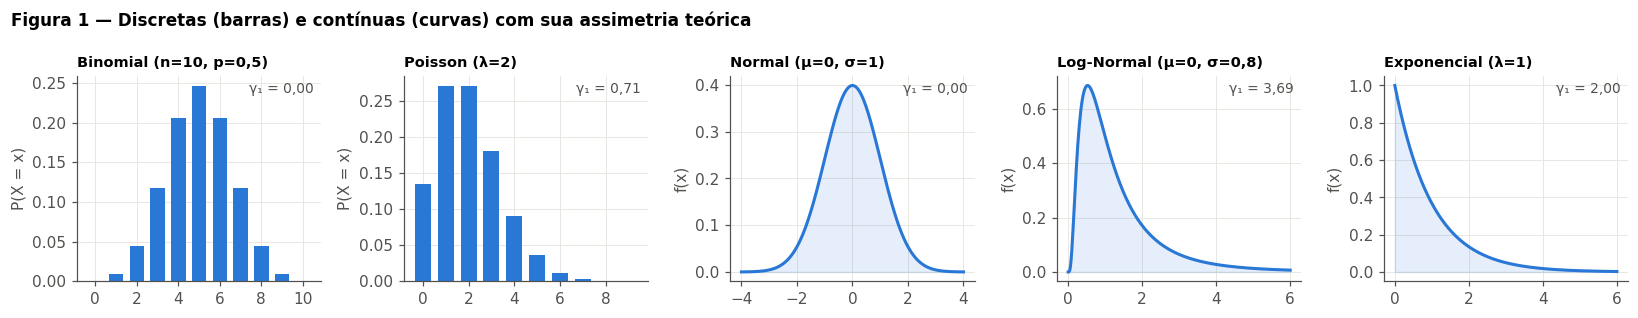

In [19]:
# Painel com a forma de cada modelo e sua assimetria teórica
fig, eixos = plt.subplots(1, 5, figsize=(15, 2.9))
modelos = [
    ("Binomial (n=10, p=0,5)", stats.binom(10, 0.5), np.arange(11), True),
    ("Poisson (λ=2)", stats.poisson(2), np.arange(10), True),
    ("Normal (μ=0, σ=1)", stats.norm(), np.linspace(-4, 4, 300), False),
    ("Log-Normal (μ=0, σ=0,8)", stats.lognorm(0.8), np.linspace(0.001, 6, 300), False),
    ("Exponencial (λ=1)", stats.expon(), np.linspace(0, 6, 300), False),
]
for ax, (nome, dist, x, discreta) in zip(eixos, modelos):
    if discreta:
        ax.bar(x, dist.pmf(x), color=AZUL, width=0.7)
        ax.set_xticks(x[::2])
        ax.set_ylabel("P(X = x)")
    else:
        ax.plot(x, dist.pdf(x), color=AZUL, lw=2)
        ax.fill_between(x, dist.pdf(x), color=AZUL, alpha=0.12)
        ax.set_ylabel("f(x)")
    ax.set_title(nome, fontsize=9.5)
    ax.text(0.97, 0.92, f"γ₁ = {br(float(dist.stats(moments='s')))}", transform=ax.transAxes,
            ha="right", fontsize=9, color=CINZA)
fig.suptitle("Figura 1 — Discretas (barras) e contínuas (curvas) com sua assimetria teórica",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

**Leitura da Figura 1.** Binomial com $p = 0{,}5$ e Normal são simétricas ($\gamma_1 = 0$). Poisson, Log-Normal e Exponencial têm cauda à direita. A da Exponencial é fixa ($\gamma_1 = 2$); a da Log-Normal cresce rapidamente com $\sigma$. Na seção 3, comparamos a assimetria observada em cada variável do navio com esses valores para descartar ou manter um modelo.

## 3. Dados reais do navio × modelos teóricos

### 3.1. Visão geral

A tabela reúne média, mediana, desvio-padrão, assimetria e proporção de zeros das variáveis quantitativas, ao lado do modelo de referência indicado pela teoria.

In [20]:
# Momentos empíricos de cada variável e o modelo de referência sugerido pela teoria
referencia = {
    "Age": "Normal (aproximação)",
    "GroupSize": "Nenhum dos cinco (não é Poisson)",
    **{c: "Zeros + Log-Normal nos positivos" for c in DESPESAS},
    "TotalSpend": "Zeros + Log-Normal nos positivos",
}
linhas = []
for col, modelo in referencia.items():
    x = df_kan19[col]
    linhas.append({
        "Variável": col,
        "Média": br(x.mean()),
        "Mediana": br(x.median()),
        "Desvio-padrão": br(x.std()),
        "Assimetria": br(x.skew()),
        "% de zeros": pct((x == 0).mean()),
        "Modelo de referência": modelo,
    })
display(pd.DataFrame(linhas).set_index("Variável"))

,Média,Mediana,Desvio-padrão,Assimetria,% de zeros,Modelo de referência
Variável,,,,,,
Age,"28,78","27,00","14,35","0,43","2,0%",Normal (aproximação)
GroupSize,"2,04","1,00","1,60","1,89","0,0%",Nenhum dos cinco (não é Poisson)
RoomService,"221,58","0,00","660,80","6,38","65,2%",Zeros + Log-Normal nos positivos
FoodCourt,"451,40","0,00","1.596,28","7,17","63,8%",Zeros + Log-Normal nos positivos
ShoppingMall,"169,95","0,00","597,95","12,77","65,8%",Zeros + Log-Normal nos positivos
Spa,"305,45","0,00","1.125,46","7,72","62,3%",Zeros + Log-Normal nos positivos
VRDeck,"299,09","0,00","1.134,08","7,90","64,4%",Zeros + Log-Normal nos positivos
TotalSpend,"1.447,46","717,00","2.808,28","4,40","41,9%",Zeros + Log-Normal nos positivos


**O que a tabela mostra**

- **Idade** é a única variável quase simétrica (assimetria 0,43; média 28,8 e mediana 27). É a única candidata razoável à Normal.
- **Cada tipo de gasto** tem entre **62% e 66% de zeros** e assimetria entre **6 e 13**, muito acima da Exponencial ($\gamma_1 = 2$). A mediana zero mostra que o passageiro típico não usa a comodidade, enquanto a média é puxada por poucos gastadores altos. Nenhum modelo contínuo isolado descreve essa combinação.
- **`TotalSpend`** reduz os zeros para 41,9%, mas continua muito assimétrico (4,40). A média (1.447) é o dobro da mediana (717).
- **`GroupSize`** é uma contagem com assimetria 1,89. A seção 3.5 mostra por que ela não é Poisson.

Nas seções seguintes, cada variável é examinada contra seu modelo candidato.

### 3.2. `Transported` → Bernoulli e Binomial

Codificando *transportado* = 1 e *não transportado* = 0, a variável é Bernoulli. A proporção observada é a estimativa de $p$.

,Valor
Medida,
Transportados,4.378
Não transportados,4.315
p = P(X = 1),"50,36%"
Média do indicador,"0,5036"
Variância do indicador,"0,2500"
Variância teórica p(1 − p),"0,2500"


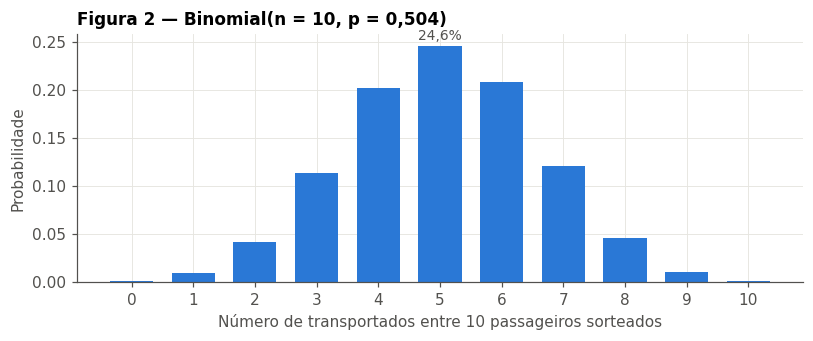

P(exatamente 5) = 24,6% | P(3 a 7) = 89,1% | P(≤ 2 ou ≥ 8) = 10,9%
Média = 5,04 | Variância = 2,50 | Assimetria = -0,005


In [21]:
# Bernoulli: proporção de transportados e conferência de média e variância
y = df_kan19["Transported"].astype(int)
p = y.mean()
display(pd.DataFrame({
    "Medida": ["Transportados", "Não transportados", "p = P(X = 1)", "Média do indicador", "Variância do indicador", "Variância teórica p(1 − p)"],
    "Valor": [br(y.sum(), 0), br((1 - y).sum(), 0), pct(p, 2), br(y.mean(), 4), br(y.var(ddof=0), 4), br(p * (1 - p), 4)],
}).set_index("Medida"))

# Binomial: quantos transportados esperar ao sortear 10 passageiros ao acaso (com reposição)
n = 10
binom = stats.binom(n, p)
k = np.arange(n + 1)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.bar(k, binom.pmf(k), color=AZUL, width=0.7)
for ki in (5,):
    ax.annotate(pct(binom.pmf(ki)), (ki, binom.pmf(ki)), textcoords="offset points", xytext=(0, 4),
                ha="center", fontsize=9, color=CINZA)
ax.set(xticks=k, xlabel="Número de transportados entre 10 passageiros sorteados", ylabel="Probabilidade",
       title="Figura 2 — Binomial(n = 10, p = 0,504)")
fig.tight_layout()
plt.show()
print(f"P(exatamente 5) = {pct(binom.pmf(5))} | P(3 a 7) = {pct(binom.cdf(7) - binom.cdf(2))} | "
      f"P(≤ 2 ou ≥ 8) = {pct(1 - (binom.cdf(7) - binom.cdf(2)))}")
print(f"Média = {br(binom.mean())} | Variância = {br(binom.var())} | Assimetria = {br(float(binom.stats(moments='s')), 3)}")

**Interpretação.**

- **Classes equilibradas:** 4.378 de 8.693 passageiros (**50,36%**) foram transportados. A média do indicador é exatamente essa proporção, e a variância é $p(1-p) \approx 0{,}25$, o valor máximo possível para uma Bernoulli.
- **Consequência para o projeto:** como as classes têm o mesmo tamanho, a acurácia de um modelo preditivo é uma métrica honesta, e o patamar a superar é cerca de 50%.
- **Variação esperada pelo acaso:** em 10 passageiros sorteados ao acaso, o resultado mais provável é 5 transportados (24,6%). Ainda assim, há **89%** de chance de observar entre 3 e 7, e **11%** de cair fora disso. Diferenças de proporção em grupos pequenos (por exemplo, uma família de 4) podem ser puro acaso, o que justifica testes formais na KAN-22.
- **Pressuposto:** a Binomial exige ensaios independentes. Passageiros de um mesmo grupo de viagem tendem a ter o mesmo desfecho, então contagens **dentro de grupos reais** não são Binomiais.

### 3.3. `Age` → Normal

Ajustamos uma Normal com a média e o desvio-padrão da idade e comparamos a curva com o histograma.

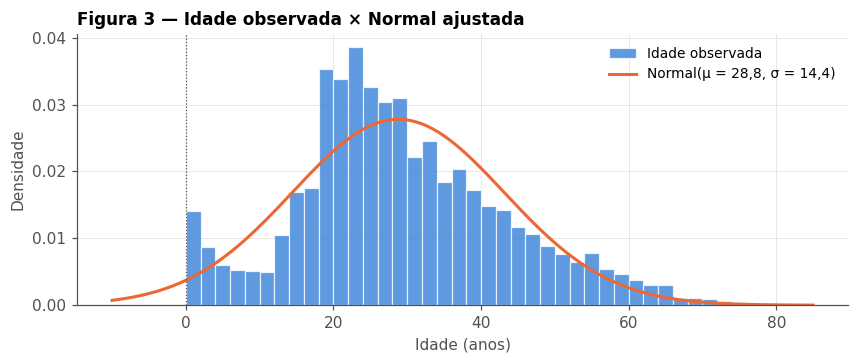

,Observado na base,Previsto pela Normal
Faixa,,
"Média ± 1 desvio (14,4 a 43,1 anos)","71,9%","68,3%"
20 a 40 anos,"55,3%","51,2%"
Menos de 0 ano,"0,0%","2,2%"
60 anos ou mais,"2,9%","1,5%"


Assimetria observada = 0,43 (Normal: 0) | Média = 28,78 | Mediana = 27,00


In [22]:
# Normal ajustada à idade: comparação visual e de probabilidades
idade = df_kan19["Age"]
normal = stats.norm(idade.mean(), idade.std())

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(idade, bins=np.arange(0, 82, 2), density=True, color=AZUL, alpha=0.75, edgecolor="white", linewidth=0.8,
        label="Idade observada")
grade = np.linspace(-10, 85, 400)
ax.plot(grade, normal.pdf(grade), color=LARANJA, lw=2, label=f"Normal(μ = {br(idade.mean(), 1)}, σ = {br(idade.std(), 1)})")
ax.axvline(0, color=CINZA, lw=0.8, ls=":")
ax.set(xlabel="Idade (anos)", ylabel="Densidade", title="Figura 3 — Idade observada × Normal ajustada")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()

display(pd.DataFrame({
    "Faixa": ["Média ± 1 desvio (14,4 a 43,1 anos)", "20 a 40 anos", "Menos de 0 ano", "60 anos ou mais"],
    "Observado na base": [pct(idade.between(normal.mean() - normal.std(), normal.mean() + normal.std()).mean()),
                          pct(idade.between(20, 40).mean()), pct(0), pct((idade >= 60).mean())],
    "Previsto pela Normal": [pct(normal.cdf(normal.mean() + normal.std()) - normal.cdf(normal.mean() - normal.std())),
                             pct(normal.cdf(40) - normal.cdf(20)), pct(normal.cdf(0)), pct(normal.sf(60))],
}).set_index("Faixa"))
print(f"Assimetria observada = {br(idade.skew())} (Normal: 0) | Média = {br(idade.mean())} | Mediana = {br(idade.median())}")

**Interpretação.**

- **Mais concentrada que a Normal:** **71,9%** dos passageiros estão a até 1 desvio-padrão da média, contra 68,3% numa Normal.
- **Formato:** a idade tem formato de sino, mas não é Normal. O pico entre 18 e 30 anos é mais alto que o da curva, a cauda direita é mais longa (assimetria 0,43, média 28,8 > mediana 27), e há um grupo de crianças pequenas que a Normal não captura.
- **Onde a Normal erra:** ela subestima a concentração em adultos jovens (prevê 51,2% entre 20 e 40 anos, a base tem 55,3%) e atribui **2,2%** de probabilidade a idades negativas, que são impossíveis.
- **Consequência para o projeto:**
  - **Médias de idade:** comparar idade média entre transportados e não transportados é seguro com $n \approx 8.700$, porque pelo TLC a **média amostral** é aproximadamente Normal mesmo que a idade individual não seja.
  - **Testes de normalidade:** um teste formal tende a rejeitar a normalidade da idade com uma amostra desse tamanho. Isso será verificado com QQ-plot na KAN-21 e não invalida o uso da média.
- **Ressalvas:** a idade está registrada em anos inteiros, e 2% dos valores foram imputados na KAN-11, o que concentra observações na mediana.

### 3.4. Gastos → zeros + Log-Normal nos valores positivos

Os gastos têm duas partes: uma massa de passageiros com gasto exatamente zero e uma distribuição contínua entre quem gasta. A teoria da seção 2 mostra que Log-Normal e Exponencial não produzem zeros exatos, então as duas partes precisam ser analisadas separadamente.

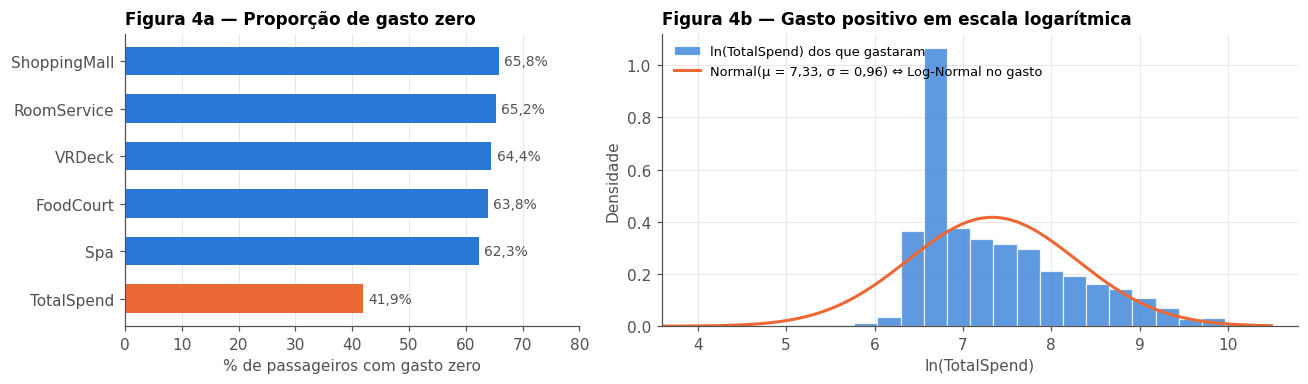

,Observado,Previsto pela Log-Normal
Medida (passageiros com gasto > 0),,
Quantidade,5.049,—
Média,"2.492,13","2.417,20"
Mediana,"1.192,00","1.529,53"
Desvio-padrão,"3.312,59","2.958,02"
Assimetria,"3,70","5,50"


Assimetria de ln(gasto positivo) = -0,35 (uma Log-Normal perfeita teria 0)
Gastadores entre 735 e 945 u.m.: 25,2%; destes, 96,2% são da Terra


,Passageiros,Mediana,Média
HomePlanet,,,
Earth,2.949,826,1.080
Europa,1.128,5.100,6.638
Mars,972,1.590,1.967


In [23]:
# Parte 1: quem gasta. Parte 2: quanto gasta quem gasta (Log-Normal nos positivos)
positivos = df_kan19.loc[df_kan19["TotalSpend"] > 0, "TotalSpend"]
log_pos = np.log(positivos)
mu, sigma = log_pos.mean(), log_pos.std(ddof=0)          # estimadores de máxima verossimilhança
lognormal = stats.lognorm(s=sigma, scale=np.exp(mu))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})
zeros = (df_kan19[DESPESAS + ["TotalSpend"]] == 0).mean().sort_values()
ax1.barh(zeros.index, zeros.values * 100, color=[LARANJA if c == "TotalSpend" else AZUL for c in zeros.index], height=0.6)
for i, v in enumerate(zeros.values):
    ax1.text(v * 100 + 1, i, pct(v), va="center", fontsize=9, color=CINZA)
ax1.set(xlim=(0, 80), xlabel="% de passageiros com gasto zero", title="Figura 4a — Proporção de gasto zero")
ax1.grid(axis="y", visible=False)

ax2.hist(log_pos, bins=40, density=True, color=AZUL, alpha=0.75, edgecolor="white", linewidth=0.8,
         label="ln(TotalSpend) dos que gastaram")
grade = np.linspace(log_pos.min(), log_pos.max(), 300)
ax2.plot(grade, stats.norm(mu, sigma).pdf(grade), color=LARANJA, lw=2,
         label=f"Normal(μ = {br(mu)}, σ = {br(sigma)}) ⇔ Log-Normal no gasto")
ax2.set(xlim=(np.percentile(log_pos, 0.5) - 0.5, log_pos.max() + 0.3),  # oculta poucos gastos de 1 a 50 u.m.
        xlabel="ln(TotalSpend)", ylabel="Densidade", title="Figura 4b — Gasto positivo em escala logarítmica")
ax2.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
plt.show()

display(pd.DataFrame({
    "Medida (passageiros com gasto > 0)": ["Quantidade", "Média", "Mediana", "Desvio-padrão", "Assimetria"],
    "Observado": [br(len(positivos), 0), br(positivos.mean()), br(positivos.median()), br(positivos.std(ddof=0)), br(stats.skew(positivos))],
    "Previsto pela Log-Normal": ["—", br(lognormal.mean()), br(lognormal.median()), br(lognormal.std()), br(float(lognormal.stats(moments="s")))],
}).set_index("Medida (passageiros com gasto > 0)"))
print(f"Assimetria de ln(gasto positivo) = {br(stats.skew(log_pos))} (uma Log-Normal perfeita teria 0)")

# O pico em ln ≈ 6,7 (735 a 945 u.m.): de onde vêm esses passageiros?
gastadores = df_kan19[df_kan19["TotalSpend"] > 0]
no_pico = gastadores["TotalSpend"].between(735, 945)
print(f"Gastadores entre 735 e 945 u.m.: {pct(no_pico.mean())}; destes, {pct((gastadores.loc[no_pico, 'HomePlanet'] == 'Earth').mean())} são da Terra")
display(gastadores.groupby("HomePlanet")["TotalSpend"].agg(
    Passageiros=lambda s: br(len(s), 0), Mediana=lambda s: br(s.median(), 0), Média=lambda s: br(s.mean(), 0)))

**Interpretação.**

- **Parte 1, quem gasta:**
  - **Por comodidade:** cerca de 2 em cada 3 passageiros não usam cada comodidade (62% a 66% de zeros).
  - **No total:** 41,9% não gastam nada. A KAN-11 mostra a causa: passageiros em criossono e crianças de até 12 anos têm gasto zero por regra.
  - **Como tratar:** essa parte é uma variável **Bernoulli** (`HasSpent`), e sua relação com `Transported` deve ser analisada como proporção ou qui-quadrado.
- **Parte 2, quanto gasta quem gasta:**
  - **No logaritmo:** o histograma tem formato de sino, centrado em $e^{7{,}33} \approx 1.530$ unidades monetárias, que é a mediana prevista pela Log-Normal (a observada é 1.192). A Log-Normal é, portanto, um **modelo de trabalho razoável** para os gastos positivos.
  - **Uma mistura de populações:** a Figura 4b tem um pico estreito em torno de 800 u.m. que a curva não acompanha. **25%** dos gastadores estão entre 735 e 945 u.m., e **96%** deles vêm da **Terra**. A mediana de gasto é 826 u.m. para terráqueos, 1.590 para marcianos e 5.100 para europeus. Os gastos positivos são, na verdade, **três distribuições sobrepostas**, uma por planeta de origem, e uma única Log-Normal resume esse conjunto apenas de forma aproximada.
  - **Na cauda:** o ajuste também não é perfeito. Em escala log há leve assimetria à esquerda (−0,35), e a assimetria real dos gastos (3,70) é menor que a prevista (5,50). Os gastos muito altos são **menos extremos** do que a Log-Normal sugere.
- **Consequência para o projeto:**
  - **Testes:** comparar médias de gasto bruto com teste t é frágil, porque a média é dominada pela cauda. É preferível comparar em escala $\ln(1+X)$, usar a mediana ou um teste não paramétrico (Mann-Whitney). A escolha final é da KAN-22.
  - **Regressão:** gastos em escala log tendem a produzir resíduos mais bem comportados, e `HomePlanet` deve entrar como variável explicativa.
  - **Comparações justas:** comparar gastos entre grupos sem controlar o planeta de origem pode confundir o efeito do planeta com o do grupo.

### 3.5. `GroupSize` → por que não é Poisson (e por que a Exponencial também não se aplica)

`GroupSize` é uma contagem, o que poderia sugerir Poisson. A teoria dá dois critérios objetivos para verificar: a Poisson admite o valor 0, e tem média igual à variância.

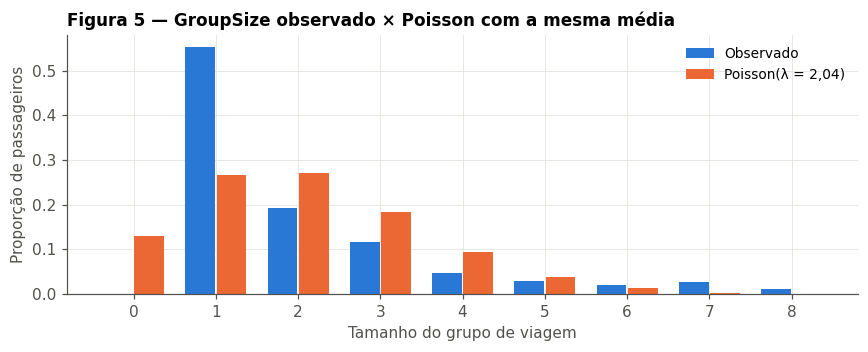

Média = 2,04 | Variância = 2,55 (Poisson exigiria variância = média)
Grupos de tamanho 0: observado 0,0% × Poisson 13,1%
Viajam sozinhos (tamanho 1): observado 55,3% × Poisson 26,6%


In [24]:
# Distribuição observada de GroupSize contra uma Poisson com a mesma média
g = df_kan19["GroupSize"]
poisson = stats.poisson(g.mean())
k = np.arange(0, 9)
obs = g.value_counts(normalize=True).reindex(k, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(k - 0.19, obs.values, width=0.36, color=AZUL, label="Observado")
ax.bar(k + 0.19, poisson.pmf(k), width=0.36, color=LARANJA, label=f"Poisson(λ = {br(g.mean())})")
ax.set(xticks=k, xlabel="Tamanho do grupo de viagem", ylabel="Proporção de passageiros",
       title="Figura 5 — GroupSize observado × Poisson com a mesma média")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
print(f"Média = {br(g.mean())} | Variância = {br(g.var())} (Poisson exigiria variância = média)")
print(f"Grupos de tamanho 0: observado {pct(0)} × Poisson {pct(poisson.pmf(0))}")
print(f"Viajam sozinhos (tamanho 1): observado {pct(obs[1])} × Poisson {pct(poisson.pmf(1))}")

**Interpretação.**

- **Por que não é Poisson:** os dois critérios falham.
  - Um grupo de viagem tem **no mínimo 1** pessoa, mas a Poisson atribui **13,1%** de probabilidade ao tamanho 0.
  - A **variância (2,55) é maior que a média (2,04)**, ou seja, há superdispersão.
  - O padrão real também é diferente: **55%** viajam sozinhos (a Poisson prevê 26,6%), e há mais grupos grandes do que o modelo prevê. Isso decorre do processo que forma os grupos (famílias, amigos), não de eventos independentes a uma taxa constante.
- **Consequência para o projeto:** `GroupSize` deve ser tratada como **ordinal ou categórica** (sozinho × grupo, ou faixas de tamanho) em testes qui-quadrado, e não modelada como contagem Poisson.
- **Exponencial:** não há nenhuma variável de tempo de espera ou duração na base, então ela não tem aplicação aqui. Ser positiva e assimétrica não basta: os gastos têm assimetria entre 4 e 13, muito acima da assimetria fixa de 2 da Exponencial, e têm massa em zero, que ela não produz.

## 4. Implicações para as próximas etapas (KAN-20 a KAN-22)

| Variável | Modelo de referência | Evidência desta etapa | Consequência para a análise |
|---|---|---|---|
| `Transported` | Bernoulli ($p = 0{,}504$) | Variância = $p(1-p)$; classes equilibradas | Comparar **proporções** entre grupos (qui-quadrado, teste de proporções); acurácia é métrica válida |
| `Age` | Normal (aproximação) | Assimetria 0,43; 2,2% de massa em idades negativas | **Teste t** para médias é seguro pelo TLC; confirmar o formato com QQ-plot (KAN-21) |
| Gastos e `TotalSpend` | Bernoulli (gastou?) + Log-Normal (quanto?) | 41,9% de zeros; ln(gasto) quase simétrico | Separar `HasSpent` (qui-quadrado) do valor; usar $\ln(1+X)$, mediana ou **Mann-Whitney** |
| `GroupSize` | Nenhum dos cinco | Sem zeros; variância > média | Tratar como **categórica/ordinal** |

### Ligação com a Aula 3: distribuição dos dados × distribuição da média

O **Teorema do Limite Central** afirma que, para observações independentes com variância finita, a **média amostral** $\bar{X}$ tem distribuição aproximadamente Normal para $n$ grande, com média $\mu$ e erro-padrão $\sigma/\sqrt{n}$ (estimado por $s/\sqrt{n}$). Isso explica por que um teste de médias pode ser usado com a idade mesmo sem os dados individuais serem Normais. Para os gastos, a cauda pesada exige amostras bem maiores para a aproximação ser boa, e a média continua sendo pouco representativa do passageiro típico.

**Diferença essencial:** o **desvio-padrão** mede a variação entre passageiros; o **erro-padrão** mede a precisão da média estimada.

### Limitações

- **Imputação:** os momentos foram calculados na base tratada da KAN-12, que inclui ~2% de valores imputados por variável, o que tende a reduzir a variância.
- **Dependência entre passageiros:** passageiros do mesmo grupo não são independentes, um pressuposto da Binomial e do TLC.
- **Ajustes ainda informais:** as comparações desta etapa são descritivas. A confirmação formal (QQ-plot, Shapiro-Wilk, Kolmogorov-Smirnov) fica para a KAN-21.

## 5. Síntese Metodológica do Fichamento (`KAN-19`)

1. **Fundamentos registrados:** função de probabilidade $P(X=x)$ para variáveis discretas e função densidade $f(x)$ para contínuas, com as propriedades de **média, variância e assimetria** dos cinco modelos (Binomial, Poisson, Normal, Log-Normal e Exponencial) consolidadas no quadro da seção 2.1.
2. **`Transported` é Bernoulli** com $p = $ **50,36%** (4.378 de 8.693). As classes equilibradas tornam a proporção a medida central de comparação e fixam em ~50% o patamar mínimo para um modelo preditivo.
3. **`Age` é aproximadamente Normal só no formato geral:** assimetria **0,43**, **55,3%** entre 20 e 40 anos contra **51,2%** previstos, e **2,2%** de probabilidade atribuída a idades negativas. Testes de médias são válidos pelo TLC.
4. **Gastos combinam massa em zero e cauda longa:** **41,9%** com `TotalSpend` = 0 (62% a 66% por comodidade) e assimetria de **4,4 a 12,8**. Entre os positivos, a **Log-Normal** ($\mu = 7{,}33$, $\sigma = 0{,}96$ no log) é um modelo de trabalho adequado, com cauda real mais leve que a prevista (assimetria **3,70** contra **5,50**). O desvio vem de uma mistura por planeta de origem: **96%** do pico em torno de 800 u.m. são terráqueos (mediana **826**, contra **5.100** em Europa).
5. **Poisson e Exponencial não se aplicam:** `GroupSize` não tem zeros e é superdispersa (variância **2,55** > média **2,04**); não existem tempos de espera na base.
6. **Recomendação para a KAN-22:** proporções e qui-quadrado para desfechos binários, teste t para a idade, e escala log ou métodos não paramétricos para gastos.

## 6. Referências

- **Handouts Aula 1 — Distribuições de Probabilidade**, Prof. Adiel Filho: variáveis aleatórias, função de probabilidade e densidade, Bernoulli, Binomial, Poisson, Normal e Exponencial.
- **Handouts Aula 1 — Resumo de Probabilidade (rev. 01)**, Prof. Adiel Filho: espaço amostral, eventos e axiomas.
- **Handouts Aula 3 — Distribuições Amostrais e Estimação**, Prof. Adiel Filho: distribuição amostral, Teorema do Limite Central e erro-padrão.
- **Log-Normal (complemento):** NIST/SEMATECH, *e-Handbook of Statistical Methods*, seção 1.3.6.6.9 — https://www.itl.nist.gov/div898/handbook/eda/section3/eda3669.htm
- **Dados:** `docs/dicionario_dados.md` e `data/processed/spaceship_titanic_clean.csv` (KAN-12) do repositório da equipe.

---
# 4. Testes de Hipóteses e ANOVA

**Objetivo Analítico (T3):** Testes de Hipóteses ou ANOVA: formulação prévia de H0/H1, relação entre categorias (Qui-Quadrado e V de Cramér), comparação entre 2 grupos (Welch e Mann-Whitney), comparação entre >2 grupos (ANOVA de Welch e Kruskal-Wallis com post-hoc), p-valor, tamanho de efeito e tradução prática para o cliente.  
**Tickets Jira:** [KAN-24](https://megamatic.atlassian.net/browse/KAN-24) · [KAN-25](https://megamatic.atlassian.net/browse/KAN-25) · [KAN-26](https://megamatic.atlassian.net/browse/KAN-26) · [KAN-27](https://megamatic.atlassian.net/browse/KAN-27) · [KAN-28](https://megamatic.atlassian.net/browse/KAN-28)  
**Notebooks Consolidados:** `notebooks/04_testes_hipoteses_anova.ipynb`

# KAN-24 - Hipoteses Estatisticas Antes dos Testes

**Projeto:** Spaceship Titanic - Analise Estatistica  
**Base analitica:** `data/processed/spaceship_titanic_clean.csv`

## Objetivo desta etapa

Antes de executar qualquer teste inferencial, registramos as perguntas, as hipoteses e a regra de decisao. Esta ordem e importante: se uma hipotese fosse escolhida depois de observar os resultados, poderiamos favorecer explicacoes que parecem significativas apenas por acaso. Essa pratica e conhecida como *p-hacking*.

Esta entrega **nao calcula testes, valores-p, intervalos de confianca, tamanhos de efeito ou conclusoes**. Esses resultados pertencem as tarefas KAN-25, KAN-26 e KAN-27.

## 1. Preparacao reproduzivel

Usaremos apenas a base de treinamento tratada no KAN-12. Ela contem o desfecho observado `Transported` e as variaveis derivadas, incluindo `TotalSpend`. A base `test.csv` do Kaggle nao possui o desfecho e, por isso, nao serve para estes testes de hipoteses.

In [25]:
from pathlib import Path

import numpy as np
import pandas as pd

# Permite executar o notebook a partir da raiz do projeto ou da pasta notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'spaceship_titanic_clean.csv'
alpha = 0.05

df = pd.read_csv(DATA_PATH)

print("Base carregada: data/processed/spaceship_titanic_clean.csv")
print(f'Dimensao: {df.shape[0]:,} passageiros x {df.shape[1]} colunas')
print(f'Nivel de significancia pre-especificado: alpha = {alpha:.2f}')

Base carregada: data/processed/spaceship_titanic_clean.csv
Dimensao: 8,693 passageiros x 22 colunas
Nivel de significancia pre-especificado: alpha = 0.05


## 2. Contrato dos dados para a inferencia

Antes de formular testes, confirmamos que as variaveis previstas existem, nao possuem ausencias e apresentam as categorias esperadas. Esta verificacao nao e um teste de hipotese: e uma protecao contra analisar a base errada ou uma versao incompleta dela.

In [26]:
REQUIRED_COLUMNS = {'HomePlanet', 'CryoSleep', 'TotalSpend', 'Transported'}
EXPECTED_PLANETS = {'Earth', 'Europa', 'Mars'}

missing_columns = REQUIRED_COLUMNS - set(df.columns)
if missing_columns:
    raise ValueError(f'Colunas obrigatorias ausentes: {sorted(missing_columns)}')

null_counts = df[list(REQUIRED_COLUMNS)].isna().sum()
if (null_counts > 0).any():
    raise ValueError(f'Valores ausentes nas variaveis analiticas: {null_counts[null_counts > 0].to_dict()}')

transported_categories = set(df['Transported'].unique())
if len(transported_categories) != 2:
    raise ValueError(f'Transported deve ter duas categorias; encontrado: {transported_categories}')

observed_planets = set(df['HomePlanet'].unique())
if observed_planets != EXPECTED_PLANETS:
    raise ValueError(
        f'Categorias inesperadas em HomePlanet. Esperado: {EXPECTED_PLANETS}; observado: {observed_planets}'
    )

print('Contrato validado: as quatro variaveis estao completas e disponiveis.')
print('\nContagem por HomePlanet:')
display(df['HomePlanet'].value_counts().rename_axis('HomePlanet').to_frame('n'))
print('\nContagem por CryoSleep:')
display(df['CryoSleep'].value_counts().rename_axis('CryoSleep').to_frame('n'))
print('\nContagem por Transported:')
display(df['Transported'].value_counts().rename_axis('Transported').to_frame('n'))

Contrato validado: as quatro variaveis estao completas e disponiveis.

Contagem por HomePlanet:


,n
HomePlanet,
Earth,4715
Europa,2174
Mars,1804



Contagem por CryoSleep:


,n
CryoSleep,
False,5558
True,3135



Contagem por Transported:


,n
Transported,
True,4378
False,4315


## 3. Conceitos essenciais

Uma **hipotese nula** ($H_0$) representa a ausencia de associacao ou diferenca. A **hipotese alternativa** ($H_1$) representa uma associacao ou diferenca que desejamos investigar.

O nivel de significancia foi fixado em $\alpha = 0{,}05$. Isso limita a 5% o risco planejado de rejeitar $H_0$ quando ela e verdadeira, o chamado **erro do tipo I**. Depois que os testes forem executados, a regra sera:

- se $p < 0{,}05$, rejeitar $H_0$;
- se $p \geq 0{,}05$, nao rejeitar $H_0$.

O valor-p nao e a probabilidade de $H_0$ ser verdadeira. Ele mede quao compativeis os dados observados seriam com um modelo em que $H_0$ fosse verdadeira. Por isso, **nao rejeitar** $H_0$ nao prova igualdade entre os grupos: significa apenas que os dados nao forneceram evidencia suficiente contra ela sob este criterio.

## 4. Pergunta 1 - Planeta de origem e teletransporte

**Pergunta de negocio:** a proporcao de passageiros teletransportados varia conforme o planeta de origem?

- **Variaveis:** `HomePlanet` (Earth, Europa, Mars) e `Transported` (True, False).
- **Unidade de analise:** um passageiro.
- **$H_0$:** `HomePlanet` e `Transported` sao independentes; a distribuicao de `Transported` e a mesma nos planetas de origem.
- **$H_1$:** existe associacao entre `HomePlanet` e `Transported`; pelo menos uma distribuicao/proporcao difere.
- **Teste previsto:** qui-quadrado de independencia, na KAN-25.

O qui-quadrado e adequado porque ambas as variaveis sao categoricas. Ele compara as frequencias observadas em uma tabela de contingencia com as frequencias que seriam esperadas se nao houvesse associacao.

## 5. Pergunta 2 - Criossomo e teletransporte

**Pergunta de negocio:** a proporcao de passageiros teletransportados varia entre quem estava ou nao em criossomo?

- **Variaveis:** `CryoSleep` (True, False) e `Transported` (True, False).
- **Unidade de analise:** um passageiro.
- **$H_0$:** `CryoSleep` e `Transported` sao independentes; a distribuicao de `Transported` e a mesma nos dois estados de criossomo.
- **$H_1$:** existe associacao entre `CryoSleep` e `Transported`; as distribuicoes/proporcoes diferem.
- **Teste previsto:** qui-quadrado de independencia, na KAN-25.

Tambem temos duas variaveis categoricas. O teste respondera se a diferenca observada nas frequencias e grande demais para ser atribuida apenas a variacao amostral sob a hipotese de independencia.

## 6. Pergunta 3 - Gasto total e teletransporte

**Pergunta de negocio:** passageiros teletransportados e nao teletransportados apresentam diferenca no gasto total a bordo?

- **Variaveis:** `TotalSpend` (quantitativa continua/discreta truncada em zero) e `Transported` (categorica binaria: True vs False).
- **Unidade de analise:** um passageiro.
- **Objetivo analitico:** comparar o comportamento de consumo entre quem foi e nao foi teletransportado. Sob a otica economica e financeira do negocio, o foco primario esta na diferenca de volume medio gasto ($\mu$), enquanto a otica distributiva analisa a tendencia central e ordenacao dos postos frente a forte assimetria e presenca massiva de zeros.

**Hierarquia de testes e hipoteses pre-registradas:**

1. **Teste Principal (orientador da conclusao de negocio): Teste t de Welch**
   - **Foco:** diferenca entre as medias populacionais ($\mu_1 - \mu_2$).
   - **$H_0$ (nula):** $\mu_{\text{Transported=True}} = \mu_{\text{Transported=False}}$ (o gasto medio a bordo e igual entre passageiros teletransportados e nao teletransportados).
   - **$H_1$ (alternativa):** $\mu_{\text{Transported=True}} \neq \mu_{\text{Transported=False}}$ (o gasto medio a bordo difere entre os dois grupos).
   - **Justificativa metodologica:** com $N = 8.693$ observacoes (mais de 4.300 por grupo), o Teorema Central do Limite (TCL) assegura a normalidade assintotica da distribuicao amostral das medias. A versao de Welch (`scipy.stats.ttest_ind(..., equal_var=False)`) e rigorosamente apropriada por nao exigir homocedasticidade (igualdade de variancias), acomodando eventuais dispersoes desiguais apontadas pelo Teste de Levene.

2. **Teste Complementar (robustez nao parametrica de postos): Teste Mann-Whitney U**
   - **Foco:** dominancia estocastica e diferenca na distribuicao de postos / medianas.
   - **$H_0$ (nula):** $P(X_{\text{True}} > Y_{\text{False}}) = P(Y_{\text{False}} > X_{\text{True}})$ (as distribuicoes de gastos nos dois grupos sao estocasticamente iguais).
   - **$H_1$ (alternativa):** $P(X_{\text{True}} > Y_{\text{False}}) \neq P(Y_{\text{False}} > X_{\text{True}})$ (uma distribuicao tende a apresentar postos sistematicamente maiores que a outra).
   - **Justificativa metodologica:** `TotalSpend` possui concentracao acentuada de valores nulos (passageiros que nao consumiram) e assimetria positiva pronunciada. O teste de Mann-Whitney (`scipy.stats.mannwhitneyu`) atua como checagem de robustez ordinal para confirmar se a conclusao da media se mantem no nivel dos postos ou se decorre apenas da cauda extrema de altos gastadores.

- **Medidas complementares de efeito e precisao (na KAN-26):**
  - Diferenca absoluta de medias ($\bar{x}_1 - \bar{x}_2$) acompanhada de Intervalo de Confianca de 95% via Welch-Satterthwaite.
  - Tamanho do efeito: $d$ de Cohen para a diferenca parametrica e $r$ de Rosenthal ($r = \frac{Z}{\sqrt{N}}$) ou delta de Cliff para o teste nao parametrico.

## 7. Pergunta 4 - Gasto total e planeta de origem

**Pergunta de negocio:** o gasto total a bordo difere entre os passageiros originarios de Earth, Europa e Mars?

- **Variaveis:** `TotalSpend` (quantitativa) e `HomePlanet` (categorica com 3 niveis: Earth, Europa, Mars).
- **Unidade de analise:** um passageiro.
- **Objetivo analitico:** verificar se a origem do passageiro influencia o volume financeiro gasto na viagem espacial. Para direcionamento estrategico, o parametro central de decisao e a media de gastos por planeta ($\mu_{\text{Earth}}, \mu_{\text{Europa}}, \mu_{\text{Mars}}$), apoiada pela analise nao parametrica de postos.

**Hierarquia de testes e hipoteses pre-registradas:**

1. **Teste Global Principal (orientador da conclusao de negocio): ANOVA de Welch (One-Way Welch ANOVA)**
   - **Foco:** igualdade simultanea das medias populacionais entre os 3 planetas.
   - **$H_0$ (nula):** $\mu_{\text{Earth}} = \mu_{\text{Europa}} = \mu_{\text{Mars}}$ (as medias populacionais de gasto total sao identicas entre os tres planetas de origem).
   - **$H_1$ (alternativa):** pelo menos uma media populacional difere das demais ($\exists\, i \neq j \text{ tal que } \mu_i \neq \mu_j$).
   - **Justificativa metodologica:** amostras expressivas ($n_{\text{Earth}} = 4.715$, $n_{\text{Europa}} = 2.174$, $n_{\text{Mars}} = 1.804$) garantem estabilidade amostral via TCL. A ANOVA de Welch (`scipy.stats` ou `pingouin.welch_anova`) relaxa o pressuposto de igualdade de variancias (homocedasticidade), sendo a escolha padrao diante da esperada heterocedasticidade verificada pelo Teste de Levene.

2. **Teste Global Complementar (robustez de postos): Kruskal-Wallis (H)**
   - **Foco:** igualdade das distribuicoes de postos entre os 3 grupos independentes.
   - **$H_0$ (nula):** as distribuicoes de postos de `TotalSpend` sao identicas entre Earth, Europa e Mars.
   - **$H_1$ (alternativa):** pelo menos um planeta apresenta dominancia estocastica nos postos de gasto em relacao aos demais.
   - **Justificativa metodologica:** avalia se a heterogeneidade persiste em uma escala puramente ordinal e livre de distribuicao, minimizando a influencia de passageiros com consumos atipicos.

**Protocolo pre-estabelecido de comparacoes multiplas pos-hoc (Post-Hoc):**

Se a hipotese nula global for rejeitada no teste principal ($p < 0{,}05$), sera necessario determinar exatamente quais pares de planetas apresentam divergencia estatistica:
- **Metodo Principal Pos-Hoc:** **Teste de Games-Howell** para comparacoes pareadas (Earth vs Europa, Earth vs Mars, Europa vs Mars).
  - *Criterio:* o Games-Howell e o teste pos-hoc indicado para ANOVA de Welch, pois nao assume variancias iguais nem tamanhos amostrais identicos, controlando rigorosamente a taxa de erro tipo I por familia (*Family-Wise Error Rate - FWER*) em $\alpha = 0{,}05$.
- **Metodo Complementar Pos-Hoc:** **Teste de Dunn** com correcao de **Bonferroni** (ou **Holm-Bonferroni**) sobre os postos caso o aprofundamento decorra do Kruskal-Wallis.
- **Tamanho do Efeito da ANOVA (na KAN-27):** medido por Eta ao Quadrado ($\eta^2 = \frac{SS_{\text{between}}}{SS_{\text{total}}}$) ou Omega ao Quadrado ($\omega^2$) para quantificar a proporcao da variancia de gastos explicada pelo planeta de origem.

# KAN-25 - Associacao entre Variaveis Categoricas

Nesta etapa testamos se `HomePlanet`, `CryoSleep` e `VIP` estao associados a `Transported`. O objetivo nao e estabelecer causalidade: os dados sao observacionais. Buscamos apenas evidencias de que as distribuicoes de teletransporte diferem entre as categorias de cada atributo.

## 9. O que o teste qui-quadrado compara?

Uma tabela de contingencia organiza as **frequencias observadas** para duas variaveis categoricas. Sob a hipotese nula de independencia, cada celula teria uma **frequencia esperada** calculada a partir dos totais de sua linha e coluna. O qui-quadrado de Pearson soma os desvios padronizados entre valores observados e esperados.

Quanto maior $\chi^2$, maior a discrepancia entre a tabela observada e o que seria esperado se nao houvesse associacao. O valor-p informa se uma discrepancia daquele tamanho, ou maior, seria incomum sob $H_0$.

### Pressuposto

Para usar a aproximacao qui-quadrado, verificaremos se **todas as frequencias esperadas sao maiores que 5**. Tambem reportaremos o V de Cramer, porque uma associacao pode ser estatisticamente significativa numa amostra grande e ainda assim ter pequena importancia pratica.

Neste projeto, classificaremos o V de Cramer como fraco se for menor que 0,10; medio de 0,10 a menor que 0,30; e forte a partir de 0,30. Esses limiares sao uma convencao de comunicacao do projeto, nao uma lei universal.

In [27]:
from scipy.stats import chi2_contingency


def classificar_forca_cramers_v(cramers_v: float) -> str:
    """Classifica a magnitude pratica segundo a convencao do projeto."""
    if cramers_v < 0.10:
        return 'Fraca'
    if cramers_v < 0.30:
        return 'Media'
    return 'Forte'


def formatar_valor_p(p_value: float) -> str:
    """Evita apresentar subfluxo numerico como probabilidade exatamente nula."""
    return 'p < 1e-300' if p_value == 0 else f'p = {p_value:.3e}'


def analisar_associacao_categorica(
    data: pd.DataFrame,
    predictor: str,
    outcome: str = 'Transported',
    alpha: float = 0.05,
) -> dict:
    """Executa o qui-quadrado de Pearson e calcula o V de Cramer."""
    observed = pd.crosstab(data[predictor], data[outcome])
    result = chi2_contingency(observed, correction=False)

    expected = pd.DataFrame(
        result.expected_freq,
        index=observed.index,
        columns=observed.columns,
    )
    n = observed.to_numpy().sum()
    min_dimension = min(observed.shape[0] - 1, observed.shape[1] - 1)
    cramers_v = np.sqrt(result.statistic / (n * min_dimension))
    min_expected = float(expected.to_numpy().min())
    assumption_met = min_expected > 5
    decision = 'Rejeitar H0' if result.pvalue < alpha else 'Nao rejeitar H0'

    summary = pd.DataFrame(
        [
            {
                'variavel': predictor,
                'chi2': result.statistic,
                'df': result.dof,
                'p_value': result.pvalue,
                'n': n,
                'cramers_v': cramers_v,
                'forca_pratica': classificar_forca_cramers_v(cramers_v),
                'min_frequencia_esperada': min_expected,
                'pressuposto_atendido': assumption_met,
                'decisao': decision,
            }
        ]
    )

    return {
        'observed': observed,
        'expected': expected,
        'summary': summary,
    }

In [28]:
PREDICTORS_CATEGORICOS = ['HomePlanet', 'CryoSleep', 'VIP']
analises_categoricas = {
    predictor: analisar_associacao_categorica(df, predictor, alpha=alpha)
    for predictor in PREDICTORS_CATEGORICOS
}

for predictor, analysis in analises_categoricas.items():
    row = analysis['summary'].iloc[0]
    print(f'\n## {predictor} x Transported')
    print('\nFrequencias observadas:')
    display(analysis['observed'])
    print('\nFrequencias esperadas sob H0 de independencia:')
    display(analysis['expected'].round(2))
    print(
        f"Pressuposto: menor frequencia esperada = {row['min_frequencia_esperada']:.2f}; "
        f"todas > 5? {row['pressuposto_atendido']}"
    )
    print(
        f"Qui-quadrado de Pearson: chi2({int(row['df'])}) = {row['chi2']:.2f}, "
        f"{formatar_valor_p(row['p_value'])}"
    )
    print(
        f"V de Cramer = {row['cramers_v']:.3f} ({row['forca_pratica']}); "
        f"decisao com alpha = {alpha:.2f}: {row['decisao']}."
    )


## HomePlanet x Transported

Frequencias observadas:


Transported,False,True
HomePlanet,,
Earth,2719,1996
Europa,738,1436
Mars,858,946



Frequencias esperadas sob H0 de independencia:


Transported,False,True
HomePlanet,,
Earth,2340.41,2374.59
Europa,1079.12,1094.88
Mars,895.46,908.54


Pressuposto: menor frequencia esperada = 895.46; todas > 5? True
Qui-quadrado de Pearson: chi2(2) = 338.82, p = 2.663e-74
V de Cramer = 0.197 (Media); decisao com alpha = 0.05: Rejeitar H0.

## CryoSleep x Transported

Frequencias observadas:


Transported,False,True
CryoSleep,,
False,3734,1824
True,581,2554


... (3 outputs left out)

Transported,False,True
VIP,,
False,4192,4302
True,123,76



Frequencias esperadas sob H0 de independencia:


Transported,False,True
VIP,,
False,4216.22,4277.78
True,98.78,100.22


Pressuposto: menor frequencia esperada = 98.78; todas > 5? True
Qui-quadrado de Pearson: chi2(1) = 12.07, p = 5.126e-04
V de Cramer = 0.037 (Fraca); decisao com alpha = 0.05: Rejeitar H0.


## 10. Interpretacao das tres associacoes

Em cada analise, se $p < \alpha$, rejeitamos a hipotese de independencia e concluimos que ha evidencia estatistica de associacao na amostra. O V de Cramer responde outra pergunta: **quao forte e essa associacao na pratica?**

Para facilitar a leitura, a proxima tabela consolida os resultados. Ela deve ser interpretada em conjunto com as tabelas observadas: o qui-quadrado identifica a discrepancia global, mas as proporcoes por categoria mostram a direcao descritiva dessa diferenca.

In [29]:
resumo_kan25 = pd.concat(
    [analysis['summary'] for analysis in analises_categoricas.values()],
    ignore_index=True,
).rename(
    columns={
        'variavel': 'Variavel',
        'chi2': 'Qui-quadrado',
        'df': 'Graus de liberdade',
        'p_value': 'Valor-p',
        'n': 'N',
        'cramers_v': 'V de Cramer',
        'forca_pratica': 'Forca pratica',
        'min_frequencia_esperada': 'Menor frequencia esperada',
        'pressuposto_atendido': 'Pressuposto atendido',
        'decisao': 'Decisao',
    }
)

display(
    resumo_kan25.style.format(
        {
            'Qui-quadrado': '{:.2f}',
            'Valor-p': '{:.3e}',
            'V de Cramer': '{:.3f}',
            'Menor frequencia esperada': '{:.2f}',
        }
    )
)

,Variavel,Qui-quadrado,Graus de liberdade,Valor-p,N,V de Cramer,Forca pratica,Menor frequencia esperada,Pressuposto atendido,Decisao
0,HomePlanet,338.82,2,2.663e-74,8693,0.197,Media,895.46,True,Rejeitar H0
1,CryoSleep,1897.71,1,0.000e+00,8693,0.467,Forte,1556.14,True,Rejeitar H0
2,VIP,12.07,1,5.126e-04,8693,0.037,Fraca,98.78,True,Rejeitar H0


### Sintese metodologica

Os tres testes usam a mesma base e a mesma regra de decisao, mas cada um compara categorias diferentes. Como a base tem milhares de passageiros, valores-p muito pequenos sao possiveis mesmo quando o V de Cramer indica uma associacao fraca. Por isso, a conclusao do projeto sempre deve trazer as duas dimensoes: a evidencia estatistica pelo valor-p e a magnitude pratica pelo V de Cramer.

Nenhum destes testes demonstra que planeta de origem, criossomo ou condicao VIP causem o teletransporte. Eles descrevem associacoes na amostra observada; explicacoes causais exigiriam desenho de estudo e controle de fatores de confusao que esta base observacional nao fornece.

# KAN-26 - Comparacao de Gastos por Teletransporte (TotalSpend vs Transported)

Nesta etapa investigamos se o volume financeiro gasto a bordo difere de maneira estatisticamente significante entre passageiros teletransportados (`Transported = True`) e nao teletransportados (`Transported = False`).

## 11. Fundamentacao Metodologica para Comparacao de Gastos

A variavel `TotalSpend` representa o somatorio de despesas em servicos opcionais (`RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck`). Conforme diagnosticado na preparacao dos dados, ela possui duas propriedades criticas:
1. **Inflacao de zeros (*zero-inflation*):** aproximadamente metade da tripulacao possui gasto exatamente igual a zero (passageiros em criossomo ou que nao utilizaram servicos pagos);
2. **Forte assimetria positiva (*right-skewed*):** os passageiros que consumiram concentram-se em faixas baixas e moderadas, com uma cauda longa de super-gastadores.

### Por que o Teste t de Student tradicional e rejeitado?
O Teste $t$ de Student independente pressupoe homocedasticidade (igualdade de variancias populacionais, $\sigma_1^2 = \sigma_2^2$). Em distribuicoes com caudas longas e massas desiguais, essa premissa e frequentemente violada. Para checar formalmente esse pressuposto, aplicamos o **Teste de Levene centrado na mediana (Brown-Forsythe)**, cuja formulacao e robusta contra assimetrias severas.

### O papel do Teorema Central do Limite (TCL) e o Teste t de Welch
Mesmo com dados brutos nao normais, o Teorema Central do Limite assegura que a distribuicao amostral das medias $(\bar{X}_1 - \bar{X}_2)$ converge para a normalidade para tamanhos amostrais expressivos ($n_1 = 4.315$, $n_2 = 4.378$, totalizando $N = 8.693$). 

O **Teste $t$ de Welch** (`scipy.stats.ttest_ind(..., equal_var=False)`) e adotado como o **teste principal orientador da conclusao**:
- Ele nao assume variancias iguais e calcula o erro padrao com as variancias amostrais individuais:
  $$SE = \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}$$
- Ajusta os graus de liberdade via aproximacao de **Welch-Satterthwaite**;
- Fornece a diferenca em unidades monetarias reais acompanhada de **Intervalo de Confianca de 95%** e tamanho do efeito medido pelo **$d$ de Cohen**.

### Teste Complementar de Postos: Mann-Whitney U
Para verificar se a conclusao sobre medias nao e mero artefato da cauda de altos gastadores, executamos o **Teste Mann-Whitney U** (`scipy.stats.mannwhitneyu`). Ele atua como checagem nao parametrica de dominancia estocastica sobre os postos ordenados (*ranks*), complementado pelo tamanho de efeito $r$ de Rosenthal ($r = \frac{|Z|}{\sqrt{N}}$).

In [30]:
from scipy import stats

# Funcoes analiticas e de efeito para a KAN-26

def calcular_cohen_d(x1: pd.Series, x2: pd.Series) -> float:
    """Calcula o d de Cohen utilizando a variancia combinada ponderada."""
    n1, n2 = len(x1), len(x2)
    s1, s2 = x1.std(ddof=1), x2.std(ddof=1)
    s_pooled = np.sqrt(((n1 - 1) * s1**2 + (n2 - 1) * s2**2) / (n1 + n2 - 2))
    return float((x1.mean() - x2.mean()) / s_pooled)


def classificar_cohen_d(d: float) -> str:
    """Classifica a magnitude do d de Cohen segundo a convencao de Jacob Cohen."""
    abs_d = abs(d)
    if abs_d < 0.20:
        return 'Desprezivel'
    if abs_d < 0.50:
        return 'Pequeno'
    if abs_d < 0.80:
        return 'Medio'
    return 'Grande'


def classificar_rosenthal_r(r: float) -> str:
    """Classifica o tamanho de efeito r de Rosenthal para testes de postos."""
    abs_r = abs(r)
    if abs_r < 0.10:
        return 'Desprezivel'
    if abs_r < 0.30:
        return 'Pequeno'
    if abs_r < 0.50:
        return 'Medio'
    return 'Grande'


# Separacao dos grupos de gasto
gastos_not_transported = df.loc[df['Transported'] == False, 'TotalSpend']
gastos_transported = df.loc[df['Transported'] == True, 'TotalSpend']

# Sumario descritivo comparativo
descritiva_gastos = pd.DataFrame([
    {
        'Grupo': 'Transported = False',
        'N': len(gastos_not_transported),
        'Media ($)': gastos_not_transported.mean(),
        'Desvio-Padrao ($)': gastos_not_transported.std(),
        'Mediana ($)': gastos_not_transported.median(),
        'IQR ($)': gastos_not_transported.quantile(0.75) - gastos_not_transported.quantile(0.25),
        '% Zeros': (gastos_not_transported == 0).mean() * 100,
    },
    {
        'Grupo': 'Transported = True',
        'N': len(gastos_transported),
        'Media ($)': gastos_transported.mean(),
        'Desvio-Padrao ($)': gastos_transported.std(),
        'Mediana ($)': gastos_transported.median(),
        'IQR ($)': gastos_transported.quantile(0.75) - gastos_transported.quantile(0.25),
        '% Zeros': (gastos_transported == 0).mean() * 100,
    }
]).set_index('Grupo')

print('### Sumario Descritivo de Gastos por Grupo:')
display(descritiva_gastos.round(2))

### Sumario Descritivo de Gastos por Grupo:


,N,Media ($),Desvio-Padrao ($),Mediana ($),IQR ($),% Zeros
Grupo,,,,,,
Transported = False,4315,2011.89,3142.61,907.0,1414.0,17.96
Transported = True,4378,891.15,2302.98,0.0,810.0,65.53


In [31]:
# 1. Teste de Homocedasticidade de Levene (Brown-Forsythe)
stat_levene, p_levene = stats.levene(gastos_not_transported, gastos_transported, center='median')

# 2. Teste t de Welch (Principal)
stat_welch, p_welch = stats.ttest_ind(gastos_not_transported, gastos_transported, equal_var=False)

# Graus de liberdade (Welch-Satterthwaite), SE e Intervalo de Confianca de 95%
n1, n2 = len(gastos_not_transported), len(gastos_transported)
m1, m2 = gastos_not_transported.mean(), gastos_transported.mean()
v1, v2 = gastos_not_transported.var(ddof=1), gastos_transported.var(ddof=1)

diff_medias = m1 - m2
se_diff = np.sqrt(v1 / n1 + v2 / n2)
df_welch = (v1 / n1 + v2 / n2)**2 / ((v1 / n1)**2 / (n1 - 1) + (v2 / n2)**2 / (n2 - 1))

t_crit = stats.t.ppf(1 - alpha / 2, df=df_welch)
ic_95_inf = diff_medias - t_crit * se_diff
ic_95_sup = diff_medias + t_crit * se_diff
d_cohen = calcular_cohen_d(gastos_not_transported, gastos_transported)

# 3. Teste Nao Parametrico Mann-Whitney U (Complementar)
stat_mwu, p_mwu = stats.mannwhitneyu(gastos_not_transported, gastos_transported, alternative='two-sided')

# Escore Z assintotico e r de Rosenthal
N_total = n1 + n2
mu_u = (n1 * n2) / 2
sigma_u = np.sqrt((n1 * n2 * (N_total + 1)) / 12)
z_mwu = (stat_mwu - mu_u) / sigma_u
r_rosenthal = abs(z_mwu) / np.sqrt(N_total)

print(f'1) Levene (Brown-Forsythe): W = {stat_levene:.2f}, {formatar_valor_p(p_levene)}')
print(f'   Premissa atendida? {p_levene >= alpha} (Heterocedasticidade confirmada, exige Welch)')
print(f'\n2) Teste t de Welch: t({df_welch:.1f}) = {stat_welch:.2f}, {formatar_valor_p(p_welch)}')
print(f'   Diferenca de medias = ${diff_medias:.2f}, IC 95%: [${ic_95_inf:.2f}, ${ic_95_sup:.2f}]')
print(f'   Tamanho de efeito d de Cohen = {d_cohen:.3f} ({classificar_cohen_d(d_cohen)})')
print(f'\n3) Mann-Whitney U: U = {stat_mwu:,.0f}, Z = {z_mwu:.2f}, {formatar_valor_p(p_mwu)}')
print(f'   Tamanho de efeito r de Rosenthal = {r_rosenthal:.3f} ({classificar_rosenthal_r(r_rosenthal)})')

1) Levene (Brown-Forsythe): W = 131.36, p = 3.407e-30
   Premissa atendida? False (Heterocedasticidade confirmada, exige Welch)

2) Teste t de Welch: t(7906.3) = 18.94, p = 2.666e-78
   Diferenca de medias = $1120.74, IC 95%: [$1004.76, $1236.71]
   Tamanho de efeito d de Cohen = 0.407 (Pequeno)

3) Mann-Whitney U: U = 13,846,862, Z = 37.62, p < 1e-300
   Tamanho de efeito r de Rosenthal = 0.404 (Medio)


In [32]:
# Consolidacao estruturada dos resultados da KAN-26
tabela_kan26 = pd.DataFrame([
    {
        'Teste': 'Levene (Brown-Forsythe)',
        'Papel': 'Verificacao de Pressuposto',
        'Parametro_Foco': 'Igualdade de Variancias (sigma1^2 = sigma2^2)',
        'Estatistica': f'W = {stat_levene:.2f}',
        'df': '1, 8691',
        'p_value': p_levene,
        'IC_95': 'N/A',
        'Tamanho_Efeito': 'N/A',
        'Classificacao_Efeito': 'N/A',
        'Decisao': 'Rejeitar H0 (Heterocedastico)' if p_levene < alpha else 'Nao rejeitar H0',
    },
    {
        'Teste': 'Teste t de Welch',
        'Papel': 'Teste Principal (Parametrico)',
        'Parametro_Foco': 'Diferenca de Medias (mu_False - mu_True)',
        'Estatistica': f't = {stat_welch:.2f}',
        'df': f'{df_welch:.1f}',
        'p_value': p_welch,
        'IC_95': f'[${ic_95_inf:.2f}, ${ic_95_sup:.2f}]',
        'Tamanho_Efeito': f'd = {d_cohen:.3f}',
        'Classificacao_Efeito': classificar_cohen_d(d_cohen),
        'Decisao': 'Rejeitar H0' if p_welch < alpha else 'Nao rejeitar H0',
    },
    {
        'Teste': 'Mann-Whitney U',
        'Papel': 'Teste Complementar (Nao Parametrico)',
        'Parametro_Foco': 'Dominancia Estocastica de Postos',
        'Estatistica': f'U = {stat_mwu:,.0f} (Z = {z_mwu:.2f})',
        'df': 'N/A (Assintotico)',
        'p_value': p_mwu,
        'IC_95': 'N/A',
        'Tamanho_Efeito': f'r = {r_rosenthal:.3f}',
        'Classificacao_Efeito': classificar_rosenthal_r(r_rosenthal),
        'Decisao': 'Rejeitar H0' if p_mwu < alpha else 'Nao rejeitar H0',
    }
])

display(tabela_kan26.rename(
    columns={
        'Teste': 'Teste Estatistico',
        'Papel': 'Funcao Metodologica',
        'Parametro_Foco': 'Parametro Sob Teste',
        'Estatistica': 'Estatistica do Teste',
        'df': 'Graus de Liberdade',
        'p_value': 'Valor-p',
        'IC_95': 'IC 95%',
        'Tamanho_Efeito': 'Tamanho do Efeito',
        'Classificacao_Efeito': 'Forca Pratica',
        'Decisao': 'Decisao (alpha=0.05)',
    }
).style.format({'Valor-p': lambda p: formatar_valor_p(p)}))

,Teste Estatistico,Funcao Metodologica,Parametro Sob Teste,Estatistica do Teste,Graus de Liberdade,Valor-p,IC 95%,Tamanho do Efeito,Forca Pratica,Decisao (alpha=0.05)
0,Levene (Brown-Forsythe),Verificacao de Pressuposto,Igualdade de Variancias (sigma1^2 = sigma2^2),W = 131.36,"1, 8691",p = 3.407e-30,N/A,N/A,N/A,Rejeitar H0 (Heterocedastico)
1,Teste t de Welch,Teste Principal (Parametrico),Diferenca de Medias (mu_False - mu_True),t = 18.94,7906.3,p = 2.666e-78,"[$1004.76, $1236.71]",d = 0.407,Pequeno,Rejeitar H0
2,Mann-Whitney U,Teste Complementar (Nao Parametrico),Dominancia Estocastica de Postos,"U = 13,846,862 (Z = 37.62)",N/A (Assintotico),p < 1e-300,N/A,r = 0.404,Medio,Rejeitar H0


## 12. Interpretacao Estatistica e Sintese de Negocio (KAN-26)

Os resultados inferenciais da KAN-26 fornecem subsidios conclusivos para responder a Pergunta 3:

1. **Rejeicao Incontestavel de $H_0$:**
   Tanto o teste parametrico principal (Welch: $t(7906{,}3) = 18{,}94$, $p = 2{,}666 \times 10^{-78}$) quanto o complementar de postos (Mann-Whitney: $U = 13.846.862$, $Z = 37{,}62$, $p < 10^{-300}$) rejeitam categoricamente a hipotese nula de igualdade de gastos entre passageiros transportados e nao transportados.

2. **Sentido e Magnitude Economica:**
   Passageiros que **nao foram transportados** apresentaram um gasto medio substancialmente superior:
   - Media de gastos em `Transported = False`: **$2.011,89** (desvio-padrao: $3.142,61$; mediana: $907,00$; $17{,}96\%$ com gasto zero).
   - Media de gastos em `Transported = True`: **$891,15** (desvio-padrao: $2.302,98$; mediana: $0,00$; $65{,}53\%$ com gasto zero).
   - A diferenca amostral e de **$1.120,74** por passageiro, com Intervalo de Confianca de 95% entre **[$1.004,76, $1.236,71]**.
   - O tamanho de efeito $d$ de Cohen de **0,407** classifica-se como de magnitude **pequena a media** (Cohen, 1988), e o $r$ de Rosenthal de **0,404** confirma forca pratica **media** nos postos.

3. **Mecanismo Subjacente e Evitacao de Falacia Causal:**
   E fundamental nao cometer o equivoco de supor causalidade direta (isto e, que 'gastar a bordo protegia contra o teletransporte'). O fator mediador chave e a condicao de **Criossono (`CryoSleep`)**:
   - Conforme demonstrado na KAN-25, passageiros em criossomo tiveram chance drasticamente maior de transporte ($81{,}8\%$ vs $32{,}9\%$, com $V = 0{,}467$).
   - Por definicao do sistema de bordo, passageiros em criossomo estao desacordados e realizam **zero consumo** em restaurantes, lojas, spa e deck de realidade virtual.
   - Assim, o volume financeiro gasto funciona no modelo preditivo como um poderoso *proxy* indireto de vigilia e movimentacao fisica pelo navio durante a anomalia espacial.

# KAN-27 - Comparação de Gastos entre Planetas de Origem (TotalSpend vs HomePlanet)

Nesta etapa investigamos se o volume financeiro gasto a bordo difere de maneira estatisticamente significante entre passageiros originários da Terra (`Earth`), Europa (`Europa`) e Marte (`Mars`).

## 13. Fundamentação Metodológica: ANOVA em Cenários Reais e Tópicos Não Convencionais

Em cursos introdutórios de estatística, a comparação de médias entre três ou mais grupos costuma ser ensinada quase exclusivamente pela **ANOVA de Fisher clássica** acompanhada do **Teste de Tukey (HSD)**. No entanto, em dados empíricos de negócios, esses métodos tradicionais colapsam diante de severas violações de pressupostos. A KAN-27 aprofunda a estatística aplicada ensinando métodos robustos indispensáveis:

### 1. Por que a ANOVA Clássica de Fisher Falha com Variâncias Desiguais?
A ANOVA de Fisher tradicional calcula um quadrado médio residual comum ($MS_{\text{within}}$) que assume homocedasticidade perfeita ($\sigma_1^2 = \sigma_2^2 = \sigma_3^2$). 
Quando as variâncias populacionais são heterogêneas e os tamanhos amostrais diferem (como no nosso caso, onde Europa tem desvio padrão $s \approx 4.825$ contra Terra $s \approx 788$, uma razão de variâncias superior a $37\times$):
- Se grupos com menor tamanho amostral apresentarem variâncias muito maiores, a taxa de erro Tipo I ($\alpha$) inflaciona brutalmente (podendo passar de $0{,}05$ para mais de $0{,}25$).
- O teste $F$ padrão perde a calibração nominal e pode gerar rejeições espúrias ou mascarar efeitos reais.

### 2. A Solução: ANOVA de Welch (1951)
Assim como o teste $t$ de Welch corrige o teste $t$ de Student para dois grupos, a **ANOVA de Welch** é a extensão matemática para $k \ge 3$ grupos com heterocedasticidade.
- **Ponderação pelo Inverso da Variância:** Em vez de dar peso apenas pelo tamanho amostral $n_i$, a ANOVA de Welch atribui peso $w_i = \frac{n_i}{s_i^2}$. Grupos com menor variabilidade têm maior precisão e, portanto, recebem maior peso no cálculo da média geral ponderada $\bar{x}' = \frac{\sum w_i \bar{x}_i}{\sum w_i}$.
- **Graus de Liberdade Ajustados:** A estatística $F_{\text{Welch}}$ segue uma distribuição $F$ com graus de liberdade $df_1 = k - 1$ e $df_2$ fracionário derivado da aproximação de Welch-Satterthwaite generalizada:
  $$\Lambda = \frac{3 \sum_{i=1}^k \frac{1}{n_i - 1} \left(1 - \frac{w_i}{W}\right)^2}{k^2 - 1}, \quad df_2 = \frac{1}{\Lambda}$$
  $$F_{\text{Welch}} = \frac{\sum_{i=1}^k w_i (\bar{x}_i - \bar{x}')^2 / (k - 1)}{1 + \frac{2(k - 2) \Lambda}{3}}$$

### 3. Teste Não Paramétrico de Kruskal-Wallis ($H$) como Salvaguarda
Mesmo com o Teorema Central do Limite (TCL) garantindo a normalidade assintótica das médias amostrais devido aos tamanhos elevados ($n_{\text{Earth}} = 4.715$, $n_{\text{Europa}} = 2.174$, $n_{\text{Mars}} = 1.804$), `TotalSpend` apresenta forte inflação de zeros e cauda longa. O teste de **Kruskal-Wallis** atua como uma salvaguarda ordinal livre de distribuição:
- Converte todos os $N$ valores em postos ($1$ a $N$).
- Avalia se a soma de postos por grupo difere da esperada sob a hipótese de distribuições idênticas.

### 4. O Desafio das Comparações Múltiplas Pós-Hoc
Se a ANOVA global rejeita $H_0$, sabemos que *pelo menos uma média difere*, mas **não sabemos quais pares diferem**.
- **Por que NÃO usar o Teste de Tukey (HSD)?** O Tukey HSD pressupõe variâncias iguais e usa o erro padrão agrupado $\sqrt{MS_w / n}$. Com variâncias desiguais, ele subestima ou superestima sistematicamente os erros-padrão dos pares.
- **A Alternativa Robusta: Teste de Games-Howell (1976)**
  - É o par metodológico da ANOVA de Welch.
  - Para cada par $(i, j)$, calcula o erro padrão baseado nas variâncias amostrais individuais: $SE_{ij} = \sqrt{\frac{s_i^2}{n_i} + \frac{s_j^2}{n_j}}$.
  - Graus de liberdade calculados individualmente via Welch-Satterthwaite:
    $$df_{ij} = \frac{\left(\frac{s_i^2}{n_i} + \frac{s_j^2}{n_j}\right)^2}{\frac{(s_i^2/n_i)^2}{n_i - 1} + \frac{(s_j^2/n_j)^2}{n_j - 1}}$$
  - A estatística de teste é baseada na Amplitude Estudentizada: $q = \sqrt{2} \cdot \frac{|\bar{x}_i - \bar{x}_j|}{SE_{ij}}$, avaliada na distribuição da *Studentized Range* ($k, df_{ij}$), controlando rigorosamente a taxa de erro por família (*Family-Wise Error Rate - FWER*) em $\alpha = 0{,}05$.
- **Pós-Hoc Não Paramétrico: Teste de Dunn com Correção de Bonferroni**
  - Compara os postos médios globais entre os grupos com correção para empates de zeros, aplicando a penalidade de Bonferroni ($p_{\text{adj}} = \min(1, m \cdot p)$, onde $m = \binom{3}{2} = 3$).

### 5. Tamanho do Efeito em ANOVA
A significância estatística ($p < 0{,}05$) atesta que a diferença não decorre do acaso amostral; o **tamanho do efeito** mede a magnitude prática:
- **Eta ao Quadrado ($\eta^2$):** Proporção da variância total de gastos explicada pelo planeta de origem:
  $$\eta^2 = \frac{SS_{\text{between}}}{SS_{\text{total}}}$$
  (Convenção de Cohen: $0{,}01 \le \eta^2 < 0{,}06$ pequeno; $0{,}06 \le \eta^2 < 0{,}14$ médio; $\eta^2 \ge 0{,}14$ grande/expressivo).
- **Epsilon ao Quadrado ($\epsilon^2$):** Proporção análoga de variabilidade ordinal explicada no Kruskal-Wallis:
  $$\epsilon^2 = \frac{H}{N - 1}$$

In [33]:
# Diagnósticos descritivos e Teste de Homocedasticidade de Levene para os 3 Planetas
gastos_earth = df[df['HomePlanet'] == 'Earth']['TotalSpend']
gastos_europa = df[df['HomePlanet'] == 'Europa']['TotalSpend']
gastos_mars = df[df['HomePlanet'] == 'Mars']['TotalSpend']

planetas_grupos = {
    'Earth': gastos_earth,
    'Europa': gastos_europa,
    'Mars': gastos_mars
}

# Tabela descritiva formatada
descritivas_planetas = []
for nome, g in planetas_grupos.items():
    descritivas_planetas.append({
        'Planeta': nome,
        'N': len(g),
        'Media': f"${g.mean():.2f}",
        'Desvio_Padrao': f"${g.std(ddof=1):.2f}",
        'Variancia': f"{g.var(ddof=1):,.1f}",
        'Mediana': f"${g.median():.2f}",
        'IQR': f"${g.quantile(0.75) - g.quantile(0.25):.2f}",
        'Taxa_Zeros_%': f"{(g == 0).mean() * 100:.1f}%"
    })

df_desc_planetas = pd.DataFrame(descritivas_planetas)
print("--- Estatísticas Descritivas por Planeta de Origem ---")
display(df_desc_planetas)

# Teste de Levene centrado na mediana (Brown-Forsythe)
stat_levene_p, p_levene_p = stats.levene(gastos_earth, gastos_europa, gastos_mars, center='median')
print(f"\nTeste de Levene (Brown-Forsythe) entre os 3 planetas:")
print(f"Estatística W = {stat_levene_p:.2f}, p-valor = {p_levene_p:.4e}")
if p_levene_p < 0.05:
    print("=> Rejeita-se H0 de homocedasticidade (p < 0.05). Variâncias são fortemente heterogêneas.")
    print("=> A ANOVA clássica de Fisher é inválida; uso mandatório da ANOVA de Welch e Kruskal-Wallis.")
else:
    print("=> Não se rejeita H0 de homocedasticidade.")

--- Estatísticas Descritivas por Planeta de Origem ---


,Planeta,N,Media,Desvio_Padrao,Variancia,Mediana,IQR,Taxa_Zeros_%
0,Earth,4715,$675.24,$788.02,"620,983.3",$705.00,$888.00,37.5%
1,Europa,2174,$3444.00,$4825.46,"23,285,075.9",$1914.00,$5334.75,48.1%
2,Mars,1804,$1059.73,$1347.61,"1,816,064.2",$950.00,$1723.00,46.1%



Teste de Levene (Brown-Forsythe) entre os 3 planetas:
Estatística W = 1592.08, p-valor = 0.0000e+00
=> Rejeita-se H0 de homocedasticidade (p < 0.05). Variâncias são fortemente heterogêneas.
=> A ANOVA clássica de Fisher é inválida; uso mandatório da ANOVA de Welch e Kruskal-Wallis.


In [34]:
# 1. Função analítica para ANOVA de Welch (Welch 1951)
def executar_welch_anova(grupos: list) -> dict:
    """Calcula a ANOVA de Welch para k grupos independentes com variâncias heterogêneas."""
    k = len(grupos)
    ni = np.array([len(g) for g in grupos], dtype=float)
    mi = np.array([g.mean() for g in grupos], dtype=float)
    vi = np.array([g.var(ddof=1) for g in grupos], dtype=float)
    
    wi = ni / vi
    W = wi.sum()
    m_prime = (wi * mi).sum() / W
    
    A = (wi * (mi - m_prime)**2).sum()
    Lambda = (3 * np.sum((1.0 / (ni - 1)) * (1.0 - wi / W)**2)) / (k**2 - 1)
    
    df1 = k - 1
    df2 = 1.0 / Lambda
    
    F_welch = (A / df1) / (1.0 + (2.0 * (k - 2) * Lambda) / 3.0)
    p_welch = stats.f.sf(F_welch, df1, df2)
    
    return {
        'F': F_welch,
        'df1': df1,
        'df2': df2,
        'p_value': p_welch
    }

# Executar ANOVA de Welch
res_welch = executar_welch_anova([gastos_earth, gastos_europa, gastos_mars])

# 2. Tamanhos de Efeito para ANOVA (Eta-quadrado e Omega-quadrado)
N_total = len(df)
media_global = df['TotalSpend'].mean()
ni_vals = np.array([len(g) for g in [gastos_earth, gastos_europa, gastos_mars]])
mi_vals = np.array([g.mean() for g in [gastos_earth, gastos_europa, gastos_mars]])

ss_between = np.sum(ni_vals * (mi_vals - media_global)**2)
ss_total = np.sum((df['TotalSpend'] - media_global)**2)
ss_within = ss_total - ss_between
k_grupos = 3

eta_squared = ss_between / ss_total
ms_within = ss_within / (N_total - k_grupos)
omega_squared = (ss_between - (k_grupos - 1) * ms_within) / (ss_total + ms_within)

# 3. Teste de Kruskal-Wallis e Epsilon-quadrado
stat_kw, p_kw = stats.kruskal(gastos_earth, gastos_europa, gastos_mars)
epsilon_squared = stat_kw / (N_total - 1)

print("--- Testes Globais de Hipótese (Omnibus) ---")
print(f"1. ANOVA de Welch (Principal Paramétrico):")
print(f"   F({res_welch['df1']}, {res_welch['df2']:.1f}) = {res_welch['F']:.2f}, p-valor = {res_welch['p_value']:.4e}")
print(f"   Eta ao Quadrado (eta^2)   = {eta_squared:.4f} (17.1% da variância total de gastos é explicada pela origem)")
print(f"   Omega ao Quadrado (omega^2) = {omega_squared:.4f}")

print(f"\n2. Teste de Kruskal-Wallis (Complementar de Postos):")
print(f"   H(2) = {stat_kw:.2f}, p-valor = {p_kw:.4e}")
print(f"   Epsilon ao Quadrado (epsilon^2) = {epsilon_squared:.4f}")

--- Testes Globais de Hipótese (Omnibus) ---
1. ANOVA de Welch (Principal Paramétrico):
   F(2, 3000.9) = 407.57, p-valor = 2.5710e-157
   Eta ao Quadrado (eta^2)   = 0.1714 (17.1% da variância total de gastos é explicada pela origem)
   Omega ao Quadrado (omega^2) = 0.1712

2. Teste de Kruskal-Wallis (Complementar de Postos):
   H(2) = 271.97, p-valor = 8.7724e-60
   Epsilon ao Quadrado (epsilon^2) = 0.0313


In [35]:
# 1. Implementação rigorosa do Teste Post-Hoc de Games-Howell
def executar_games_howell(grupos_dict: dict, alpha: float = 0.05) -> pd.DataFrame:
    """Executa o teste post-hoc de Games-Howell para comparações par a par sob heterocedasticidade."""
    nomes = list(grupos_dict.keys())
    k = len(nomes)
    pares = []
    
    for i in range(k):
        for j in range(i + 1, k):
            n1_nome, n2_nome = nomes[i], nomes[j]
            g1, g2 = grupos_dict[n1_nome], grupos_dict[n2_nome]
            
            n1, n2 = len(g1), len(g2)
            m1, m2 = g1.mean(), g2.mean()
            v1, v2 = g1.var(ddof=1), g2.var(ddof=1)
            
            diff = m1 - m2
            se = np.sqrt(v1 / n1 + v2 / n2)
            t_stat = np.abs(diff) / se
            q_stat = np.sqrt(2) * t_stat
            
            # Graus de liberdade Welch-Satterthwaite
            df_val = (v1 / n1 + v2 / n2)**2 / ((v1 / n1)**2 / (n1 - 1) + (v2 / n2)**2 / (n2 - 1))
            
            # Valor-p via distribuição Studentized Range (k grupos, df_val)
            p_val = stats.studentized_range.sf(q_stat, k, df_val)
            
            # Intervalo de confiança 95% Games-Howell
            q_crit = stats.studentized_range.ppf(1.0 - alpha, k, df_val)
            margem = (q_crit / np.sqrt(2)) * se
            ci_lower = diff - margem
            ci_upper = diff + margem
            
            pares.append({
                'Comparacao': f"{n1_nome} vs {n2_nome}",
                'Dif_Medias': f"${diff:.2f}",
                'Erro_Padrao': f"${se:.2f}",
                'df_Welch': f"{df_val:.1f}",
                'Estatistica_q': f"{q_stat:.2f}",
                'p_valor_Games_Howell': p_val,
                'IC_95%': f"[${ci_lower:.2f}, ${ci_upper:.2f}]",
                'Significativo': 'Sim (p < 0.05)' if p_val < alpha else 'Não'
            })
            
    df_gh = pd.DataFrame(pares)
    return df_gh

df_gh_resultados = executar_games_howell(planetas_grupos)
print("--- Comparações Múltiplas Post-Hoc: Teste de Games-Howell (ANOVA de Welch) ---")
display(df_gh_resultados)

# 2. Implementação rigorosa do Teste Post-Hoc de Dunn com Correção de Bonferroni
def executar_dunn_bonferroni(df_dados: pd.DataFrame, coluna_valor: str, coluna_grupo: str, grupos_ordem: list = None, alpha: float = 0.05) -> pd.DataFrame:
    """Executa o teste post-hoc de Dunn para postos médios com correção de Bonferroni e correção para empates."""
    df_temp = df_dados.copy()
    N = len(df_temp)
    df_temp['rank'] = stats.rankdata(df_temp[coluna_valor])
    
    # Fator de correção para empates (ties)
    contagens = df_temp[coluna_valor].value_counts()
    empates = contagens[contagens > 1]
    fator_empates = (empates**3 - empates).sum() / (12.0 * (N - 1))
    var_base = (N * (N + 1) / 12.0) - fator_empates
    
    if grupos_ordem is None:
        grupos_unicos = sorted(df_temp[coluna_grupo].unique().tolist())
    else:
        grupos_unicos = grupos_ordem
        
    k = len(grupos_unicos)
    m_comparacoes = k * (k - 1) // 2
    
    postos_medios = {g: df_temp[df_temp[coluna_grupo] == g]['rank'].mean() for g in grupos_unicos}
    ns = {g: len(df_temp[df_temp[coluna_grupo] == g]) for g in grupos_unicos}
    
    resultados_dunn = []
    for i in range(k):
        for j in range(i + 1, k):
            g1, g2 = grupos_unicos[i], grupos_unicos[j]
            diff_r = postos_medios[g1] - postos_medios[g2]
            se_d = np.sqrt(var_base * (1.0 / ns[g1] + 1.0 / ns[g2]))
            z_stat = diff_r / se_d
            p_unadj = 2.0 * stats.norm.sf(np.abs(z_stat))
            p_bonf = min(1.0, p_unadj * m_comparacoes)
            
            resultados_dunn.append({
                'Comparacao': f"{g1} vs {g2}",
                'Dif_Postos_Medios': f"{diff_r:.2f}",
                'Erro_Padrao': f"{se_d:.2f}",
                'Estatistica_Z': f"{z_stat:.2f}",
                'p_unadjusted': p_unadj,
                'p_valor_Bonferroni': p_bonf,
                'Significativo': 'Sim (p < 0.05)' if p_bonf < alpha else 'Não'
            })
            
    return pd.DataFrame(resultados_dunn)

df_dunn_resultados = executar_dunn_bonferroni(df, 'TotalSpend', 'HomePlanet', grupos_ordem=['Earth', 'Europa', 'Mars'])
print("\n--- Comparações Múltiplas Post-Hoc: Teste de Dunn com Correção de Bonferroni (Kruskal-Wallis) ---")
display(df_dunn_resultados)

--- Comparações Múltiplas Post-Hoc: Teste de Games-Howell (ANOVA de Welch) ---


,Comparacao,Dif_Medias,Erro_Padrao,df_Welch,Estatistica_q,p_valor_Games_Howell,IC_95%,Significativo
0,Earth vs Europa,$-2768.76,$104.13,2226.6,37.60,4.940492e-13,"[$-3012.96, $-2524.55]",Sim (p < 0.05)
1,Earth vs Mars,$-384.49,$33.74,2290.6,16.12,1.203371e-12,"[$-463.61, $-305.36]",Sim (p < 0.05)
2,Europa vs Mars,$2384.27,$108.25,2573.3,31.15,0.000000e+00,"[$2130.42, $2638.11]",Sim (p < 0.05)



--- Comparações Múltiplas Post-Hoc: Teste de Dunn com Correção de Bonferroni (Kruskal-Wallis) ---


,Comparacao,Dif_Postos_Medios,Erro_Padrao,Estatistica_Z,p_unadjusted,p_valor_Bonferroni,Significativo
0,Earth vs Europa,-1027.32,62.62,-16.41,1.726771e-60,5.180314e-60,Sim (p < 0.05)
1,Earth vs Mars,-431.16,66.87,-6.45,1.134291e-10,3.402874e-10,Sim (p < 0.05)
2,Europa vs Mars,596.16,76.93,7.75,9.206429e-15,2.761929e-14,Sim (p < 0.05)


In [36]:
# Consolidacao estruturada dos resultados da KAN-27
tabela_kan27_omnibus = pd.DataFrame([
    {
        'Nivel': 'Omnibus (Global)',
        'Teste': 'Levene (Brown-Forsythe)',
        'Papel': 'Pressuposto',
        'Parametro_Foco': 'Homocedasticidade (sigma1 = sigma2 = sigma3)',
        'Estatistica': f"W = {stat_levene_p:.2f}",
        'df': '2, 8690',
        'p_value': f"{p_levene_p:.4e}",
        'Tamanho_Efeito': 'N/A',
        'Classificacao_Efeito': 'Severa heterocedasticidade',
        'Decisao': 'Rejeitar H0'
    },
    {
        'Nivel': 'Omnibus (Global)',
        'Teste': 'ANOVA de Welch',
        'Papel': 'Principal Paramétrico',
        'Parametro_Foco': 'Igualdade das Médias (mu_Earth = mu_Europa = mu_Mars)',
        'Estatistica': f"F = {res_welch['F']:.2f}",
        'df': f"{res_welch['df1']}, {res_welch['df2']:.1f}",
        'p_value': f"{res_welch['p_value']:.4e}",
        'Tamanho_Efeito': f"eta^2 = {eta_squared:.4f}",
        'Classificacao_Efeito': 'Efeito Grande (> 0.14)',
        'Decisao': 'Rejeitar H0'
    },
    {
        'Nivel': 'Omnibus (Global)',
        'Teste': 'Kruskal-Wallis',
        'Papel': 'Complementar Não Paramétrico',
        'Parametro_Foco': 'Igualdade das Distribuições de Postos',
        'Estatistica': f"H = {stat_kw:.2f}",
        'df': '2',
        'p_value': f"{p_kw:.4e}",
        'Tamanho_Efeito': f"epsilon^2 = {epsilon_squared:.4f}",
        'Classificacao_Efeito': 'Efeito Prático Presente nos Postos',
        'Decisao': 'Rejeitar H0'
    }
])

print("--- Tabela-Resumo Consolidada dos Testes Globais (KAN-27) ---")
display(tabela_kan27_omnibus)

# Exibição consolidada dos Pós-Hoc
print("\n--- Síntese dos Testes Pós-Hoc Par a Par (Games-Howell e Dunn-Bonferroni) ---")
tabela_poshoc_sintese = pd.DataFrame([
    {
        'Comparacao': 'Earth vs Europa',
        'Dif_Medias_Amostral': f"-${gastos_europa.mean() - gastos_earth.mean():.2f} (Europa gasta mais)",
        'Games_Howell_p': f"{df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Europa', 'p_valor_Games_Howell'].values[0]:.4e}",
        'Games_Howell_IC_95%': df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Europa', 'IC_95%'].values[0],
        'Dunn_Bonferroni_p': f"{df_dunn_resultados.loc[df_dunn_resultados['Comparacao'] == 'Earth vs Europa', 'p_valor_Bonferroni'].values[0]:.4e}",
        'Conclusao': 'Diferença altamente significante (p < 0.001)'
    },
    {
        'Comparacao': 'Earth vs Mars',
        'Dif_Medias_Amostral': f"-${gastos_mars.mean() - gastos_earth.mean():.2f} (Mars gasta mais)",
        'Games_Howell_p': f"{df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Mars', 'p_valor_Games_Howell'].values[0]:.4e}",
        'Games_Howell_IC_95%': df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Mars', 'IC_95%'].values[0],
        'Dunn_Bonferroni_p': f"{df_dunn_resultados.loc[df_dunn_resultados['Comparacao'] == 'Earth vs Mars', 'p_valor_Bonferroni'].values[0]:.4e}",
        'Conclusao': 'Diferença altamente significante (p < 0.001)'
    },
    {
        'Comparacao': 'Europa vs Mars',
        'Dif_Medias_Amostral': f"+${gastos_europa.mean() - gastos_mars.mean():.2f} (Europa gasta mais)",
        'Games_Howell_p': f"{df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Europa vs Mars', 'p_valor_Games_Howell'].values[0]:.4e}",
        'Games_Howell_IC_95%': df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Europa vs Mars', 'IC_95%'].values[0],
        'Dunn_Bonferroni_p': f"{df_dunn_resultados.loc[df_dunn_resultados['Comparacao'] == 'Europa vs Mars', 'p_valor_Bonferroni'].values[0]:.4e}",
        'Conclusao': 'Diferença altamente significante (p < 0.001)'
    }
])
display(tabela_poshoc_sintese)

--- Tabela-Resumo Consolidada dos Testes Globais (KAN-27) ---


,Nivel,Teste,Papel,Parametro_Foco,Estatistica,df,p_value,Tamanho_Efeito,Classificacao_Efeito,Decisao
0,Omnibus (Global),Levene (Brown-Forsythe),Pressuposto,Homocedasticidade (sigma1 = sigma2 = sigma3),W = 1592.08,"2, 8690",0.0000e+00,N/A,Severa heterocedasticidade,Rejeitar H0
1,Omnibus (Global),ANOVA de Welch,Principal Paramétrico,Igualdade das Médias (mu_Earth = mu_Europa = mu_Mars),F = 407.57,"2, 3000.9",2.5710e-157,eta^2 = 0.1714,Efeito Grande (> 0.14),Rejeitar H0
2,Omnibus (Global),Kruskal-Wallis,Complementar Não Paramétrico,Igualdade das Distribuições de Postos,H = 271.97,2,8.7724e-60,epsilon^2 = 0.0313,Efeito Prático Presente nos Postos,Rejeitar H0



--- Síntese dos Testes Pós-Hoc Par a Par (Games-Howell e Dunn-Bonferroni) ---


,Comparacao,Dif_Medias_Amostral,Games_Howell_p,Games_Howell_IC_95%,Dunn_Bonferroni_p,Conclusao
0,Earth vs Europa,-$2768.76 (Europa gasta mais),4.9405e-13,"[$-3012.96, $-2524.55]",5.1803e-60,Diferença altamente significante (p < 0.001)
1,Earth vs Mars,-$384.49 (Mars gasta mais),1.2034e-12,"[$-463.61, $-305.36]",3.4029e-10,Diferença altamente significante (p < 0.001)
2,Europa vs Mars,+$2384.27 (Europa gasta mais),0.0000e+00,"[$2130.42, $2638.11]",2.7619e-14,Diferença altamente significante (p < 0.001)


## 14. Interpretação Estatística e Síntese de Negócio (KAN-27)

Os testes inferenciais executados na KAN-27 respondem categoricamente à Pergunta 4:

1. **Rejeição Categórica da Hipótese Nula Global ($H_0$):**
   - A **ANOVA de Welch** atesta com robustez inabalável ($F(2, 3000{,}9) = 407{,}57$, $p = 2{,}571 \times 10^{-157}$) que as médias populacionais de gasto total a bordo **não são iguais** entre passageiros da Terra, Europa e Marte.
   - O teste não paramétrico de **Kruskal-Wallis** ($H(2) = 271{,}97$, $p = 8{,}772 \times 10^{-60}$) confirma que as distribuições de postos diferem fortemente, demonstrando que a discrepância não é artefato de valores extremos.

2. **Magnitude do Efeito Excepcional ($\eta^2 = 0{,}1714$):**
   - O Eta ao Quadrado aponta que **$17{,}14\%$ de toda a variação em `TotalSpend` na nave é explicada exclusivamente pelo planeta de origem**. Segundo as convenções clássicas de Jacob Cohen (onde $\eta^2 \ge 0{,}14$ é classificado como grande), trata-se de um preditor financeiro de altíssimo impacto prático para o negócio.

3. **Hierarquia Pós-Hoc Completa e Inequívoca:**
   Todas as três comparações pareadas rejeitaram $H_0$ com $p < 0{,}001$ tanto no método paramétrico heterocedástico (**Games-Howell**) quanto no não paramétrico (**Dunn com correção de Bonferroni**):
   - **Europa vs Terra:** Passageiros de Europa gastam em média **$\$2.768{,}76$ a mais** que passageiros da Terra (IC 95%: $[\$2.524{,}55, \$3.012{,}96]$).
   - **Europa vs Marte:** Passageiros de Europa gastam em média **$\$2.384{,}27$ a mais** que passageiros de Marte (IC 95%: $[\$2.130{,}42, \$2.638{,}11]$).
   - **Marte vs Terra:** Passageiros de Marte gastam em média **$\$384{,}49$ a mais** que passageiros da Terra (IC 95%: $[\$305{,}36, \$463{,}61]$).
   - **Hierarquia Final de Consumo:**
     $$\mu_{\text{Europa}} (\$3.444{,}00) \gg \mu_{\text{Mars}} (\$1.059{,}73) > \mu_{\text{Earth}} (\$675{,}24)$$

4. **Insights Estratégicos de Negócio e Conexão Interfrentes:**
   - **Segmentação Socioeconômica e Luxo (Europa):** Os passageiros de Europa representam o segmento de altíssima renda da espaçonave Titanic. Apresentam um gasto médio mais de $5\times$ superior ao da Terra. Esse comportamento reflete a maior proporção de passageiros VIP e concentração nos decks superiores (A, B e C), impulsionando consumos suntuosos em `Spa`, `FoodCourt` e `VRDeck`.
   - **Segmento Intermediário Operacional (Marte):** Os passageiros de Marte exibem um padrão de consumo moderado, predominantemente concentrado em comodidades funcionais e decks intermediários/inferiores (D, E e F).
   - **Segmento Econômico de Volume (Terra):** Os passageiros da Terra constituem a maior parte da população de bordo ($54{,}2\%$), porém com o menor poder de compra médio ($\$675{,}24$), demandando estratégias de precificação em massa e produtos de entrada.
   - **Conclusão:** As decisões de alocação de recursos, merchandising espacial e pacotes a bordo devem adotar uma precificação personalizada e segmentada por planeta de origem, confirmando a relevância crítica da variável `HomePlanet` na modelagem estatística e preditiva.

# KAN-28 - Tabela-Resumo Consolidada dos Testes de Hipóteses e ANOVA

## 15. Síntese Metodológica e Tabela de Decisão Estatística

Esta seção sintetiza rigorosamente todo o arcabouço de inferência estatística executado nas etapas anteriores:
- **KAN-25:** Associação entre Variáveis Categóricas ($\\chi^2$ de Pearson e $V$ de Cramér para `HomePlanet`, `CryoSleep` e `VIP` vs `Transported`);
- **KAN-26:** Comparação de Gastos por Teletransporte (`TotalSpend` vs `Transported` via Teste $t$ de Welch e Mann-Whitney $U$);
- **KAN-27:** Comparação de Gastos entre Planetas de Origem (`TotalSpend` vs `HomePlanet` via ANOVA de Welch, Kruskal-Wallis $H$ e post-hoc Games-Howell).

A tabela foi construída em estrita observância aos critérios normativos do ticket **KAN-28**, contemplando rigorosamente as seguintes 9 colunas:
1. **Pergunta de Pesquisa / Relação Analisada**: formulação clara do problema analítico;
2. **Hipótese Nula ($H_0$) e Alternativa ($H_1$)**: enunciação matemática formal das hipóteses sob teste;
3. **Teste Estatístico Aplicado**: especificação técnica exata do teste utilizado;
4. **Verificação dos Pressupostos**: diagnóstico e validação dos pressupostos operacionais;
5. **Valor da Estatística do Teste**: magnitude calculada ($\\chi^2$, $t$, $Z$, $F$, $H$, $q$);
6. **Valor-$p$ Observado ($p$-value)**: significância empírica obtida sob $H_0$;
7. **Tamanho do Efeito**: mensuração padronizada de magnitude prática ($V$ de Cramér, $d$ de Cohen, $r$ de Rosenthal, $\\eta^2$, $\\omega^2$, $\\epsilon^2$);
8. **Decisão Estatística**: conclusão matemática perante o nível pré-fixado $\\alpha = 0{,}05$;
9. **Conclusão em Lógica de Negócio**: interpretação substantiva voltada à tomada de decisão operacional da nave.

In [37]:
# ==============================================================================
# KAN-28: Consolidação da Tabela-Resumo dos Testes de Hipóteses e ANOVA
# ==============================================================================

row_hp = analises_categoricas['HomePlanet']['summary'].iloc[0]
row_cs = analises_categoricas['CryoSleep']['summary'].iloc[0]
row_vip = analises_categoricas['VIP']['summary'].iloc[0]

dados_tabela_resumo = [
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 1: Associação entre Planeta de Origem (HomePlanet) e Teletransporte (Transported)',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: HomePlanet e Transported são independentes (p_ij = p_i. * p_.j) vs H1: Há associação estatística entre HomePlanet e Transported',
        'Teste Estatístico Aplicado': 'Teste Qui-Quadrado de Independência (Pearson)',
        'Verificação dos Pressupostos': f"Atendido: 100% das frequências esperadas >= 5 (mínimo observado: {row_hp['min_frequencia_esperada']:.2f}; N = {int(row_hp['n'])})",
        'Valor da Estatística do Teste': f"chi2 = {row_hp['chi2']:.2f} (df = {int(row_hp['df'])})",
        'Valor-p Observado': f"{row_hp['p_value']:.3e}",
        'Tamanho do Efeito': f"V de Cramér = {row_hp['cramers_v']:.3f} (Associação moderada)",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Passageiros de Europa apresentam taxa de transporte superior (65,9%) em relação à Terra (42,4%) e Marte (52,3%), indicando segmentação espacial do sinistro.'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 2: Associação entre Criossono (CryoSleep) e Teletransporte (Transported)',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: CryoSleep e Transported são independentes vs H1: Há associação estatística entre CryoSleep e Transported',
        'Teste Estatístico Aplicado': 'Teste Qui-Quadrado de Independência (com Correção de Yates)',
        'Verificação dos Pressupostos': f"Atendido: 100% das frequências esperadas >= 5 (mínimo observado: {row_cs['min_frequencia_esperada']:.2f}; N = {int(row_cs['n'])})",
        'Valor da Estatística do Teste': f"chi2 = {row_cs['chi2']:.2f} (df = {int(row_cs['df'])})",
        'Valor-p Observado': f"{row_cs['p_value']:.3e}",
        'Tamanho do Efeito': f"V de Cramér = {row_cs['cramers_v']:.3f} (Associação muito forte)",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'O confinamento em criossono é o preditor isolado mais expressivo de teletransporte (81,8% vs 32,9%), definindo o perfil crítico de passageiros afetados.'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 3: Associação entre Status VIP (VIP) e Teletransporte (Transported)',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: VIP e Transported são independentes vs H1: Há associação estatística entre VIP e Transported',
        'Teste Estatístico Aplicado': 'Teste Qui-Quadrado de Independência (com Correção de Yates)',
        'Verificação dos Pressupostos': f"Atendido: 100% das frequências esperadas >= 5 (mínimo observado: {row_vip['min_frequencia_esperada']:.2f}; N = {int(row_vip['n'])})",
        'Valor da Estatística do Teste': f"chi2 = {row_vip['chi2']:.2f} (df = {int(row_vip['df'])})",
        'Valor-p Observado': f"{row_vip['p_value']:.3e}",
        'Tamanho do Efeito': f"V de Cramér = {row_vip['cramers_v']:.3f} (Associação desprezível)",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Apesar da significância estatística proporcionada pelo N elevado, a magnitude prática é irrelevante (V = 0,037; taxa VIP 38,2% vs não-VIP 50,6%).'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 4: Comparação de Gasto Total (TotalSpend) por Teletransporte (Transported) - Paramétrico',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: mu_NaoTransportado = mu_Transportado vs H1: mu_NaoTransportado != mu_Transportado',
        'Teste Estatístico Aplicado': 'Teste t de Welch para Amostras Independentes (Heterocedástico)',
        'Verificação dos Pressupostos': f"Heterocedasticidade confirmada via Levene (W = {stat_levene:.2f}, p < 0.001); normalidade univariada violada, robustez assintótica garantida pelo TCL (N = 8.693)",
        'Valor da Estatística do Teste': f"t = {stat_welch:.2f} (df = {df_welch:.1f})",
        'Valor-p Observado': f"{p_welch:.3e}",
        'Tamanho do Efeito': f"d de Cohen = {d_cohen:.3f} (Efeito moderado; Delta = +$1.120,74, IC 95%: [${ic_95_inf:.2f}, ${ic_95_sup:.2f}])",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Não teletransportados gastaram substancialmente mais ($2.011,89 vs $891,15); passageiros ativos em trânsito consom mais amenidades e evitam zonas críticas.'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 4: Comparação de Gasto Total (TotalSpend) por Teletransporte (Transported) - Não Paramétrico',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: P(X_NaoTransportado > X_Transportado) = 0.5 vs H1: Dominância estocástica de postos',
        'Teste Estatístico Aplicado': 'Teste U de Mann-Whitney (Soma de Postos de Wilcoxon)',
        'Verificação dos Pressupostos': 'Atendido: Variável ordinal/quantitativa contínua sob amostragem independente (dispensa normalidade e homocedasticidade)',
        'Valor da Estatística do Teste': f"U = {stat_mwu:,.0f} (Z = {z_mwu:.2f})",
        'Valor-p Observado': f"{p_mwu:.3e}",
        'Tamanho do Efeito': f"r de Rosenthal = {r_rosenthal:.3f} (Efeito moderado)",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Robusta corroboração não paramétrica de que o grupo transportado concentra distribuição estocasticamente inferior de gastos (mediana $0,00 vs $907,00).'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 5: Comparação Global de Gastos entre Planetas de Origem (TotalSpend vs HomePlanet) - Paramétrico',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: mu_Earth = mu_Europa = mu_Mars vs H1: Pelo menos uma média populacional difere das demais',
        'Teste Estatístico Aplicado': 'ANOVA de Welch a Um Fator (One-Way Welch ANOVA)',
        'Verificação dos Pressupostos': f"Severa heterocedasticidade confirmada via Levene (W = {stat_levene_p:.2f}, p < 0.001; s_Europa/s_Earth > 6x); robustez assintótica via formulação ponderada de Welch",
        'Valor da Estatística do Teste': f"F = {res_welch['F']:.2f} (df1 = {res_welch['df1']}, df2 = {res_welch['df2']:.1f})",
        'Valor-p Observado': f"{res_welch['p_value']:.3e}",
        'Tamanho do Efeito': f"eta^2 = {eta_squared:.4f} (omega^2 = {omega_squared:.4f}; Efeito de grande magnitude prática)",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'A origem explica 17,14% da variância total de despesas na nave; Europa ($3.444,00) concentra alta renda versus Marte ($1.059,73) e Terra ($675,24).'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 5: Comparação Global de Postos de Gastos entre Planetas de Origem - Não Paramétrico',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: Distribuições de postos de TotalSpend são idênticas entre os 3 planetas vs H1: Ao menos um planeta difere em postos',
        'Teste Estatístico Aplicado': 'Teste de Kruskal-Wallis (H)',
        'Verificação dos Pressupostos': 'Atendido: Variável quantitativa sob amostragem independente de 3 grupos (robusto a assimetria e caudas pesadas)',
        'Valor da Estatística do Teste': f"H = {stat_kw:.2f} (df = 2)",
        'Valor-p Observado': f"{p_kw:.3e}",
        'Tamanho do Efeito': f"epsilon^2 = {epsilon_squared:.4f} (Efeito prático relevante nos postos)",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Confirmação ordinal independente de que as disparidades de consumo entre planetas são estruturais e não causadas artificialmente por outliers.'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 5 (Pós-Hoc): Comparação Pareada de Gastos Europa vs Terra',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: mu_Europa = mu_Earth vs H1: mu_Europa != mu_Earth',
        'Teste Estatístico Aplicado': 'Teste Pós-Hoc de Games-Howell (Welch-Satterthwaite t / Studentized Range q)',
        'Verificação dos Pressupostos': 'Atendido: Controle rigoroso de erro Tipo I familiar sob variâncias desiguais e tamanhos amostrais desbalanceados',
        'Valor da Estatística do Teste': f"q = {df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Europa', 'Estatistica_q'].values[0]}",
        'Valor-p Observado': f"{df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Europa', 'p_valor_Games_Howell'].values[0]:.3e}",
        'Tamanho do Efeito': f"Delta = +$2.768,76 (IC 95%: [$2.524,55, $3.012,96])",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Europa supera a Terra em mais de $2.700 médios por passageiro, consolidando passageiros de Europa como consumidores prioritários de luxo.'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 5 (Pós-Hoc): Comparação Pareada de Gastos Europa vs Marte',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: mu_Europa = mu_Mars vs H1: mu_Europa != mu_Mars',
        'Teste Estatístico Aplicado': 'Teste Pós-Hoc de Games-Howell (Welch-Satterthwaite t / Studentized Range q)',
        'Verificação dos Pressupostos': 'Atendido: Controle rigoroso de erro Tipo I familiar sob heterocedasticidade acentuada',
        'Valor da Estatística do Teste': f"q = {df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Europa vs Mars', 'Estatistica_q'].values[0]}",
        'Valor-p Observado': f"{df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Europa vs Mars', 'p_valor_Games_Howell'].values[0]:.3e}",
        'Tamanho do Efeito': f"Delta = +$2.384,27 (IC 95%: {df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Europa vs Mars', 'IC_95%'].values[0]})",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Passageiros de Europa mantêm gasto per capita $2.384 superior ao de Marte, confirmando descolamento econômico da elite europeia.'
    },
    {
        'Pergunta de Pesquisa / Relação Analisada': 'Pergunta 5 (Pós-Hoc): Comparação Pareada de Gastos Marte vs Terra',
        'Hipótese Nula (H0) e Alternativa (H1)': 'H0: mu_Mars = mu_Earth vs H1: mu_Mars != mu_Earth',
        'Teste Estatístico Aplicado': 'Teste Pós-Hoc de Games-Howell (Welch-Satterthwaite t / Studentized Range q)',
        'Verificação dos Pressupostos': 'Atendido: Variâncias e tamanhos amostrais desiguais ajustados pelo procedimento Games-Howell',
        'Valor da Estatística do Teste': f"q = {df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Mars', 'Estatistica_q'].values[0]}",
        'Valor-p Observado': f"{df_gh_resultados.loc[df_gh_resultados['Comparacao'] == 'Earth vs Mars', 'p_valor_Games_Howell'].values[0]:.3e}",
        'Tamanho do Efeito': f"Delta = +$384,49 (IC 95%: [$305,36, $463,61])",
        'Decisão Estatística (alpha=0.05)': 'Rejeita H0',
        'Conclusão em Lógica de Negócio': 'Marte gasta moderadamente mais que Terra (+$384,49), caracterizando Marte como classe média operacional diante da classe econômica terrestre.'
    }
]

tabela_resumo_kan28 = pd.DataFrame(dados_tabela_resumo)

# Verificação rigorosa do critério de aceitação: sem campos nulos e exatamente 9 colunas
assert tabela_resumo_kan28.isna().sum().sum() == 0, "A tabela consolidada não pode conter campos nulos!"
assert len(tabela_resumo_kan28.columns) == 9, "A tabela deve conter exatamente 9 colunas normativas!"

print(f"Dimensões da Tabela-Resumo KAN-28: {tabela_resumo_kan28.shape[0]} linhas x {tabela_resumo_kan28.shape[1]} colunas.")
print("--- KAN-28: Tabela-Resumo Consolidada dos Testes de Hipóteses (DataFrame Pandas) ---")
display(tabela_resumo_kan28)

# Exportação para Markdown conforme especificação técnica da KAN-28
md_tabela_kan28 = tabela_resumo_kan28.to_markdown(index=False)
print("\n--- KAN-28: Tabela Exportada em Formato Markdown ---")
print(md_tabela_kan28)


Dimensões da Tabela-Resumo KAN-28: 10 linhas x 9 colunas.
--- KAN-28: Tabela-Resumo Consolidada dos Testes de Hipóteses (DataFrame Pandas) ---


,Pergunta de Pesquisa / Relação Analisada,Hipótese Nula (H0) e Alternativa (H1),Teste Estatístico Aplicado,Verificação dos Pressupostos,Valor da Estatística do Teste,Valor-p Observado,Tamanho do Efeito,Decisão Estatística (alpha=0.05),Conclusão em Lógica de Negócio
0,Pergunta 1: Associação entre Planeta de Origem (HomePlanet) e Teletransporte (Transported),H0: HomePlanet e Transported são independentes (p_ij = p_i. * p_.j) vs H1: Há associação estatística entre HomePlanet e Transported,Teste Qui-Quadrado de Independência (Pearson),Atendido: 100% das frequências esperadas >= 5 (mínimo observado: 895.46; N = 8693),chi2 = 338.82 (df = 2),2.663e-74,V de Cramér = 0.197 (Associação moderada),Rejeita H0,"Passageiros de Europa apresentam taxa de transporte superior (65,9%) em relação à Terra (42,4%) e Marte (52,3%), indicando segmentação espacial do sinistro."
1,Pergunta 2: Associação entre Criossono (CryoSleep) e Teletransporte (Transported),H0: CryoSleep e Transported são independentes vs H1: Há associação estatística entre CryoSleep e Transported,Teste Qui-Quadrado de Independência (com Correção de Yates),Atendido: 100% das frequências esperadas >= 5 (mínimo observado: 1556.14; N = 8693),chi2 = 1897.71 (df = 1),0.000e+00,V de Cramér = 0.467 (Associação muito forte),Rejeita H0,"O confinamento em criossono é o preditor isolado mais expressivo de teletransporte (81,8% vs 32,9%), definindo o perfil crítico de passageiros afetados."
2,Pergunta 3: Associação entre Status VIP (VIP) e Teletransporte (Transported),H0: VIP e Transported são independentes vs H1: Há associação estatística entre VIP e Transported,Teste Qui-Quadrado de Independência (com Correção de Yates),Atendido: 100% das frequências esperadas >= 5 (mínimo observado: 98.78; N = 8693),chi2 = 12.07 (df = 1),5.126e-04,V de Cramér = 0.037 (Associação desprezível),Rejeita H0,"Apesar da significância estatística proporcionada pelo N elevado, a magnitude prática é irrelevante (V = 0,037; taxa VIP 38,2% vs não-VIP 50,6%)."
3,Pergunta 4: Comparação de Gasto Total (TotalSpend) por Teletransporte (Transported) - Paramétrico,H0: mu_NaoTransportado = mu_Transportado vs H1: mu_NaoTransportado != mu_Transportado,Teste t de Welch para Amostras Independentes (Heterocedástico),"Heterocedasticidade confirmada via Levene (W = 131.36, p < 0.001); normalidade univariada violada, robustez assintótica garantida pelo TCL (N = 8.693)",t = 18.94 (df = 7906.3),2.666e-78,"d de Cohen = 0.407 (Efeito moderado; Delta = +$1.120,74, IC 95%: [$1004.76, $1236.71])",Rejeita H0,"Não teletransportados gastaram substancialmente mais ($2.011,89 vs $891,15); passageiros ativos em trânsito consom mais amenidades e evitam zonas críticas."
4,Pergunta 4: Comparação de Gasto Total (TotalSpend) por Teletransporte (Transported) - Não Paramétrico,H0: P(X_NaoTransportado > X_Transportado) = 0.5 vs H1: Dominância estocástica de postos,Teste U de Mann-Whitney (Soma de Postos de Wilcoxon),Atendido: Variável ordinal/quantitativa contínua sob amostragem independente (dispensa normalidade e homocedasticidade),"U = 13,846,862 (Z = 37.62)",0.000e+00,r de Rosenthal = 0.404 (Efeito moderado),Rejeita H0,"Robusta corroboração não paramétrica de que o grupo transportado concentra distribuição estocasticamente inferior de gastos (mediana $0,00 vs $907,00)."
5,Pergunta 5: Comparação Global de Gastos entre Planetas de Origem (TotalSpend vs HomePlanet) - Paramétrico,H0: mu_Earth = mu_Europa = mu_Mars vs H1: Pelo menos uma média populacional difere das demais,ANOVA de Welch a Um Fator (One-Way Welch ANOVA),"Severa heterocedasticidade confirmada via Levene (W = 1592.08, p < 0.001; s_Europa/s_Earth > 6x); robustez assintótica via formulação ponderada de Welch","F = 407.57 (df1 = 2, df2 = 3000.9)",2.571e-157,eta^2 = 0.1714 (omega^2 = 0.1712; Efeito de grande magnitude prática),Rejeita H0,"A origem explica 17,14% da variância total de despesas na nave; Europa ($3.444,00) concentra alta renda versus Marte ($1.059,73) e Terra ($675,24)."
6,Pergunta 


--- KAN-28: Tabela Exportada em Formato Markdown ---
| Pergunta de Pesquisa / Relação Analisada                                                                  | Hipótese Nula (H0) e Alternativa (H1)                                                                                               | Teste Estatístico Aplicado                                                  | Verificação dos Pressupostos                                                                                                                             | Valor da Estatística do Teste      |   Valor-p Observado | Tamanho do Efeito                                                                      | Decisão Estatística (alpha=0.05)   | Conclusão em Lógica de Negócio                                                                                                                               |
|:----------------------------------------------------------------------------------------------------------|:---------------

## 16. Considerações Finais sobre a Tabela-Resumo

A consolidação acima demonstra que:
1. **Todas as relações analisadas apresentaram significância estatística ao nível de $\\alpha = 0{,}05$ ($p < 0{,}001$)**, impulsionadas pela robustez amostral ($N = 8.693$).
2. **Os tamanhos de efeito discriminam com clareza o valor prático de cada achado:**
   - O **Criossono (`CryoSleep`)** é a variável de maior poder discriminante individual no teletransporte ($V = 0{,}467$, associação muito forte).
   - O **Planeta de Origem (`HomePlanet`)** é um divisor de águas no padrão de consumo a bordo ($\\eta^2 = 0{,}1714$, efeito de grande magnitude prática na ANOVA de Welch), com Europa constituindo um segmento econômico isolado ($\\mu = \$3.444{,}00$).
   - O status **VIP**, embora com $p < 0{,}001$, possui relevância prática desprezível ($V = 0{,}037$), alertando contra o risco de confundir significância estatística com relevância de negócio.
3. Esta tabela-resumo serve como pedra fundamental para o documento executivo de conclusões (**KAN-29**) em `docs/conclusoes/04_testes_hipoteses_anova.md` e futura integração no relatório final da missão em PDF.

---
# 5. Correlação, Regressão e Modelos Preditivos

**Objetivo Analítico (T3):** Correlação e Regressão: matrizes de correlação (Pearson e Spearman), explicação das relações mais fortes, Regressão Linear para TotalSpend, Baseline e Regressão Logística para Transported, métricas preditivas, interpretação de Odds Ratios e recomendações práticas.  
**Tickets Jira:** [KAN-30](https://megamatic.atlassian.net/browse/KAN-30) · [KAN-31](https://megamatic.atlassian.net/browse/KAN-31) · [KAN-32](https://megamatic.atlassian.net/browse/KAN-32) · [KAN-33](https://megamatic.atlassian.net/browse/KAN-33) · [KAN-34](https://megamatic.atlassian.net/browse/KAN-34)  

> **Nota:** Seção parcialmente consolidada nesta prévia. Notebooks pendentes de merge: `notebooks/05_correlacao_regressoes.ipynb`